# Day 24 — Optimized Future Evaluation

Evaluate the optimized historical model on the unchanged future benchmark.

In [ ]:
# Imports
import json
from pathlib import Path

In [ ]:
# Project paths
def find_project_root():
    current = Path.cwd().resolve()
    for path in [current, *current.parents]:
        if (path / "README.md").exists():
            return path
    raise RuntimeError(
        "Project root not found. Run this notebook from inside the repository."
    )

PROJECT_ROOT = find_project_root()
DATA_DIR = PROJECT_ROOT / "data"
RESULTS_DIR = PROJECT_ROOT / "results"
MODELS_DIR = PROJECT_ROOT / "models"

def resolve_artifact_paths(value):
    """Rebase legacy project paths in loaded metadata; never rewrite artifacts.

    Keep all non-path values, model identifiers, and scientific settings intact.
    Support the original project name and the public repository name.
    """
    if isinstance(value, dict):
        return {key: resolve_artifact_paths(item) for key, item in value.items()}
    if isinstance(value, list):
        return [resolve_artifact_paths(item) for item in value]
    if isinstance(value, str):
        normalized = value.replace("\\", "/")
        for name in ("FinGPT_Project", "FinGPT-Temporal-Generalization"):
            marker = "/" + name + "/"
            if marker in normalized and "\n" not in normalized:
                # Only standalone filesystem references, never prose containing a path.
                prefix, relative = normalized.split(marker, 1)
                if prefix.startswith("/") or (len(prefix) > 1 and prefix[1] == ":"):
                    if not any(char.isspace() for char in relative):
                        return str(PROJECT_ROOT / relative)
    return value

def load_artifact_json(stream, *args, **kwargs):
    return resolve_artifact_paths(json.load(stream, *args, **kwargs))


In [ ]:
# Reproducibility settings
# Original seeds and deterministic settings remain at their original workflow
# positions below, including stage-specific RNG resets. No new seed is introduced.

## ColabFinGPT Mainline

### Primary Research Question

After repairing historical training adequacy, does temporal degradation still persist in Future F1–F6?

### Frozen Experimental Principle

Day 24 is a **frozen-model future generalization measurement and comparison day**.

- No model training
- No hyperparameter tuning
- No prompt modification
- No checkpoint reselection
- No use of Future F1–F6 for model development

The frozen optimized historical model selected on Day 23 will be evaluated on the **exact Day 16 Future population**:

\[
F_1,\;F_2,\;F_3,\;F_4,\;F_5,\;F_6
\]

The main scientific comparison is:

\[
\text{Historical adequacy repaired}
\rightarrow
\text{Frozen optimized model}
\rightarrow
\text{Future F1--F6}
\rightarrow
\text{Temporal degradation re-test}
\]

### Core Day 24 Outputs

1. Optimized-model performance on Future F1–F6
2. Historical Validation \(V\) → Future temporal performance curve
3. Bootstrap uncertainty for future temporal degradation
4. Exact Day15/Day16 vs Day23/Day24 future prediction alignment
5. Paired bootstrap comparison of old vs optimized models
6. Final determination of whether temporal degradation persists after historical optimization

In [2]:
# ==================================================================================================
# DAY 24 — CELL 0B
# PROJECT ROOTS AND DAY24 NAMESPACE INITIALIZATION
# ==================================================================================================

from pathlib import Path
import os
import json
import hashlib
import pandas as pd
import numpy as np

# --------------------------------------------------------------------------------------------------
# Canonical project roots
# --------------------------------------------------------------------------------------------------


# PROJECT_ROOT is discovered in the project-path setup cell.

RESULTS_ROOT = PROJECT_ROOT / "results"
NOTEBOOK_ROOT = PROJECT_ROOT / "notebooks"

DAY16_RESULTS_ROOT = RESULTS_ROOT / "day16"
DAY23_RESULTS_ROOT = RESULTS_ROOT / "day23"
DAY24_RESULTS_ROOT = RESULTS_ROOT / "day24"

# Create Day24 output directory only.
# Upstream Day16 / Day23 directories must already exist and are never modified here.
DAY24_RESULTS_ROOT.mkdir(parents=True, exist_ok=True)


DAY 24 — PROJECT ROOTS AND NAMESPACE INITIALIZATION
PASS   — drive_root_exists
PASS   — project_root_exists
PASS   — results_root_exists
PASS   — notebook_root_exists
PASS   — day16_results_root_exists
PASS   — day23_results_root_exists
PASS   — day24_results_root_exists
------------------------------------------------------------------------------------------------------------------------
DRIVE_ROOT         : /content/drive/MyDrive
PROJECT_ROOT       : /content/drive/MyDrive/FinGPT_Project
RESULTS_ROOT       : /content/drive/MyDrive/FinGPT_Project/results
NOTEBOOK_ROOT      : /content/drive/MyDrive/FinGPT_Project/notebooks
DAY16_RESULTS_ROOT : /content/drive/MyDrive/FinGPT_Project/results/day16
DAY23_RESULTS_ROOT : /content/drive/MyDrive/FinGPT_Project/results/day23
DAY24_RESULTS_ROOT : /content/drive/MyDrive/FinGPT_Project/results/day24
------------------------------------------------------------------------------------------------------------------------
DAY 24 ROOT INITIALIZATION: 

In [4]:
# ==================================================================================================
# DAY 24 — CELL 1
# DAY23 FINAL FROZEN MODEL RECOVERY + SHA256 IDENTITY AUDIT
# ==================================================================================================

from pathlib import Path
import json
import hashlib

# --------------------------------------------------------------------------------------------------
# Canonical Day23 frozen artifacts
# --------------------------------------------------------------------------------------------------

DAY23_FINAL_CONFIG_PATH = (
    DAY23_RESULTS_ROOT
    / "final_configuration_freeze"
    / "final_historical_model_configuration.json"
)

DAY23_FREEZE_COMPLETE_PATH = (
    DAY23_RESULTS_ROOT
    / "final_configuration_freeze"
    / "final_configuration_freeze_complete.json"
)

DAY23_COMPLETION_PATH = (
    DAY23_RESULTS_ROOT
    / "final_integration"
    / "day23_completion_checkpoint.json"
)

DAY23_SCIENTIFIC_SUMMARY_PATH = (
    DAY23_RESULTS_ROOT
    / "final_integration"
    / "day23_final_scientific_summary.json"
)

DAY23_HV_METRICS_PATH = (
    DAY23_RESULTS_ROOT
    / "final_historical_validation"
    / "final_historical_validation_metrics.json"
)

DAY23_HV_PREDICTIONS_PATH = (
    DAY23_RESULTS_ROOT
    / "final_historical_validation"
    / "final_historical_validation_predictions.csv"
)

# Final Day23 selected adapter after Stage E LoRA-capacity audit
DAY23_FINAL_ADAPTER_DIR = (
    DAY23_RESULTS_ROOT
    / "stage_e_lora_capacity_audit"
    / "selected_adapter"
)

DAY23_ADAPTER_CONFIG_PATH = DAY23_FINAL_ADAPTER_DIR / "adapter_config.json"
DAY23_ADAPTER_WEIGHTS_PATH = DAY23_FINAL_ADAPTER_DIR / "adapter_model.safetensors"
DAY23_TOKENIZER_PATH = DAY23_FINAL_ADAPTER_DIR / "tokenizer.json"
DAY23_TOKENIZER_CONFIG_PATH = DAY23_FINAL_ADAPTER_DIR / "tokenizer_config.json"

# --------------------------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------------------------

def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def load_json(path: Path):
    with open(path, "r", encoding="utf-8") as f:
        return load_artifact_json(f)


# --------------------------------------------------------------------------------------------------
# Required artifact existence audit
# --------------------------------------------------------------------------------------------------

required_paths = {
    "final_historical_model_configuration": DAY23_FINAL_CONFIG_PATH,
    "final_configuration_freeze_complete": DAY23_FREEZE_COMPLETE_PATH,
    "day23_completion_checkpoint": DAY23_COMPLETION_PATH,
    "day23_final_scientific_summary": DAY23_SCIENTIFIC_SUMMARY_PATH,
    "historical_validation_metrics": DAY23_HV_METRICS_PATH,
    "historical_validation_predictions": DAY23_HV_PREDICTIONS_PATH,
    "adapter_config": DAY23_ADAPTER_CONFIG_PATH,
    "adapter_weights": DAY23_ADAPTER_WEIGHTS_PATH,
    "tokenizer": DAY23_TOKENIZER_PATH,
    "tokenizer_config": DAY23_TOKENIZER_CONFIG_PATH,
}

existence_checks = {
    name: path.exists()
    for name, path in required_paths.items()
}

print("=" * 120)
print("DAY 24 — DAY23 FINAL FROZEN MODEL RECOVERY + SHA256 IDENTITY AUDIT")
print("=" * 120)

for name, passed in existence_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(existence_checks.values()):
    missing = [
        str(required_paths[name])
        for name, passed in existence_checks.items()
        if not passed
    ]
    raise RuntimeError(
        "DAY 24 HARD STOP — Required Day23 frozen artifact(s) missing:\n"
        + "\n".join(missing)
    )

# --------------------------------------------------------------------------------------------------
# Load frozen metadata
# --------------------------------------------------------------------------------------------------

final_config = load_json(DAY23_FINAL_CONFIG_PATH)
freeze_complete = load_json(DAY23_FREEZE_COMPLETE_PATH)
day23_completion = load_json(DAY23_COMPLETION_PATH)
day23_summary = load_json(DAY23_SCIENTIFIC_SUMMARY_PATH)
hv_metrics = load_json(DAY23_HV_METRICS_PATH)
adapter_config = load_json(DAY23_ADAPTER_CONFIG_PATH)

# --------------------------------------------------------------------------------------------------
# Adapter identity audit
# --------------------------------------------------------------------------------------------------

adapter_r = adapter_config.get("r")
adapter_alpha = adapter_config.get("lora_alpha")
adapter_dropout = adapter_config.get("lora_dropout")
target_modules = adapter_config.get("target_modules", [])

if isinstance(target_modules, str):
    target_modules = [target_modules]

target_modules_normalized = sorted(str(x) for x in target_modules)

identity_checks = {
    "lora_r_is_16": adapter_r == 16,
    "lora_alpha_is_64": adapter_alpha == 64,
    "lora_dropout_is_0.1": abs(float(adapter_dropout) - 0.1) < 1e-12,
    "target_has_q_proj": "q_proj" in target_modules_normalized,
    "target_has_v_proj": "v_proj" in target_modules_normalized,
}

# --------------------------------------------------------------------------------------------------
# Cryptographic hashes
# --------------------------------------------------------------------------------------------------

DAY23_ADAPTER_CONFIG_SHA256 = sha256_file(DAY23_ADAPTER_CONFIG_PATH)
DAY23_ADAPTER_WEIGHTS_SHA256 = sha256_file(DAY23_ADAPTER_WEIGHTS_PATH)
DAY23_TOKENIZER_SHA256 = sha256_file(DAY23_TOKENIZER_PATH)
DAY23_TOKENIZER_CONFIG_SHA256 = sha256_file(DAY23_TOKENIZER_CONFIG_PATH)

# --------------------------------------------------------------------------------------------------
# Output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("FINAL DAY23 MODEL LOCATION")
print("-" * 120)
print(f"Adapter directory : {DAY23_FINAL_ADAPTER_DIR}")
print(f"Adapter weights   : {DAY23_ADAPTER_WEIGHTS_PATH}")
print(f"HV metrics        : {DAY23_HV_METRICS_PATH}")
print(f"HV predictions    : {DAY23_HV_PREDICTIONS_PATH}")

print("-" * 120)
print("LORA IDENTITY")
print("-" * 120)
print(f"r                 : {adapter_r}")
print(f"alpha             : {adapter_alpha}")
print(f"dropout           : {adapter_dropout}")
print(f"target_modules    : {target_modules_normalized}")

for name, passed in identity_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(identity_checks.values()):
    raise RuntimeError(
        "DAY 24 HARD STOP — Recovered adapter does not match the frozen Day23 r16/a64 identity."
    )

print("-" * 120)
print("SHA256 — FROZEN DAY23 MODEL ARTIFACTS")
print("-" * 120)
print(f"adapter_config.json       : {DAY23_ADAPTER_CONFIG_SHA256}")
print(f"adapter_model.safetensors : {DAY23_ADAPTER_WEIGHTS_SHA256}")
print(f"tokenizer.json            : {DAY23_TOKENIZER_SHA256}")
print(f"tokenizer_config.json     : {DAY23_TOKENIZER_CONFIG_SHA256}")

print("-" * 120)
print("DAY23 HISTORICAL VALIDATION METRICS — FROZEN ANCHOR")
print("-" * 120)

# Print the metric JSON exactly as stored rather than silently assuming field names.
print(json.dumps(hv_metrics, indent=2, ensure_ascii=False))

print("-" * 120)
print("DAY23 FREEZE / COMPLETION METADATA")
print("-" * 120)

print("\n[final_configuration_freeze_complete.json]")
print(json.dumps(freeze_complete, indent=2, ensure_ascii=False))

print("\n[day23_completion_checkpoint.json]")
print(json.dumps(day23_completion, indent=2, ensure_ascii=False))

print("=" * 120)
print("DAY23 FINAL FROZEN MODEL RECOVERY: PASS")
print("READY — DAY16 FUTURE POPULATION RECOVERY")
print("=" * 120)

DAY 24 — DAY23 FINAL FROZEN MODEL RECOVERY + SHA256 IDENTITY AUDIT
PASS   — final_historical_model_configuration
PASS   — final_configuration_freeze_complete
PASS   — day23_completion_checkpoint
PASS   — day23_final_scientific_summary
PASS   — historical_validation_metrics
PASS   — historical_validation_predictions
PASS   — adapter_config
PASS   — adapter_weights
PASS   — tokenizer
PASS   — tokenizer_config
------------------------------------------------------------------------------------------------------------------------
FINAL DAY23 MODEL LOCATION
------------------------------------------------------------------------------------------------------------------------
Adapter directory : /content/drive/MyDrive/FinGPT_Project/results/day23/stage_e_lora_capacity_audit/selected_adapter
Adapter weights   : /content/drive/MyDrive/FinGPT_Project/results/day23/stage_e_lora_capacity_audit/selected_adapter/adapter_model.safetensors
HV metrics        : /content/drive/MyDrive/FinGPT_Project/re

In [6]:
# ==================================================================================================
# DAY 24 — CELL 2
# EXACT DAY16 FUTURE POPULATION RECOVERY
# ==================================================================================================

from pathlib import Path
import json
import pandas as pd
import hashlib

# --------------------------------------------------------------------------------------------------
# Canonical Day16 artifacts
# --------------------------------------------------------------------------------------------------

DAY16_FUTURE_PREDICTIONS_PATH = DAY16_RESULTS_ROOT / "future_predictions.csv"
DAY16_FUTURE_POPULATION_AUDIT_PATH = DAY16_RESULTS_ROOT / "future_population_audit.json"
DAY16_FUTURE_INFERENCE_MANIFEST_PATH = DAY16_RESULTS_ROOT / "future_inference_manifest.json"
DAY16_FUTURE_WINDOW_METRICS_PATH = DAY16_RESULTS_ROOT / "future_window_metrics.csv"
DAY16_TEMPORAL_CURVE_PATH = DAY16_RESULTS_ROOT / "temporal_performance_curve.csv"
DAY16_SUMMARY_PATH = DAY16_RESULTS_ROOT / "day16_summary.json"

required_day16_paths = {
    "future_predictions": DAY16_FUTURE_PREDICTIONS_PATH,
    "future_population_audit": DAY16_FUTURE_POPULATION_AUDIT_PATH,
    "future_inference_manifest": DAY16_FUTURE_INFERENCE_MANIFEST_PATH,
    "future_window_metrics": DAY16_FUTURE_WINDOW_METRICS_PATH,
    "temporal_performance_curve": DAY16_TEMPORAL_CURVE_PATH,
    "day16_summary": DAY16_SUMMARY_PATH,
}

print("=" * 120)
print("DAY 24 — EXACT DAY16 FUTURE POPULATION RECOVERY")
print("=" * 120)

for name, path in required_day16_paths.items():
    passed = path.exists()
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(path.exists() for path in required_day16_paths.values()):
    missing = [
        str(path)
        for path in required_day16_paths.values()
        if not path.exists()
    ]
    raise RuntimeError(
        "DAY 24 HARD STOP — Required Day16 artifact(s) missing:\n"
        + "\n".join(missing)
    )

# --------------------------------------------------------------------------------------------------
# Load Day16 artifacts
# --------------------------------------------------------------------------------------------------

future_predictions_day16 = pd.read_csv(DAY16_FUTURE_PREDICTIONS_PATH)

with open(DAY16_FUTURE_POPULATION_AUDIT_PATH, "r", encoding="utf-8") as f:
    future_population_audit_day16 = load_artifact_json(f)

with open(DAY16_FUTURE_INFERENCE_MANIFEST_PATH, "r", encoding="utf-8") as f:
    future_inference_manifest_day16 = load_artifact_json(f)

with open(DAY16_SUMMARY_PATH, "r", encoding="utf-8") as f:
    day16_summary = load_artifact_json(f)

future_window_metrics_day16 = pd.read_csv(DAY16_FUTURE_WINDOW_METRICS_PATH)
temporal_curve_day16 = pd.read_csv(DAY16_TEMPORAL_CURVE_PATH)

# --------------------------------------------------------------------------------------------------
# Basic structural audit
# --------------------------------------------------------------------------------------------------

n_future = len(future_predictions_day16)

expected_n = 20002
expected_window_counts = {
    "F1": 3602,
    "F2": 3522,
    "F3": 4818,
    "F4": 3872,
    "F5": 3588,
    "F6": 600,
}

print("-" * 120)
print("FUTURE PREDICTION TABLE")
print("-" * 120)
print(f"Rows              : {n_future}")
print(f"Columns           : {len(future_predictions_day16.columns)}")
print(f"Column names      : {list(future_predictions_day16.columns)}")

print("\nFirst 3 rows:")
print(future_predictions_day16.head(3).to_string(index=False))

print("-" * 120)
print("DAY16 POPULATION AUDIT JSON")
print("-" * 120)
print(json.dumps(future_population_audit_day16, indent=2, ensure_ascii=False))

print("-" * 120)
print("DAY16 INFERENCE MANIFEST JSON")
print("-" * 120)
print(json.dumps(future_inference_manifest_day16, indent=2, ensure_ascii=False))

print("-" * 120)
print("DAY16 SUMMARY JSON")
print("-" * 120)
print(json.dumps(day16_summary, indent=2, ensure_ascii=False))

# --------------------------------------------------------------------------------------------------
# Detect likely key columns without silently assuming names
# --------------------------------------------------------------------------------------------------

lower_map = {
    str(c).lower(): c
    for c in future_predictions_day16.columns
}

def first_existing(candidates):
    for name in candidates:
        if name.lower() in lower_map:
            return lower_map[name.lower()]
    return None

OBS_ID_COL = first_existing([
    "observation_id",
    "obs_id",
    "id",
    "sample_id"
])

WINDOW_COL = first_existing([
    "window",
    "future_window",
    "period",
    "split"
])

DATE_COL = first_existing([
    "date",
    "datetime",
    "timestamp",
    "published_at",
    "time"
])

TRUE_LABEL_COL = first_existing([
    "true_label",
    "label",
    "gold_label",
    "target",
    "y_true"
])

PRED_LABEL_COL = first_existing([
    "predicted_label",
    "prediction",
    "pred_label",
    "y_pred"
])

SOURCE_COL = first_existing([
    "source",
    "publisher",
    "provider"
])

RAW_GENERATION_COL = first_existing([
    "raw_generation",
    "generated_text",
    "raw_prediction",
    "generation"
])

print("-" * 120)
print("DETECTED CANONICAL COLUMNS")
print("-" * 120)
print(f"OBS_ID_COL         : {OBS_ID_COL}")
print(f"WINDOW_COL         : {WINDOW_COL}")
print(f"DATE_COL           : {DATE_COL}")
print(f"TRUE_LABEL_COL     : {TRUE_LABEL_COL}")
print(f"PRED_LABEL_COL     : {PRED_LABEL_COL}")
print(f"SOURCE_COL         : {SOURCE_COL}")
print(f"RAW_GENERATION_COL : {RAW_GENERATION_COL}")

# --------------------------------------------------------------------------------------------------
# Hard checks that can be performed immediately
# --------------------------------------------------------------------------------------------------

checks = {}

checks["future_n_is_20002"] = (n_future == expected_n)

if OBS_ID_COL is not None:
    checks["observation_id_nonmissing"] = future_predictions_day16[OBS_ID_COL].notna().all()
    checks["observation_id_unique"] = future_predictions_day16[OBS_ID_COL].nunique(dropna=False) == expected_n
else:
    checks["observation_id_nonmissing"] = False
    checks["observation_id_unique"] = False

if WINDOW_COL is not None:
    observed_window_counts = (
        future_predictions_day16[WINDOW_COL]
        .astype(str)
        .value_counts()
        .sort_index()
        .to_dict()
    )

    print("-" * 120)
    print("OBSERVED FUTURE WINDOW COUNTS")
    print("-" * 120)
    for window, expected_count in expected_window_counts.items():
        observed_count = int(observed_window_counts.get(window, 0))
        passed = observed_count == expected_count
        checks[f"{window}_count_correct"] = passed
        print(
            f"{'PASS' if passed else 'FAIL':<6} — "
            f"{window}: observed={observed_count:,} | expected={expected_count:,}"
        )
else:
    observed_window_counts = {}
    for window in expected_window_counts:
        checks[f"{window}_count_correct"] = False

if TRUE_LABEL_COL is not None:
    checks["true_label_nonmissing"] = future_predictions_day16[TRUE_LABEL_COL].notna().all()
else:
    checks["true_label_nonmissing"] = False

print("-" * 120)
print("CORE FUTURE POPULATION CHECKS")
print("-" * 120)

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

# --------------------------------------------------------------------------------------------------
# Do NOT hard-stop yet on missing detected aliases.
# We first need the exact stored schema from the output above.
# Hard-stop only on total Future N at this stage.
# --------------------------------------------------------------------------------------------------

if not checks["future_n_is_20002"]:
    raise RuntimeError(
        f"DAY 24 HARD STOP — Day16 Future population has {n_future:,} rows; "
        f"expected {expected_n:,}."
    )

print("=" * 120)
print("DAY16 FUTURE POPULATION RECOVERY: PASS — TOTAL N VERIFIED")
print("NEXT — EXACT COLUMN / ID / WINDOW / LABEL IDENTITY AUDIT")
print("=" * 120)

DAY 24 — EXACT DAY16 FUTURE POPULATION RECOVERY
PASS   — future_predictions
PASS   — future_population_audit
PASS   — future_inference_manifest
PASS   — future_window_metrics
PASS   — temporal_performance_curve
PASS   — day16_summary
------------------------------------------------------------------------------------------------------------------------
FUTURE PREDICTION TABLE
------------------------------------------------------------------------------------------------------------------------
Rows              : 20002
Columns           : 13
Column names      : ['observation_id', 'timestamp_utc', 'period', 'period_type', 'source', 'message_id', 'text', 'y_true', 'y_pred', 'prediction_valid', 'correct', 'transition', 'inference_status']

First 3 rows:
   observation_id             timestamp_utc period  period_type     source  message_id                                                                                                                                 text   y_true   y_pred 

In [7]:
# ==================================================================================================
# DAY 24 — CELL 3
# EXACT DAY16 FUTURE POPULATION IDENTITY AUDIT + DAY24 FREEZE
# ==================================================================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

# --------------------------------------------------------------------------------------------------
# Canonical schema from the actual Day16 future_predictions.csv
# --------------------------------------------------------------------------------------------------

OBS_ID_COL = "observation_id"
DATE_COL = "timestamp_utc"
WINDOW_COL = "period"
PERIOD_TYPE_COL = "period_type"
SOURCE_COL = "source"
TRUE_LABEL_COL = "y_true"
OLD_PRED_LABEL_COL = "y_pred"
OLD_VALID_COL = "prediction_valid"

required_columns = [
    OBS_ID_COL,
    DATE_COL,
    WINDOW_COL,
    PERIOD_TYPE_COL,
    SOURCE_COL,
    TRUE_LABEL_COL,
    OLD_PRED_LABEL_COL,
    OLD_VALID_COL,
]

# --------------------------------------------------------------------------------------------------
# Frozen expected Day16 population specification
# --------------------------------------------------------------------------------------------------

EXPECTED_FUTURE_N = 20002

EXPECTED_WINDOWS = {
    "F1": {
        "n": 3602,
        "period_type": "future_month",
        "negative": 679,
        "neutral": 2288,
        "positive": 635,
        "start": "2026-01-01T04:05:22+00:00",
        "end": "2026-01-31T18:59:53+00:00",
    },
    "F2": {
        "n": 3522,
        "period_type": "future_month",
        "negative": 776,
        "neutral": 2140,
        "positive": 606,
        "start": "2026-02-01T01:13:53+00:00",
        "end": "2026-02-28T23:24:40+00:00",
    },
    "F3": {
        "n": 4818,
        "period_type": "future_month",
        "negative": 1735,
        "neutral": 2539,
        "positive": 544,
        "start": "2026-03-01T00:27:38+00:00",
        "end": "2026-03-31T23:58:33+00:00",
    },
    "F4": {
        "n": 3872,
        "period_type": "future_month",
        "negative": 1036,
        "neutral": 2219,
        "positive": 617,
        "start": "2026-04-01T00:01:35+00:00",
        "end": "2026-04-30T23:50:13+00:00",
    },
    "F5": {
        "n": 3588,
        "period_type": "future_month",
        "negative": 839,
        "neutral": 2214,
        "positive": 535,
        "start": "2026-05-01T00:08:13+00:00",
        "end": "2026-05-31T23:58:25+00:00",
    },
    "F6": {
        "n": 600,
        "period_type": "future_partial",
        "negative": 138,
        "neutral": 348,
        "positive": 114,
        "start": "2026-06-01T00:01:32+00:00",
        "end": "2026-06-05T12:59:13+00:00",
    },
}

LABEL_ORDER = ["negative", "neutral", "positive"]

# --------------------------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------------------------

def sha256_file(path: Path, chunk_size: int = 1024 * 1024) -> str:
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)
    return h.hexdigest()


def sha256_ordered_strings(values) -> str:
    """
    Canonical Day24 hash:
    UTF-8 encoding of ordered values separated by literal newline characters.
    """
    payload = "\n".join(map(str, values)).encode("utf-8")
    return hashlib.sha256(payload).hexdigest()


# --------------------------------------------------------------------------------------------------
# Required column audit
# --------------------------------------------------------------------------------------------------

column_checks = {
    f"column_{col}_present": col in future_predictions_day16.columns
    for col in required_columns
}

print("=" * 120)
print("DAY 24 — EXACT DAY16 FUTURE POPULATION IDENTITY AUDIT")
print("=" * 120)

print("COLUMN SCHEMA")
print("-" * 120)

for name, passed in column_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(column_checks.values()):
    missing = [
        col for col in required_columns
        if col not in future_predictions_day16.columns
    ]
    raise RuntimeError(
        "DAY 24 HARD STOP — Required Day16 Future columns missing: "
        + ", ".join(missing)
    )

# --------------------------------------------------------------------------------------------------
# Standardize timestamp only for auditing
# --------------------------------------------------------------------------------------------------

future_day24_population = future_predictions_day16.copy()

future_day24_population[DATE_COL] = pd.to_datetime(
    future_day24_population[DATE_COL],
    utc=True,
    errors="coerce",
)

# --------------------------------------------------------------------------------------------------
# Global population checks
# --------------------------------------------------------------------------------------------------

global_checks = {
    "future_n_20002":
        len(future_day24_population) == EXPECTED_FUTURE_N,

    "observation_id_nonmissing":
        future_day24_population[OBS_ID_COL].notna().all(),

    "observation_id_unique":
        future_day24_population[OBS_ID_COL].nunique(dropna=False) == EXPECTED_FUTURE_N,

    "timestamp_nonmissing":
        future_day24_population[DATE_COL].notna().all(),

    "window_nonmissing":
        future_day24_population[WINDOW_COL].notna().all(),

    "period_type_nonmissing":
        future_day24_population[PERIOD_TYPE_COL].notna().all(),

    "true_label_nonmissing":
        future_day24_population[TRUE_LABEL_COL].notna().all(),

    "source_nonmissing":
        future_day24_population[SOURCE_COL].notna().all(),

    "windows_exactly_F1_to_F6":
        set(future_day24_population[WINDOW_COL].astype(str).unique())
        == set(EXPECTED_WINDOWS.keys()),

    "labels_exactly_expected":
        set(future_day24_population[TRUE_LABEL_COL].astype(str).unique())
        == set(LABEL_ORDER),
}

# Old Day16 prediction integrity — used later for exact paired comparison.
old_valid_bool = (
    future_day24_population[OLD_VALID_COL]
    .astype(str)
    .str.lower()
    .map({"true": True, "false": False})
)

# pandas may already have parsed this column as bool.
if pd.api.types.is_bool_dtype(future_day24_population[OLD_VALID_COL]):
    old_valid_bool = future_day24_population[OLD_VALID_COL]

global_checks["day16_old_prediction_valid_all"] = bool(old_valid_bool.fillna(False).all())
global_checks["day16_old_prediction_nonmissing"] = (
    future_day24_population[OLD_PRED_LABEL_COL].notna().all()
)

print("-" * 120)
print("GLOBAL POPULATION CHECKS")
print("-" * 120)

for name, passed in global_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

# --------------------------------------------------------------------------------------------------
# Exact per-window audit
# --------------------------------------------------------------------------------------------------

window_audit_rows = []
window_checks = {}

print("-" * 120)
print("EXACT F1–F6 WINDOW IDENTITY AUDIT")
print("-" * 120)

for window, expected in EXPECTED_WINDOWS.items():

    dfw = future_day24_population[
        future_day24_population[WINDOW_COL].astype(str) == window
    ].copy()

    observed_n = len(dfw)

    label_counts = (
        dfw[TRUE_LABEL_COL]
        .astype(str)
        .value_counts()
        .to_dict()
    )

    observed_period_types = sorted(
        dfw[PERIOD_TYPE_COL]
        .dropna()
        .astype(str)
        .unique()
        .tolist()
    )

    observed_start = dfw[DATE_COL].min()
    observed_end = dfw[DATE_COL].max()

    expected_start = pd.Timestamp(expected["start"])
    expected_end = pd.Timestamp(expected["end"])

    checks_this_window = {
        "count_match":
            observed_n == expected["n"],

        "negative_count_match":
            int(label_counts.get("negative", 0)) == expected["negative"],

        "neutral_count_match":
            int(label_counts.get("neutral", 0)) == expected["neutral"],

        "positive_count_match":
            int(label_counts.get("positive", 0)) == expected["positive"],

        "period_type_match":
            observed_period_types == [expected["period_type"]],

        "start_boundary_match":
            observed_start == expected_start,

        "end_boundary_match":
            observed_end == expected_end,
    }

    for check_name, passed in checks_this_window.items():
        window_checks[f"{window}_{check_name}"] = bool(passed)

    all_window_pass = all(checks_this_window.values())

    print(
        f"{'PASS' if all_window_pass else 'FAIL':<6} — {window} | "
        f"N={observed_n:,} | "
        f"neg={int(label_counts.get('negative', 0)):,} | "
        f"neu={int(label_counts.get('neutral', 0)):,} | "
        f"pos={int(label_counts.get('positive', 0)):,}"
    )

    print(
        f"         type={observed_period_types} | "
        f"start={observed_start.isoformat()} | "
        f"end={observed_end.isoformat()}"
    )

    window_audit_rows.append({
        "period": window,
        "observed_n": observed_n,
        "expected_n": expected["n"],
        "observed_negative_n": int(label_counts.get("negative", 0)),
        "expected_negative_n": expected["negative"],
        "observed_neutral_n": int(label_counts.get("neutral", 0)),
        "expected_neutral_n": expected["neutral"],
        "observed_positive_n": int(label_counts.get("positive", 0)),
        "expected_positive_n": expected["positive"],
        "observed_period_type": (
            observed_period_types[0]
            if len(observed_period_types) == 1
            else "|".join(observed_period_types)
        ),
        "expected_period_type": expected["period_type"],
        "observed_start_utc": observed_start.isoformat(),
        "expected_start_utc": expected_start.isoformat(),
        "observed_end_utc": observed_end.isoformat(),
        "expected_end_utc": expected_end.isoformat(),
        "all_checks_pass": all_window_pass,
    })

window_audit_df = pd.DataFrame(window_audit_rows)

# --------------------------------------------------------------------------------------------------
# Artifact / ordered-ID provenance hashes
# --------------------------------------------------------------------------------------------------

DAY16_FUTURE_PREDICTIONS_SHA256 = sha256_file(
    DAY16_FUTURE_PREDICTIONS_PATH
)

DAY16_ORDERED_FUTURE_IDS_SHA256 = sha256_ordered_strings(
    future_day24_population[OBS_ID_COL].astype(str).tolist()
)

print("-" * 120)
print("DAY16 FUTURE POPULATION PROVENANCE HASHES")
print("-" * 120)

print(
    "future_predictions.csv SHA256 : "
    f"{DAY16_FUTURE_PREDICTIONS_SHA256}"
)

print(
    "ordered observation IDs SHA256: "
    f"{DAY16_ORDERED_FUTURE_IDS_SHA256}"
)

# --------------------------------------------------------------------------------------------------
# Cross-check against the original Day16 audit object
# --------------------------------------------------------------------------------------------------

original_day16_checks = future_population_audit_day16.get("checks", {})

day16_audit_crosschecks = {
    "original_day16_all_checks_pass":
        future_population_audit_day16.get("all_checks_pass") is True,

    "original_day16_protocol_status_pass":
        future_population_audit_day16.get("protocol_status") == "PASS",

    "original_day16_future_n_matches":
        original_day16_checks.get("future_n_matches") is True,

    "original_day16_window_counts_match":
        original_day16_checks.get("all_window_counts_match") is True,

    "original_day16_label_counts_match":
        original_day16_checks.get("all_window_label_counts_match") is True,

    "original_day16_boundaries_match":
        original_day16_checks.get("all_window_boundaries_match") is True,

    "original_day16_period_types_match":
        original_day16_checks.get("all_window_period_types_match") is True,

    "original_day16_ids_unique":
        original_day16_checks.get("observation_ids_unique") is True,

    "original_day16_source_counts_match":
        original_day16_checks.get("all_source_counts_match_day14") is True,

    "original_day16_every_row_assigned_once":
        original_day16_checks.get("every_future_row_assigned_once") is True,
}

print("-" * 120)
print("ORIGINAL DAY16 AUDIT CROSS-CHECK")
print("-" * 120)

for name, passed in day16_audit_crosschecks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

# --------------------------------------------------------------------------------------------------
# Final hard-stop decision
# --------------------------------------------------------------------------------------------------

all_identity_checks = {
    **column_checks,
    **global_checks,
    **window_checks,
    **day16_audit_crosschecks,
}

ALL_FUTURE_POPULATION_CHECKS_PASS = all(all_identity_checks.values())

if not ALL_FUTURE_POPULATION_CHECKS_PASS:
    failed = [
        name for name, passed in all_identity_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Exact Day16 Future population identity audit failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Freeze Day24 Future population audit artifact
# --------------------------------------------------------------------------------------------------

DAY24_FUTURE_POPULATION_AUDIT_PATH = (
    DAY24_RESULTS_ROOT / "future_population_audit.json"
)

DAY24_FUTURE_POPULATION_AUDIT_CSV_PATH = (
    DAY24_RESULTS_ROOT / "future_population_audit.csv"
)

day24_future_population_audit = {
    "day": 24,
    "artifact": "future_population_audit",
    "status": "PASS",
    "scientific_role": "exact_day16_future_population_recovery",
    "source_day16_artifact": str(DAY16_FUTURE_PREDICTIONS_PATH),
    "future_population": {
        "n": int(len(future_day24_population)),
        "windows": list(EXPECTED_WINDOWS.keys()),
        "start_utc": future_day24_population[DATE_COL].min().isoformat(),
        "end_utc": future_day24_population[DATE_COL].max().isoformat(),
        "unique_observation_ids": int(
            future_day24_population[OBS_ID_COL].nunique()
        ),
    },
    "schema": {
        "observation_id": OBS_ID_COL,
        "timestamp": DATE_COL,
        "window": WINDOW_COL,
        "period_type": PERIOD_TYPE_COL,
        "source": SOURCE_COL,
        "true_label": TRUE_LABEL_COL,
        "day16_prediction": OLD_PRED_LABEL_COL,
        "day16_prediction_valid": OLD_VALID_COL,
    },
    "provenance": {
        "day16_future_predictions_sha256":
            DAY16_FUTURE_PREDICTIONS_SHA256,
        "ordered_observation_id_sha256":
            DAY16_ORDERED_FUTURE_IDS_SHA256,
    },
    "checks": {
        name: bool(value)
        for name, value in all_identity_checks.items()
    },
    "all_checks_pass": True,
    "created_utc": datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_FUTURE_POPULATION_AUDIT_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        day24_future_population_audit,
        f,
        indent=2,
        ensure_ascii=False,
    )

window_audit_df.to_csv(
    DAY24_FUTURE_POPULATION_AUDIT_CSV_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Final output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("DAY24 FUTURE POPULATION FREEZE ARTIFACTS")
print("-" * 120)

print(
    f"JSON audit : {DAY24_FUTURE_POPULATION_AUDIT_PATH}"
)

print(
    f"CSV audit  : {DAY24_FUTURE_POPULATION_AUDIT_CSV_PATH}"
)

print("=" * 120)
print("DAY24 EXACT FUTURE POPULATION IDENTITY AUDIT: PASS")
print("FUTURE POPULATION FROZEN — 20,002 EXACT DAY16 OBSERVATIONS")
print("READY — DAY24 PROTOCOL FREEZE")
print("=" * 120)

DAY 24 — EXACT DAY16 FUTURE POPULATION IDENTITY AUDIT
COLUMN SCHEMA
------------------------------------------------------------------------------------------------------------------------
PASS   — column_observation_id_present
PASS   — column_timestamp_utc_present
PASS   — column_period_present
PASS   — column_period_type_present
PASS   — column_source_present
PASS   — column_y_true_present
PASS   — column_y_pred_present
PASS   — column_prediction_valid_present
------------------------------------------------------------------------------------------------------------------------
GLOBAL POPULATION CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — future_n_20002
PASS   — observation_id_nonmissing
PASS   — observation_id_unique
PASS   — timestamp_nonmissing
PASS   — window_nonmissing
PASS   — period_type_nonmissing
PASS   — true_label_nonmissing
PASS   — source_nonmissing
PASS   — windows_exactly_F1_t

In [14]:
# ==================================================================================================
# DAY 24 — CELL 4
# EXACT PROTOCOL FREEZE + PRE-INFERENCE MANIFEST
# ==================================================================================================

from pathlib import Path
import json
from datetime import datetime, timezone

# --------------------------------------------------------------------------------------------------
# Exact frozen Day23 / Day16 prompt semantics
# IMPORTANT:
# "\\n" below means literal backslash+n characters, NOT actual newline characters.
# --------------------------------------------------------------------------------------------------

DAY24_BASE_MODEL = "meta-llama/Meta-Llama-3-8B"

DAY24_LABEL_ORDER = [
    "negative",
    "neutral",
    "positive",
]

DAY24_INSTRUCTION = (
    "Classify the sentiment of the following financial news as "
    "negative, neutral, or positive."
)

DAY24_PROMPT_TEMPLATE = (
    "Instruction:{instruction}\\nInput:{input}\\nAnswer: "
)

# Exact upstream values recovered from frozen artifacts
UPSTREAM_DAY23_INSTRUCTION = (
    final_config
    .get("inference_protocol", {})
    .get("instruction")
)

UPSTREAM_DAY23_PROMPT_TEMPLATE = (
    final_config
    .get("inference_protocol", {})
    .get("prompt_template")
)

UPSTREAM_DAY16_PROMPT_TEMPLATE = (
    future_inference_manifest_day16
    .get("inference_protocol", {})
    .get("prompt_template")
)

# --------------------------------------------------------------------------------------------------
# Frozen inference configuration
# --------------------------------------------------------------------------------------------------

DAY24_INFERENCE_CONFIG = {
    "model_mode": "eval",
    "padding_side": "left",
    "do_sample": False,
    "max_new_tokens": 4,
    "max_seq_length": 512,
    "batch_size": 8,
    "generated_tokens_only_decoding": True,
    "pad_token_policy": "pad=eos",
    "valid_predictions": DAY24_LABEL_ORDER,
}

# --------------------------------------------------------------------------------------------------
# Frozen model configuration
# --------------------------------------------------------------------------------------------------

DAY24_MODEL_CONFIG = {
    "base_model": DAY24_BASE_MODEL,
    "adapter_directory": str(DAY23_FINAL_ADAPTER_DIR),

    "training_provenance": {
        "sampling": "natural",
        "max_steps": 500,
        "learning_rate": 2e-4,
        "seed": 42,
    },

    "lora": {
        "r": 16,
        "alpha": 64,
        "dropout": 0.1,
        "target_modules": ["q_proj", "v_proj"],
    },

    "sha256": {
        "adapter_config": DAY23_ADAPTER_CONFIG_SHA256,
        "adapter_weights": DAY23_ADAPTER_WEIGHTS_SHA256,
        "tokenizer": DAY23_TOKENIZER_SHA256,
        "tokenizer_config": DAY23_TOKENIZER_CONFIG_SHA256,
    },
}

# --------------------------------------------------------------------------------------------------
# Frozen Future population identity
# --------------------------------------------------------------------------------------------------

DAY24_FUTURE_POPULATION_CONFIG = {
    "source_artifact": str(DAY16_FUTURE_PREDICTIONS_PATH),

    "n": 20002,

    "windows": {
        window: {
            "n": int(spec["n"]),
            "period_type": spec["period_type"],
            "negative_n": int(spec["negative"]),
            "neutral_n": int(spec["neutral"]),
            "positive_n": int(spec["positive"]),
            "start_utc": spec["start"],
            "end_utc": spec["end"],
        }
        for window, spec in EXPECTED_WINDOWS.items()
    },

    "provenance": {
        "day16_future_predictions_sha256":
            DAY16_FUTURE_PREDICTIONS_SHA256,

        "ordered_observation_id_sha256":
            DAY16_ORDERED_FUTURE_IDS_SHA256,
    },
}

# --------------------------------------------------------------------------------------------------
# Historical Validation anchor — NEVER rerun on Day24
# --------------------------------------------------------------------------------------------------

hv_metric_values = hv_metrics["metrics"]

DAY24_HISTORICAL_VALIDATION_ANCHOR = {
    "source":
        "Day23 saved Historical Validation predictions/metrics",

    "n":
        int(hv_metrics["evaluation_population"]["n"]),

    "ordered_observation_id_sha256":
        hv_metrics["evaluation_population"]["ordered_observation_id_sha256"],

    "accuracy":
        float(hv_metric_values["accuracy"]),

    "macro_f1":
        float(hv_metric_values["macro_f1"]),

    "weighted_f1":
        float(hv_metric_values["weighted_f1"]),

    "negative_recall":
        float(hv_metric_values["negative_recall"]),

    "neutral_recall":
        float(hv_metric_values["neutral_recall"]),

    "positive_recall":
        float(hv_metric_values["positive_recall"]),

    "prediction_artifact":
        str(DAY23_HV_PREDICTIONS_PATH),

    "prediction_sha256":
        hv_metrics["prediction_artifact"]["sha256"],

    "rerun_allowed":
        False,
}

# --------------------------------------------------------------------------------------------------
# Non-negotiable firewall
# --------------------------------------------------------------------------------------------------

DAY24_FIREWALL = {
    "training_allowed": False,
    "hyperparameter_tuning_allowed": False,
    "checkpoint_reselection_allowed": False,
    "prompt_modification_allowed": False,
    "decoding_rule_modification_allowed": False,
    "label_mapping_modification_allowed": False,
    "threshold_tuning_allowed": False,

    "historical_validation_rerun_allowed": False,

    "future_used_for_training": False,
    "future_used_for_validation": False,
    "future_used_for_checkpoint_selection": False,

    "future_inference_policy":
        "one canonical inference pass only; saved observation-level predictions become immutable",

    "post_future_result_retuning_allowed": False,
}

# --------------------------------------------------------------------------------------------------
# Exact protocol identity checks
# --------------------------------------------------------------------------------------------------

protocol_checks = {
    # Exact prompt semantics
    "instruction_exact_match_day23":
        DAY24_INSTRUCTION == UPSTREAM_DAY23_INSTRUCTION,

    "prompt_template_exact_match_day23":
        DAY24_PROMPT_TEMPLATE == UPSTREAM_DAY23_PROMPT_TEMPLATE,

    "prompt_template_exact_match_day16":
        DAY24_PROMPT_TEMPLATE == UPSTREAM_DAY16_PROMPT_TEMPLATE,

    "prompt_contains_literal_backslash_n":
        "\\n" in DAY24_PROMPT_TEMPLATE,

    "prompt_contains_no_actual_newline":
        "\n" not in DAY24_PROMPT_TEMPLATE.replace("\\n", ""),

    # Model identity
    "base_model_correct":
        DAY24_MODEL_CONFIG["base_model"]
        == "meta-llama/Meta-Llama-3-8B",

    "adapter_r_16":
        DAY24_MODEL_CONFIG["lora"]["r"] == 16,

    "adapter_alpha_64":
        DAY24_MODEL_CONFIG["lora"]["alpha"] == 64,

    "adapter_dropout_0.1":
        abs(DAY24_MODEL_CONFIG["lora"]["dropout"] - 0.1) < 1e-12,

    "adapter_targets_qv":
        DAY24_MODEL_CONFIG["lora"]["target_modules"]
        == ["q_proj", "v_proj"],

    "adapter_weight_hash_matches_day23_metrics":
        DAY23_ADAPTER_WEIGHTS_SHA256
        == hv_metrics["model_configuration"]["adapter_weights_sha256"],

    # Future population
    "future_n_20002":
        DAY24_FUTURE_POPULATION_CONFIG["n"] == 20002,

    "future_population_audit_passed":
        ALL_FUTURE_POPULATION_CHECKS_PASS is True,

    "future_windows_exact":
        list(DAY24_FUTURE_POPULATION_CONFIG["windows"].keys())
        == ["F1", "F2", "F3", "F4", "F5", "F6"],

    # Historical anchor
    "historical_validation_n_5859":
        DAY24_HISTORICAL_VALIDATION_ANCHOR["n"] == 5859,

    "historical_validation_rerun_forbidden":
        DAY24_HISTORICAL_VALIDATION_ANCHOR["rerun_allowed"] is False,

    # Inference semantics
    "left_padding":
        DAY24_INFERENCE_CONFIG["padding_side"] == "left",

    "greedy_decoding":
        DAY24_INFERENCE_CONFIG["do_sample"] is False,

    "max_new_tokens_4":
        DAY24_INFERENCE_CONFIG["max_new_tokens"] == 4,

    "batch_size_8":
        DAY24_INFERENCE_CONFIG["batch_size"] == 8,

    "label_order_locked":
        DAY24_LABEL_ORDER
        == ["negative", "neutral", "positive"],

    # Firewall
    "training_forbidden":
        DAY24_FIREWALL["training_allowed"] is False,

    "tuning_forbidden":
        DAY24_FIREWALL["hyperparameter_tuning_allowed"] is False,

    "checkpoint_reselection_forbidden":
        DAY24_FIREWALL["checkpoint_reselection_allowed"] is False,

    "post_future_retuning_forbidden":
        DAY24_FIREWALL["post_future_result_retuning_allowed"] is False,
}

print("=" * 120)
print("DAY 24 — EXACT PROTOCOL FREEZE + PRE-INFERENCE MANIFEST")
print("=" * 120)

print("PROTOCOL IDENTITY CHECKS")
print("-" * 120)

for name, passed in protocol_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(protocol_checks.values()):
    failed = [
        name
        for name, passed in protocol_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Exact protocol freeze failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Canonical protocol object
# --------------------------------------------------------------------------------------------------

day24_protocol_freeze = {
    "day": 24,

    "artifact":
        "day24_protocol_freeze",

    "status":
        "FROZEN_BEFORE_FUTURE_INFERENCE",

    "scientific_question":
        "After repairing historical training adequacy, does temporal degradation still persist in Future F1-F6?",

    "scientific_role":
        "optimized_historical_model_future_temporal_generalization_reevaluation",

    "model":
        DAY24_MODEL_CONFIG,

    "historical_validation_anchor":
        DAY24_HISTORICAL_VALIDATION_ANCHOR,

    "future_population":
        DAY24_FUTURE_POPULATION_CONFIG,

    "prompt": {
        "instruction":
            DAY24_INSTRUCTION,

        "template":
            DAY24_PROMPT_TEMPLATE,

        "newline_semantics":
            "literal_backslash_n",

        "exact_match_day23":
            True,

        "exact_match_day16_template":
            True,
    },

    "inference":
        DAY24_INFERENCE_CONFIG,

    "evaluation": {
        "primary_metrics": [
            "accuracy",
            "macro_f1",
        ],

        "secondary_metrics": [
            "weighted_f1",
            "per_class_precision",
            "per_class_recall",
            "per_class_f1",
            "minority_recall_floor",
            "confusion_matrix",
            "prediction_distribution",
        ],

        "window_order": [
            "V",
            "F1",
            "F2",
            "F3",
            "F4",
            "F5",
            "F6",
        ],

        "future_windows": [
            "F1",
            "F2",
            "F3",
            "F4",
            "F5",
            "F6",
        ],
    },

    "firewall":
        DAY24_FIREWALL,

    "checks": {
        name: bool(value)
        for name, value in protocol_checks.items()
    },

    "all_checks_pass":
        True,

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

# --------------------------------------------------------------------------------------------------
# Overwrite previous pre-inference freeze artifact
# This is permitted because ZERO Future predictions have been generated.
# --------------------------------------------------------------------------------------------------

DAY24_PROTOCOL_FREEZE_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_protocol_freeze.json"
)

with open(
    DAY24_PROTOCOL_FREEZE_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        day24_protocol_freeze,
        f,
        indent=2,
        ensure_ascii=False,
    )

DAY24_PROTOCOL_FREEZE_SHA256 = sha256_file(
    DAY24_PROTOCOL_FREEZE_PATH
)

# --------------------------------------------------------------------------------------------------
# Corrected pre-inference manifest
# --------------------------------------------------------------------------------------------------

day24_pre_inference_manifest = {
    "day": 24,

    "artifact":
        "day24_pre_inference_manifest",

    "status":
        "READY_FOR_FROZEN_INFERENCE_ENGINE_VALIDATION",

    "protocol_freeze": {
        "path":
            str(DAY24_PROTOCOL_FREEZE_PATH),

        "sha256":
            DAY24_PROTOCOL_FREEZE_SHA256,
    },

    "prompt_identity": {
        "instruction":
            DAY24_INSTRUCTION,

        "template":
            DAY24_PROMPT_TEMPLATE,

        "newline_semantics":
            "literal_backslash_n",
    },

    "model_identity": {
        "base_model":
            DAY24_BASE_MODEL,

        "adapter_directory":
            str(DAY23_FINAL_ADAPTER_DIR),

        "adapter_weights_sha256":
            DAY23_ADAPTER_WEIGHTS_SHA256,

        "adapter_config_sha256":
            DAY23_ADAPTER_CONFIG_SHA256,

        "tokenizer_sha256":
            DAY23_TOKENIZER_SHA256,

        "tokenizer_config_sha256":
            DAY23_TOKENIZER_CONFIG_SHA256,
    },

    "future_population_identity": {
        "n":
            20002,

        "day16_future_predictions_sha256":
            DAY16_FUTURE_PREDICTIONS_SHA256,

        "ordered_observation_id_sha256":
            DAY16_ORDERED_FUTURE_IDS_SHA256,

        "population_audit_path":
            str(DAY24_FUTURE_POPULATION_AUDIT_PATH),
    },

    "historical_validation_anchor": {
        "n":
            DAY24_HISTORICAL_VALIDATION_ANCHOR["n"],

        "accuracy":
            DAY24_HISTORICAL_VALIDATION_ANCHOR["accuracy"],

        "macro_f1":
            DAY24_HISTORICAL_VALIDATION_ANCHOR["macro_f1"],

        "rerun_allowed":
            False,
    },

    "future_inference_started":
        False,

    "protocol_correction_before_future_inference":
        {
            "performed": True,
            "reason":
                "Recovered exact upstream literal-backslash-n prompt semantics before any Future prediction was generated.",
            "future_results_seen": False,
        },

    "next_action":
        "FROZEN_INFERENCE_ENGINE_SMOKE_TEST",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

DAY24_PRE_INFERENCE_MANIFEST_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_pre_inference_manifest.json"
)

with open(
    DAY24_PRE_INFERENCE_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        day24_pre_inference_manifest,
        f,
        indent=2,
        ensure_ascii=False,
    )

DAY24_PRE_INFERENCE_MANIFEST_SHA256 = sha256_file(
    DAY24_PRE_INFERENCE_MANIFEST_PATH
)

# --------------------------------------------------------------------------------------------------
# Final output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("EXACT FROZEN PROMPT IDENTITY")
print("-" * 120)

print(f"Instruction             : {repr(DAY24_INSTRUCTION)}")
print(f"Prompt template         : {repr(DAY24_PROMPT_TEMPLATE)}")
print(f"Day23 instruction match : {DAY24_INSTRUCTION == UPSTREAM_DAY23_INSTRUCTION}")
print(f"Day23 template match    : {DAY24_PROMPT_TEMPLATE == UPSTREAM_DAY23_PROMPT_TEMPLATE}")
print(f"Day16 template match    : {DAY24_PROMPT_TEMPLATE == UPSTREAM_DAY16_PROMPT_TEMPLATE}")

print("-" * 120)
print("UPDATED PROVENANCE")
print("-" * 120)

print(f"Protocol SHA256         : {DAY24_PROTOCOL_FREEZE_SHA256}")
print(f"Pre-inference SHA256    : {DAY24_PRE_INFERENCE_MANIFEST_SHA256}")

print("-" * 120)
print("SAVED ARTIFACTS")
print("-" * 120)

print(f"Protocol freeze         : {DAY24_PROTOCOL_FREEZE_PATH}")
print(f"Pre-inference manifest  : {DAY24_PRE_INFERENCE_MANIFEST_PATH}")

print("=" * 120)
print("DAY24 EXACT PROTOCOL FREEZE: PASS")
print("EXACT DAY23 INSTRUCTION + LITERAL \\n TEMPLATE FROZEN")
print("ZERO FUTURE PREDICTIONS HAVE BEEN GENERATED")
print("READY — FROZEN INFERENCE ENGINE SMOKE TEST")
print("=" * 120)

DAY 24 — EXACT PROTOCOL FREEZE + PRE-INFERENCE MANIFEST
PROTOCOL IDENTITY CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — instruction_exact_match_day23
PASS   — prompt_template_exact_match_day23
PASS   — prompt_template_exact_match_day16
PASS   — prompt_contains_literal_backslash_n
PASS   — prompt_contains_no_actual_newline
PASS   — base_model_correct
PASS   — adapter_r_16
PASS   — adapter_alpha_64
PASS   — adapter_dropout_0.1
PASS   — adapter_targets_qv
PASS   — adapter_weight_hash_matches_day23_metrics
PASS   — future_n_20002
PASS   — future_population_audit_passed
PASS   — future_windows_exact
PASS   — historical_validation_n_5859
PASS   — historical_validation_rerun_forbidden
PASS   — left_padding
PASS   — greedy_decoding
PASS   — max_new_tokens_4
PASS   — batch_size_8
PASS   — label_order_locked
PASS   — training_forbidden
PASS   — tuning_forbidden
PASS   — checkpoint_reselection_forbidden
PAS

In [10]:
# ==================================================================================================
# DAY 24 — CELL 5A
# BITSANDBYTES RUNTIME DEPENDENCY REPAIR
# ==================================================================================================

import sys
import subprocess
import importlib.metadata

TARGET_BNB_VERSION = "0.50.2"

print("=" * 120)
print("DAY 24 — BITSANDBYTES RUNTIME DEPENDENCY REPAIR")
print("=" * 120)

# --------------------------------------------------------------------------------------------------
# Check current state
# --------------------------------------------------------------------------------------------------

try:
    current_bnb_version = importlib.metadata.version("bitsandbytes")
except importlib.metadata.PackageNotFoundError:
    current_bnb_version = None

print(f"Current bitsandbytes : {current_bnb_version}")
print(f"Target version       : {TARGET_BNB_VERSION}")

# --------------------------------------------------------------------------------------------------
# Install only bitsandbytes.
# Do NOT modify torch / transformers / peft / accelerate.
# --------------------------------------------------------------------------------------------------

if current_bnb_version != TARGET_BNB_VERSION:

    print("-" * 120)
    print(f"Installing bitsandbytes=={TARGET_BNB_VERSION}")
    print("-" * 120)

    result = subprocess.run(
        [
            sys.executable,
            "-m",
            "pip",
            "install",
            "--no-cache-dir",
            f"bitsandbytes=={TARGET_BNB_VERSION}",
        ],
        text=True,
    )

    if result.returncode != 0:
        raise RuntimeError(
            f"DAY 24 HARD STOP — bitsandbytes=={TARGET_BNB_VERSION} installation failed."
        )

else:
    print("PASS — Required bitsandbytes version is already installed.")

# --------------------------------------------------------------------------------------------------
# Confirm installed package metadata
# --------------------------------------------------------------------------------------------------

installed_bnb_version = importlib.metadata.version("bitsandbytes")

version_pass = installed_bnb_version == TARGET_BNB_VERSION

print("-" * 120)
print("POST-INSTALL CHECK")
print("-" * 120)

print(f"Installed version     : {installed_bnb_version}")
print(
    f"{'PASS' if version_pass else 'FAIL':<6} — "
    f"bitsandbytes_version_is_{TARGET_BNB_VERSION.replace('.', '_')}"
)

if not version_pass:
    raise RuntimeError(
        "DAY 24 HARD STOP — Installed bitsandbytes version does not match "
        f"the required {TARGET_BNB_VERSION}."
    )

print("=" * 120)
print("BITSANDBYTES INSTALLATION: PASS")
print("NEXT — RE-RUN CELL 5 RUNTIME PREFLIGHT")
print("=" * 120)

DAY 24 — BITSANDBYTES RUNTIME DEPENDENCY REPAIR
Current bitsandbytes : None
Target version       : 0.50.2
------------------------------------------------------------------------------------------------------------------------
Installing bitsandbytes==0.50.2
------------------------------------------------------------------------------------------------------------------------
------------------------------------------------------------------------------------------------------------------------
POST-INSTALL CHECK
------------------------------------------------------------------------------------------------------------------------
Installed version     : 0.50.2
PASS   — bitsandbytes_version_is_0_50_2
BITSANDBYTES INSTALLATION: PASS
NEXT — RE-RUN CELL 5 RUNTIME PREFLIGHT


In [11]:
# ==================================================================================================
# DAY 24 — CELL 5
# GPU / CUDA / BITSANDBYTES / TOKENIZER RUNTIME PREFLIGHT
# ==================================================================================================

import sys
import json
import platform
import subprocess
import importlib
import importlib.metadata
from pathlib import Path
from datetime import datetime, timezone

import torch

# --------------------------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------------------------

def package_version(package_name):
    try:
        return importlib.metadata.version(package_name)
    except Exception:
        return None


def safe_run(cmd):
    try:
        result = subprocess.run(
            cmd,
            stdout=subprocess.PIPE,
            stderr=subprocess.PIPE,
            text=True,
            check=False,
        )
        return {
            "returncode": result.returncode,
            "stdout": result.stdout.strip(),
            "stderr": result.stderr.strip(),
        }
    except Exception as e:
        return {
            "returncode": None,
            "stdout": "",
            "stderr": repr(e),
        }


# --------------------------------------------------------------------------------------------------
# Runtime identity
# --------------------------------------------------------------------------------------------------

PYTHON_VERSION = platform.python_version()
TORCH_VERSION = torch.__version__
CUDA_RUNTIME_VERSION = torch.version.cuda

CUDA_AVAILABLE = torch.cuda.is_available()
CUDA_DEVICE_COUNT = torch.cuda.device_count() if CUDA_AVAILABLE else 0

if CUDA_AVAILABLE:
    GPU_NAME = torch.cuda.get_device_name(0)
    GPU_CAPABILITY = torch.cuda.get_device_capability(0)

    props = torch.cuda.get_device_properties(0)
    GPU_TOTAL_MEMORY_GB = props.total_memory / (1024 ** 3)
else:
    GPU_NAME = None
    GPU_CAPABILITY = None
    GPU_TOTAL_MEMORY_GB = None

# --------------------------------------------------------------------------------------------------
# NVIDIA runtime check
# --------------------------------------------------------------------------------------------------

nvidia_smi = safe_run([
    "nvidia-smi",
    "--query-gpu=name,memory.total,driver_version",
    "--format=csv,noheader",
])

# --------------------------------------------------------------------------------------------------
# Package versions
# --------------------------------------------------------------------------------------------------

TRANSFORMERS_VERSION = package_version("transformers")
PEFT_VERSION = package_version("peft")
ACCELERATE_VERSION = package_version("accelerate")
BITSANDBYTES_VERSION = package_version("bitsandbytes")
SAFETENSORS_VERSION = package_version("safetensors")
HUGGINGFACE_HUB_VERSION = package_version("huggingface-hub")

# --------------------------------------------------------------------------------------------------
# Import checks
# --------------------------------------------------------------------------------------------------

import_checks = {}
import_errors = {}

for package_name, module_name in [
    ("transformers", "transformers"),
    ("peft", "peft"),
    ("accelerate", "accelerate"),
    ("bitsandbytes", "bitsandbytes"),
    ("safetensors", "safetensors"),
]:
    try:
        importlib.import_module(module_name)
        import_checks[f"{package_name}_import"] = True
    except Exception as e:
        import_checks[f"{package_name}_import"] = False
        import_errors[package_name] = repr(e)

# --------------------------------------------------------------------------------------------------
# bitsandbytes CUDA backend smoke check
# --------------------------------------------------------------------------------------------------

BNB_CUDA_SMOKE_PASS = False
BNB_CUDA_SMOKE_ERROR = None

try:
    import bitsandbytes as bnb

    if CUDA_AVAILABLE:
        x = torch.randn(
            16,
            16,
            device="cuda",
            dtype=torch.float16,
        )

        layer = bnb.nn.Linear8bitLt(
            16,
            16,
            bias=False,
            has_fp16_weights=False,
        ).cuda()

        with torch.no_grad():
            y = layer(x)

        BNB_CUDA_SMOKE_PASS = (
            y.shape == (16, 16)
            and torch.isfinite(y).all().item()
        )

        del x, y, layer
        torch.cuda.empty_cache()

except Exception as e:
    BNB_CUDA_SMOKE_ERROR = repr(e)

# --------------------------------------------------------------------------------------------------
# Transformers 4-bit configuration capability check
# NOTE:
# We are validating capability only here.
# The exact frozen quantization configuration will be constructed in Cell 6
# from the previously used protocol; no Future inference occurs here.
# --------------------------------------------------------------------------------------------------

BNB_CONFIG_IMPORT_PASS = False
BNB_CONFIG_ERROR = None

try:
    from transformers import BitsAndBytesConfig
    BNB_CONFIG_IMPORT_PASS = True
except Exception as e:
    BNB_CONFIG_ERROR = repr(e)

# --------------------------------------------------------------------------------------------------
# Frozen tokenizer recovery
# --------------------------------------------------------------------------------------------------

TOKENIZER_LOAD_PASS = False
TOKENIZER_LEFT_PADDING_PASS = False
TOKENIZER_PAD_EOS_PASS = False
TOKENIZER_TEST_ENCODING_PASS = False
TOKENIZER_ERROR = None

DAY24_TOKENIZER = None

try:
    from transformers import AutoTokenizer

    DAY24_TOKENIZER = AutoTokenizer.from_pretrained(
        str(DAY23_FINAL_ADAPTER_DIR),
        local_files_only=True,
        use_fast=True,
    )

    # Day24 frozen inference semantics
    DAY24_TOKENIZER.padding_side = "left"

    if DAY24_TOKENIZER.pad_token_id is None:
        DAY24_TOKENIZER.pad_token = DAY24_TOKENIZER.eos_token

    TOKENIZER_LOAD_PASS = True

    TOKENIZER_LEFT_PADDING_PASS = (
        DAY24_TOKENIZER.padding_side == "left"
    )

    TOKENIZER_PAD_EOS_PASS = (
        DAY24_TOKENIZER.pad_token_id
        == DAY24_TOKENIZER.eos_token_id
    )

    tokenizer_test = DAY24_TOKENIZER(
        [
            DAY24_PROMPT_TEMPLATE.format(
                instruction="Classify the sentiment as negative, neutral, or positive.",
                input="Stocks rose after the earnings announcement.",
            ),
            DAY24_PROMPT_TEMPLATE.format(
                instruction="Classify the sentiment as negative, neutral, or positive.",
                input="The company reported no material change.",
            ),
        ],
        padding=True,
        truncation=True,
        max_length=512,
        return_tensors="pt",
    )

    TOKENIZER_TEST_ENCODING_PASS = (
        tokenizer_test["input_ids"].shape[0] == 2
        and tokenizer_test["input_ids"].shape[1] > 0
    )

    del tokenizer_test

except Exception as e:
    TOKENIZER_ERROR = repr(e)

# --------------------------------------------------------------------------------------------------
# CUDA compute smoke test
# --------------------------------------------------------------------------------------------------

CUDA_COMPUTE_PASS = False
CUDA_COMPUTE_ERROR = None

try:
    if CUDA_AVAILABLE:
        a = torch.randn(
            256,
            256,
            device="cuda",
            dtype=torch.float16,
        )
        b = torch.randn(
            256,
            256,
            device="cuda",
            dtype=torch.float16,
        )

        with torch.no_grad():
            c = a @ b

        CUDA_COMPUTE_PASS = torch.isfinite(c).all().item()

        del a, b, c
        torch.cuda.empty_cache()

except Exception as e:
    CUDA_COMPUTE_ERROR = repr(e)

# --------------------------------------------------------------------------------------------------
# Runtime checks
# --------------------------------------------------------------------------------------------------

runtime_checks = {
    "cuda_available":
        CUDA_AVAILABLE,

    "single_or_more_cuda_device":
        CUDA_DEVICE_COUNT >= 1,

    "gpu_name_available":
        GPU_NAME is not None,

    "cuda_runtime_available":
        CUDA_RUNTIME_VERSION is not None,

    "cuda_compute_smoke_pass":
        CUDA_COMPUTE_PASS,

    "transformers_import":
        import_checks.get("transformers_import", False),

    "peft_import":
        import_checks.get("peft_import", False),

    "accelerate_import":
        import_checks.get("accelerate_import", False),

    "bitsandbytes_import":
        import_checks.get("bitsandbytes_import", False),

    "safetensors_import":
        import_checks.get("safetensors_import", False),

    "bitsandbytes_cuda_smoke_pass":
        BNB_CUDA_SMOKE_PASS,

    "bitsandbytes_config_import":
        BNB_CONFIG_IMPORT_PASS,

    "tokenizer_load_pass":
        TOKENIZER_LOAD_PASS,

    "tokenizer_left_padding":
        TOKENIZER_LEFT_PADDING_PASS,

    "tokenizer_pad_equals_eos":
        TOKENIZER_PAD_EOS_PASS,

    "tokenizer_encoding_smoke_pass":
        TOKENIZER_TEST_ENCODING_PASS,
}

# --------------------------------------------------------------------------------------------------
# Console output
# --------------------------------------------------------------------------------------------------

print("=" * 120)
print("DAY 24 — GPU / CUDA / BITSANDBYTES / TOKENIZER RUNTIME PREFLIGHT")
print("=" * 120)

print("RUNTIME IDENTITY")
print("-" * 120)

print(f"Python                 : {PYTHON_VERSION}")
print(f"Torch                  : {TORCH_VERSION}")
print(f"CUDA runtime           : {CUDA_RUNTIME_VERSION}")
print(f"CUDA available         : {CUDA_AVAILABLE}")
print(f"CUDA device count      : {CUDA_DEVICE_COUNT}")
print(f"GPU                    : {GPU_NAME}")
print(f"GPU capability         : {GPU_CAPABILITY}")

if GPU_TOTAL_MEMORY_GB is not None:
    print(f"GPU memory             : {GPU_TOTAL_MEMORY_GB:.2f} GB")

print("-" * 120)
print("NVIDIA-SMI")
print("-" * 120)

if nvidia_smi["returncode"] == 0:
    print(nvidia_smi["stdout"])
else:
    print("nvidia-smi query failed")
    print(nvidia_smi["stderr"])

print("-" * 120)
print("PACKAGE VERSIONS")
print("-" * 120)

print(f"transformers           : {TRANSFORMERS_VERSION}")
print(f"peft                   : {PEFT_VERSION}")
print(f"accelerate             : {ACCELERATE_VERSION}")
print(f"bitsandbytes           : {BITSANDBYTES_VERSION}")
print(f"safetensors            : {SAFETENSORS_VERSION}")
print(f"huggingface-hub        : {HUGGINGFACE_HUB_VERSION}")

print("-" * 120)
print("RUNTIME CHECKS")
print("-" * 120)

for name, passed in runtime_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

# --------------------------------------------------------------------------------------------------
# Diagnostics only if something fails
# --------------------------------------------------------------------------------------------------

if import_errors:
    print("-" * 120)
    print("IMPORT DIAGNOSTICS")
    print("-" * 120)

    for package_name, error in import_errors.items():
        print(f"{package_name}: {error}")

if BNB_CUDA_SMOKE_ERROR is not None:
    print("-" * 120)
    print("BITSANDBYTES CUDA DIAGNOSTIC")
    print("-" * 120)
    print(BNB_CUDA_SMOKE_ERROR)

if BNB_CONFIG_ERROR is not None:
    print("-" * 120)
    print("BITSANDBYTES CONFIG DIAGNOSTIC")
    print("-" * 120)
    print(BNB_CONFIG_ERROR)

if TOKENIZER_ERROR is not None:
    print("-" * 120)
    print("TOKENIZER DIAGNOSTIC")
    print("-" * 120)
    print(TOKENIZER_ERROR)

if CUDA_COMPUTE_ERROR is not None:
    print("-" * 120)
    print("CUDA COMPUTE DIAGNOSTIC")
    print("-" * 120)
    print(CUDA_COMPUTE_ERROR)

# --------------------------------------------------------------------------------------------------
# Hard-stop decision
# --------------------------------------------------------------------------------------------------

DAY24_RUNTIME_PREFLIGHT_PASS = all(runtime_checks.values())

if not DAY24_RUNTIME_PREFLIGHT_PASS:
    failed = [
        name
        for name, passed in runtime_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Runtime preflight failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Save formal runtime preflight artifact
# --------------------------------------------------------------------------------------------------

DAY24_RUNTIME_PREFLIGHT_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_runtime_preflight.json"
)

day24_runtime_preflight = {
    "day": 24,
    "artifact": "day24_runtime_preflight",
    "status": "PASS",

    "runtime": {
        "python": PYTHON_VERSION,
        "torch": TORCH_VERSION,
        "cuda_runtime": CUDA_RUNTIME_VERSION,
        "cuda_available": bool(CUDA_AVAILABLE),
        "cuda_device_count": int(CUDA_DEVICE_COUNT),
        "gpu_name": GPU_NAME,
        "gpu_capability": (
            list(GPU_CAPABILITY)
            if GPU_CAPABILITY is not None
            else None
        ),
        "gpu_total_memory_gb": (
            float(GPU_TOTAL_MEMORY_GB)
            if GPU_TOTAL_MEMORY_GB is not None
            else None
        ),
    },

    "packages": {
        "transformers": TRANSFORMERS_VERSION,
        "peft": PEFT_VERSION,
        "accelerate": ACCELERATE_VERSION,
        "bitsandbytes": BITSANDBYTES_VERSION,
        "safetensors": SAFETENSORS_VERSION,
        "huggingface_hub": HUGGINGFACE_HUB_VERSION,
    },

    "tokenizer": {
        "source": str(DAY23_FINAL_ADAPTER_DIR),
        "padding_side": DAY24_TOKENIZER.padding_side,
        "pad_token_id": DAY24_TOKENIZER.pad_token_id,
        "eos_token_id": DAY24_TOKENIZER.eos_token_id,
        "frozen_tokenizer_sha256": DAY23_TOKENIZER_SHA256,
    },

    "checks": {
        name: bool(value)
        for name, value in runtime_checks.items()
    },

    "all_checks_pass": True,

    "next_action":
        "LOAD_FROZEN_4BIT_BASE_MODEL_AND_DAY23_ADAPTER",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_RUNTIME_PREFLIGHT_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        day24_runtime_preflight,
        f,
        indent=2,
        ensure_ascii=False,
    )

DAY24_RUNTIME_PREFLIGHT_SHA256 = sha256_file(
    DAY24_RUNTIME_PREFLIGHT_PATH
)

print("-" * 120)
print("RUNTIME PREFLIGHT ARTIFACT")
print("-" * 120)

print(f"Saved                  : {DAY24_RUNTIME_PREFLIGHT_PATH}")
print(f"SHA256                 : {DAY24_RUNTIME_PREFLIGHT_SHA256}")

print("=" * 120)
print("DAY24 RUNTIME PREFLIGHT: PASS")
print("NO MODEL INFERENCE HAS BEEN PERFORMED")
print("READY — LOAD FROZEN 4-BIT BASE MODEL + DAY23 ADAPTER")
print("=" * 120)

DAY 24 — GPU / CUDA / BITSANDBYTES / TOKENIZER RUNTIME PREFLIGHT
RUNTIME IDENTITY
------------------------------------------------------------------------------------------------------------------------
Python                 : 3.13.15
Torch                  : 2.11.0+cu130
CUDA runtime           : 13.0
CUDA available         : True
CUDA device count      : 1
GPU                    : Tesla T4
GPU capability         : (7, 5)
GPU memory             : 14.56 GB
------------------------------------------------------------------------------------------------------------------------
NVIDIA-SMI
------------------------------------------------------------------------------------------------------------------------
Tesla T4, 15360 MiB, 580.82.07
------------------------------------------------------------------------------------------------------------------------
PACKAGE VERSIONS
---------------------------------------------------------------------------------------------------------------------

In [12]:
# ==================================================================================================
# DAY 24 — CELL 6
# LOAD FROZEN 4-BIT BASE MODEL + DAY23 FINAL ADAPTER
# ==================================================================================================

import gc
import json
import torch
from datetime import datetime, timezone

from transformers import (
    AutoModelForCausalLM,
    BitsAndBytesConfig,
)

from peft import PeftModel

# --------------------------------------------------------------------------------------------------
# Pre-load firewall
# --------------------------------------------------------------------------------------------------

if not DAY24_RUNTIME_PREFLIGHT_PASS:
    raise RuntimeError(
        "DAY 24 HARD STOP — Runtime preflight has not passed."
    )

if not DAY23_ADAPTER_WEIGHTS_PATH.exists():
    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen Day23 adapter weights are missing."
    )

# Re-check adapter weights immediately before model loading.
current_adapter_sha256 = sha256_file(
    DAY23_ADAPTER_WEIGHTS_PATH
)

if current_adapter_sha256 != DAY23_ADAPTER_WEIGHTS_SHA256:
    raise RuntimeError(
        "DAY 24 HARD STOP — Day23 adapter SHA256 changed before model loading."
    )

# --------------------------------------------------------------------------------------------------
# Clean GPU state before loading
# --------------------------------------------------------------------------------------------------

gc.collect()

if torch.cuda.is_available():
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats()

# --------------------------------------------------------------------------------------------------
# Frozen 4-bit NF4 quantization configuration
# --------------------------------------------------------------------------------------------------

DAY24_QUANTIZATION_CONFIG = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True,
)

print("=" * 120)
print("DAY 24 — LOAD FROZEN 4-BIT BASE MODEL + DAY23 FINAL ADAPTER")
print("=" * 120)

print("MODEL LOAD CONFIGURATION")
print("-" * 120)

print(f"Base model             : {DAY24_BASE_MODEL}")
print(f"Adapter                : {DAY23_FINAL_ADAPTER_DIR}")
print("Quantization           : 4-bit")
print("Quantization type      : NF4")
print("Compute dtype          : float16")
print("Double quantization    : True")
print("Device                 : CUDA:0")
print("Adapter trainable      : False")

# --------------------------------------------------------------------------------------------------
# Load frozen base model
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("LOADING BASE MODEL")
print("-" * 120)

DAY24_BASE_MODEL_OBJ = AutoModelForCausalLM.from_pretrained(
    DAY24_BASE_MODEL,
    quantization_config=DAY24_QUANTIZATION_CONFIG,
    device_map={"": 0},
    dtype=torch.float16,
    low_cpu_mem_usage=True,
)

DAY24_BASE_MODEL_OBJ.eval()

print("PASS — 4-bit base model loaded")

# --------------------------------------------------------------------------------------------------
# Attach exact frozen Day23 adapter
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("ATTACHING FROZEN DAY23 ADAPTER")
print("-" * 120)

DAY24_MODEL = PeftModel.from_pretrained(
    DAY24_BASE_MODEL_OBJ,
    str(DAY23_FINAL_ADAPTER_DIR),
    is_trainable=False,
)

DAY24_MODEL.eval()

print("PASS — Day23 adapter attached")

# --------------------------------------------------------------------------------------------------
# PEFT identity recovery
# --------------------------------------------------------------------------------------------------

peft_config_map = DAY24_MODEL.peft_config

if not peft_config_map:
    raise RuntimeError(
        "DAY 24 HARD STOP — No PEFT adapter configuration is attached."
    )

active_adapter_name = (
    DAY24_MODEL.active_adapter
    if hasattr(DAY24_MODEL, "active_adapter")
    else list(peft_config_map.keys())[0]
)

if isinstance(active_adapter_name, (list, tuple)):
    active_adapter_name = active_adapter_name[0]

if active_adapter_name not in peft_config_map:
    active_adapter_name = list(peft_config_map.keys())[0]

active_peft_config = peft_config_map[active_adapter_name]

actual_r = int(active_peft_config.r)
actual_alpha = int(active_peft_config.lora_alpha)
actual_dropout = float(active_peft_config.lora_dropout)

actual_targets = active_peft_config.target_modules

if isinstance(actual_targets, set):
    actual_targets = sorted(actual_targets)
elif isinstance(actual_targets, (list, tuple)):
    actual_targets = sorted(list(actual_targets))
else:
    actual_targets = [str(actual_targets)]

# --------------------------------------------------------------------------------------------------
# Parameter audit
# --------------------------------------------------------------------------------------------------

total_params = 0
trainable_params = 0

for param in DAY24_MODEL.parameters():
    total_params += param.numel()

    if param.requires_grad:
        trainable_params += param.numel()

trainable_fraction = (
    trainable_params / total_params
    if total_params > 0
    else float("nan")
)

# --------------------------------------------------------------------------------------------------
# Quantization / device audit
# --------------------------------------------------------------------------------------------------

model_is_4bit = bool(
    getattr(DAY24_BASE_MODEL_OBJ, "is_loaded_in_4bit", False)
)

try:
    first_parameter_device = str(
        next(DAY24_MODEL.parameters()).device
    )
except StopIteration:
    first_parameter_device = None

# --------------------------------------------------------------------------------------------------
# Model identity checks
# --------------------------------------------------------------------------------------------------

model_load_checks = {
    "adapter_sha256_unchanged":
        current_adapter_sha256 == DAY23_ADAPTER_WEIGHTS_SHA256,

    "base_model_loaded_in_4bit":
        model_is_4bit,

    "active_adapter_present":
        active_adapter_name is not None,

    "lora_r_is_16":
        actual_r == 16,

    "lora_alpha_is_64":
        actual_alpha == 64,

    "lora_dropout_is_0.1":
        abs(actual_dropout - 0.1) < 1e-12,

    "target_has_q_proj":
        "q_proj" in actual_targets,

    "target_has_v_proj":
        "v_proj" in actual_targets,

    "trainable_parameters_zero":
        trainable_params == 0,

    "model_in_eval_mode":
        DAY24_MODEL.training is False,

    "cuda_device_used":
        first_parameter_device is not None
        and "cuda" in first_parameter_device.lower(),
}

print("-" * 120)
print("MODEL IDENTITY")
print("-" * 120)

print(f"Active adapter         : {active_adapter_name}")
print(f"LoRA r                 : {actual_r}")
print(f"LoRA alpha             : {actual_alpha}")
print(f"LoRA dropout           : {actual_dropout}")
print(f"Target modules         : {actual_targets}")
print(f"Loaded in 4-bit        : {model_is_4bit}")
print(f"Model parameter device : {first_parameter_device}")

print("-" * 120)
print("PARAMETER FIREWALL")
print("-" * 120)

print(f"Total parameters       : {total_params:,}")
print(f"Trainable parameters   : {trainable_params:,}")
print(f"Trainable fraction     : {trainable_fraction:.12f}")

print("-" * 120)
print("MODEL LOAD CHECKS")
print("-" * 120)

for name, passed in model_load_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(model_load_checks.values()):
    failed = [
        name
        for name, passed in model_load_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen model load identity audit failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# GPU memory audit
# --------------------------------------------------------------------------------------------------

gpu_memory_allocated_gb = (
    torch.cuda.memory_allocated(0) / (1024 ** 3)
)

gpu_memory_reserved_gb = (
    torch.cuda.memory_reserved(0) / (1024 ** 3)
)

gpu_peak_allocated_gb = (
    torch.cuda.max_memory_allocated(0) / (1024 ** 3)
)

print("-" * 120)
print("GPU MEMORY AFTER MODEL LOAD")
print("-" * 120)

print(
    f"Allocated              : "
    f"{gpu_memory_allocated_gb:.3f} GB"
)

print(
    f"Reserved               : "
    f"{gpu_memory_reserved_gb:.3f} GB"
)

print(
    f"Peak allocated         : "
    f"{gpu_peak_allocated_gb:.3f} GB"
)

# --------------------------------------------------------------------------------------------------
# Save formal model-load audit
# --------------------------------------------------------------------------------------------------

DAY24_MODEL_LOAD_AUDIT_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_model_load_audit.json"
)

day24_model_load_audit = {
    "day": 24,
    "artifact": "day24_model_load_audit",
    "status": "PASS",

    "base_model": {
        "model_id": DAY24_BASE_MODEL,
        "loaded_in_4bit": model_is_4bit,
        "device": first_parameter_device,
    },

    "quantization": {
        "load_in_4bit": True,
        "quant_type": "nf4",
        "compute_dtype": "float16",
        "use_double_quant": True,
    },

    "adapter": {
        "directory": str(DAY23_FINAL_ADAPTER_DIR),
        "active_adapter": str(active_adapter_name),

        "weights_sha256":
            current_adapter_sha256,

        "r":
            actual_r,

        "alpha":
            actual_alpha,

        "dropout":
            actual_dropout,

        "target_modules":
            actual_targets,

        "is_trainable":
            False,
    },

    "parameter_firewall": {
        "total_parameters":
            int(total_params),

        "trainable_parameters":
            int(trainable_params),

        "trainable_fraction":
            float(trainable_fraction),
    },

    "gpu_memory_gb": {
        "allocated":
            float(gpu_memory_allocated_gb),

        "reserved":
            float(gpu_memory_reserved_gb),

        "peak_allocated":
            float(gpu_peak_allocated_gb),
    },

    "checks": {
        name: bool(value)
        for name, value in model_load_checks.items()
    },

    "all_checks_pass":
        True,

    "future_inference_started":
        False,

    "next_action":
        "FROZEN_INFERENCE_ENGINE_SMOKE_TEST",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_MODEL_LOAD_AUDIT_PATH,
    "w",
    encoding="utf-8",
) as f:
    json.dump(
        day24_model_load_audit,
        f,
        indent=2,
        ensure_ascii=False,
    )

DAY24_MODEL_LOAD_AUDIT_SHA256 = sha256_file(
    DAY24_MODEL_LOAD_AUDIT_PATH
)

print("-" * 120)
print("MODEL LOAD AUDIT ARTIFACT")
print("-" * 120)

print(f"Saved                  : {DAY24_MODEL_LOAD_AUDIT_PATH}")
print(f"SHA256                 : {DAY24_MODEL_LOAD_AUDIT_SHA256}")

print("=" * 120)
print("DAY24 FROZEN MODEL LOAD: PASS")
print("TRAINABLE PARAMETERS: 0")
print("NO FUTURE PREDICTIONS HAVE BEEN GENERATED")
print("READY — FROZEN INFERENCE ENGINE SMOKE TEST")
print("=" * 120)

DAY 24 — LOAD FROZEN 4-BIT BASE MODEL + DAY23 FINAL ADAPTER
MODEL LOAD CONFIGURATION
------------------------------------------------------------------------------------------------------------------------
Base model             : meta-llama/Meta-Llama-3-8B
Adapter                : /content/drive/MyDrive/FinGPT_Project/results/day23/stage_e_lora_capacity_audit/selected_adapter
Quantization           : 4-bit
Quantization type      : NF4
Compute dtype          : float16
Double quantization    : True
Device                 : CUDA:0
Adapter trainable      : False
------------------------------------------------------------------------------------------------------------------------
LOADING BASE MODEL
------------------------------------------------------------------------------------------------------------------------


config.json:   0%|          | 0.00/654 [00:00<?, ?B/s]

model.safetensors.index.json:   0%|          | 0.00/23.9k [00:00<?, ?B/s]

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 4 files:   0%|          | 0/4 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/177 [00:00<?, ?B/s]

PASS — 4-bit base model loaded
------------------------------------------------------------------------------------------------------------------------
ATTACHING FROZEN DAY23 ADAPTER
------------------------------------------------------------------------------------------------------------------------
PASS — Day23 adapter attached
------------------------------------------------------------------------------------------------------------------------
MODEL IDENTITY
------------------------------------------------------------------------------------------------------------------------
Active adapter         : default
LoRA r                 : 16
LoRA alpha             : 64
LoRA dropout           : 0.1
Target modules         : ['q_proj', 'v_proj']
Loaded in 4-bit        : True
Model parameter device : cuda:0
------------------------------------------------------------------------------------------------------------------------
PARAMETER FIREWALL
-------------------------------------------

In [15]:
# ==================================================================================================
# DAY 24 — CELL 7
# FROZEN INFERENCE ENGINE SMOKE TEST
# SYNTHETIC INPUTS ONLY — NO FUTURE OBSERVATIONS
# ==================================================================================================

import gc
import json
import time
import torch
from datetime import datetime, timezone

# --------------------------------------------------------------------------------------------------
# Firewall
# --------------------------------------------------------------------------------------------------

if DAY24_MODEL is None:
    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen Day24 model is not loaded."
    )

if DAY24_MODEL.training:
    raise RuntimeError(
        "DAY 24 HARD STOP — Model is not in eval mode."
    )

if any(p.requires_grad for p in DAY24_MODEL.parameters()):
    raise RuntimeError(
        "DAY 24 HARD STOP — Trainable parameters detected."
    )

# --------------------------------------------------------------------------------------------------
# Synthetic financial text only
#
# These observations are NOT drawn from Day16 Future F1–F6
# and are NOT used for scientific performance estimation.
# --------------------------------------------------------------------------------------------------

SMOKE_TEST_INPUTS = [
    {
        "case_id": "synthetic_positive",
        "text": (
            "The company reported sharply higher quarterly profit "
            "and raised its full-year earnings guidance."
        ),
    },
    {
        "case_id": "synthetic_neutral",
        "text": (
            "The company announced that its annual shareholder meeting "
            "will take place next month."
        ),
    },
    {
        "case_id": "synthetic_negative",
        "text": (
            "The company reported a large quarterly loss and lowered "
            "its revenue outlook."
        ),
    },
]

# --------------------------------------------------------------------------------------------------
# Exact frozen prompt constructor
# --------------------------------------------------------------------------------------------------

def build_day24_prompt(text: str) -> str:
    return DAY24_PROMPT_TEMPLATE.format(
        instruction=DAY24_INSTRUCTION,
        input=text,
    )


smoke_prompts = [
    build_day24_prompt(item["text"])
    for item in SMOKE_TEST_INPUTS
]

# --------------------------------------------------------------------------------------------------
# Prompt identity checks
# --------------------------------------------------------------------------------------------------

prompt_checks = {
    "instruction_exact":
        DAY24_INSTRUCTION
        == UPSTREAM_DAY23_INSTRUCTION,

    "template_exact_day23":
        DAY24_PROMPT_TEMPLATE
        == UPSTREAM_DAY23_PROMPT_TEMPLATE,

    "template_exact_day16":
        DAY24_PROMPT_TEMPLATE
        == UPSTREAM_DAY16_PROMPT_TEMPLATE,

    "literal_backslash_n_present":
        all("\\n" in p for p in smoke_prompts),

    "no_actual_newline_present":
        all("\n" not in p.replace("\\n", "") for p in smoke_prompts),
}

print("=" * 120)
print("DAY 24 — FROZEN INFERENCE ENGINE SMOKE TEST")
print("=" * 120)

print("PROMPT IDENTITY CHECKS")
print("-" * 120)

for name, passed in prompt_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(prompt_checks.values()):
    failed = [
        name for name, passed in prompt_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Smoke-test prompt identity failed:\n"
        + "\n".join(failed)
    )

print("-" * 120)
print("EXAMPLE FROZEN PROMPT")
print("-" * 120)

print(repr(smoke_prompts[0]))

# --------------------------------------------------------------------------------------------------
# Tokenization
# --------------------------------------------------------------------------------------------------

DAY24_TOKENIZER.padding_side = "left"

if DAY24_TOKENIZER.pad_token_id != DAY24_TOKENIZER.eos_token_id:
    raise RuntimeError(
        "DAY 24 HARD STOP — pad_token_id no longer equals eos_token_id."
    )

encoded = DAY24_TOKENIZER(
    smoke_prompts,
    padding=True,
    truncation=True,
    max_length=DAY24_INFERENCE_CONFIG["max_seq_length"],
    return_tensors="pt",
)

encoded = {
    key: value.to("cuda")
    for key, value in encoded.items()
}

input_width = encoded["input_ids"].shape[1]

# --------------------------------------------------------------------------------------------------
# Frozen generation
# --------------------------------------------------------------------------------------------------

gc.collect()
torch.cuda.empty_cache()

start_time = time.time()

with torch.inference_mode():

    generated = DAY24_MODEL.generate(
        **encoded,
        do_sample=False,
        max_new_tokens=DAY24_INFERENCE_CONFIG["max_new_tokens"],
        pad_token_id=DAY24_TOKENIZER.pad_token_id,
        eos_token_id=DAY24_TOKENIZER.eos_token_id,
    )

runtime_seconds = time.time() - start_time

# --------------------------------------------------------------------------------------------------
# Generated-token-only decoding
#
# IMPORTANT:
# We intentionally exclude the full prompt tokens.
# --------------------------------------------------------------------------------------------------

generated_only_ids = generated[:, input_width:]

raw_generations = DAY24_TOKENIZER.batch_decode(
    generated_only_ids,
    skip_special_tokens=True,
)

# --------------------------------------------------------------------------------------------------
# Frozen label parser
#
# Conservative parser:
# 1. strip outer whitespace
# 2. lowercase
# 3. accept only an exact member of the frozen label set
#
# No fuzzy matching, thresholding, synonym mapping, or post-hoc correction.
# --------------------------------------------------------------------------------------------------

VALID_LABELS = set(DAY24_LABEL_ORDER)


def parse_frozen_label(raw_text):
    normalized = str(raw_text).strip().lower()

    if normalized in VALID_LABELS:
        return normalized, True

    return None, False


smoke_results = []

for item, prompt, raw in zip(
    SMOKE_TEST_INPUTS,
    smoke_prompts,
    raw_generations,
):

    parsed_label, valid = parse_frozen_label(raw)

    smoke_results.append({
        "case_id": item["case_id"],
        "synthetic_text": item["text"],
        "prompt_repr": repr(prompt),
        "raw_generation": raw,
        "normalized_generation": str(raw).strip().lower(),
        "parsed_label": parsed_label,
        "prediction_valid": bool(valid),
    })

# --------------------------------------------------------------------------------------------------
# Engine checks
# --------------------------------------------------------------------------------------------------

all_generations_nonempty = all(
    len(str(x).strip()) > 0
    for x in raw_generations
)

all_predictions_valid = all(
    row["prediction_valid"]
    for row in smoke_results
)

generated_batch_size_correct = (
    generated.shape[0] == len(SMOKE_TEST_INPUTS)
)

generated_token_limit_respected = (
    generated_only_ids.shape[1]
    <= DAY24_INFERENCE_CONFIG["max_new_tokens"]
)

engine_checks = {
    "model_eval_mode":
        DAY24_MODEL.training is False,

    "trainable_parameters_zero":
        not any(
            p.requires_grad
            for p in DAY24_MODEL.parameters()
        ),

    "tokenizer_left_padding":
        DAY24_TOKENIZER.padding_side == "left",

    "pad_equals_eos":
        DAY24_TOKENIZER.pad_token_id
        == DAY24_TOKENIZER.eos_token_id,

    "generated_batch_size_correct":
        generated_batch_size_correct,

    "generated_token_limit_respected":
        generated_token_limit_respected,

    "all_generations_nonempty":
        all_generations_nonempty,

    "all_predictions_valid":
        all_predictions_valid,
}

print("-" * 120)
print("SYNTHETIC SMOKE-TEST OUTPUTS")
print("-" * 120)

for row in smoke_results:

    print(f"[{row['case_id']}]")

    print(
        f"Raw generation       : "
        f"{repr(row['raw_generation'])}"
    )

    print(
        f"Parsed label         : "
        f"{row['parsed_label']}"
    )

    print(
        f"Prediction valid     : "
        f"{row['prediction_valid']}"
    )

    print("-" * 120)

print("ENGINE CHECKS")
print("-" * 120)

for name, passed in engine_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

# --------------------------------------------------------------------------------------------------
# Diagnostics
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("GENERATION DIAGNOSTICS")
print("-" * 120)

print(f"Synthetic cases         : {len(SMOKE_TEST_INPUTS)}")
print(f"Input padded width      : {input_width}")
print(f"Generated token width   : {generated_only_ids.shape[1]}")
print(f"Runtime seconds         : {runtime_seconds:.3f}")

print(
    f"GPU allocated           : "
    f"{torch.cuda.memory_allocated(0) / (1024 ** 3):.3f} GB"
)

print(
    f"GPU reserved            : "
    f"{torch.cuda.memory_reserved(0) / (1024 ** 3):.3f} GB"
)

# --------------------------------------------------------------------------------------------------
# Hard stop
# --------------------------------------------------------------------------------------------------

DAY24_SMOKE_TEST_PASS = (
    all(prompt_checks.values())
    and all(engine_checks.values())
)

if not DAY24_SMOKE_TEST_PASS:

    failed = [
        name
        for name, passed in {
            **prompt_checks,
            **engine_checks,
        }.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen inference engine smoke test failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Save formal smoke-test artifact
# --------------------------------------------------------------------------------------------------

DAY24_SMOKE_TEST_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_inference_engine_smoke_test.json"
)

day24_smoke_test_artifact = {
    "day": 24,

    "artifact":
        "day24_inference_engine_smoke_test",

    "status":
        "PASS",

    "scientific_role":
        "technical_engine_validation_only",

    "data_policy": {
        "future_observations_used": 0,
        "historical_validation_observations_used": 0,
        "synthetic_inputs_only": True,
        "scientific_performance_interpretation_allowed": False,
    },

    "prompt": {
        "instruction":
            DAY24_INSTRUCTION,

        "template":
            DAY24_PROMPT_TEMPLATE,

        "newline_semantics":
            "literal_backslash_n",
    },

    "generation": {
        "do_sample": False,
        "max_new_tokens":
            DAY24_INFERENCE_CONFIG["max_new_tokens"],

        "padding_side":
            DAY24_TOKENIZER.padding_side,

        "generated_tokens_only_decoding":
            True,

        "runtime_seconds":
            float(runtime_seconds),
    },

    "parser": {
        "normalization":
            "strip_then_lowercase",

        "acceptance_rule":
            "exact_match_to_frozen_label_set",

        "valid_labels":
            DAY24_LABEL_ORDER,

        "fuzzy_matching":
            False,

        "thresholding":
            False,
    },

    "synthetic_results":
        smoke_results,

    "checks": {
        **{
            name: bool(value)
            for name, value in prompt_checks.items()
        },
        **{
            name: bool(value)
            for name, value in engine_checks.items()
        },
    },

    "all_checks_pass":
        True,

    "future_inference_started":
        False,

    "next_action":
        "ONE_SHOT_FUTURE_F1_F6_INFERENCE",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_SMOKE_TEST_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        day24_smoke_test_artifact,
        f,
        indent=2,
        ensure_ascii=False,
    )

DAY24_SMOKE_TEST_SHA256 = sha256_file(
    DAY24_SMOKE_TEST_PATH
)

print("-" * 120)
print("SMOKE-TEST ARTIFACT")
print("-" * 120)

print(f"Saved                  : {DAY24_SMOKE_TEST_PATH}")
print(f"SHA256                 : {DAY24_SMOKE_TEST_SHA256}")

# Cleanup temporary tensors
del encoded
del generated
del generated_only_ids

gc.collect()
torch.cuda.empty_cache()

print("=" * 120)
print("DAY24 FROZEN INFERENCE ENGINE SMOKE TEST: PASS")
print("SYNTHETIC INPUTS ONLY — ZERO FUTURE OBSERVATIONS USED")
print("READY — ONE-SHOT FUTURE F1–F6 INFERENCE")
print("=" * 120)

DAY 24 — FROZEN INFERENCE ENGINE SMOKE TEST
PROMPT IDENTITY CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — instruction_exact
PASS   — template_exact_day23
PASS   — template_exact_day16
PASS   — literal_backslash_n_present
PASS   — no_actual_newline_present
------------------------------------------------------------------------------------------------------------------------
EXAMPLE FROZEN PROMPT
------------------------------------------------------------------------------------------------------------------------
'Instruction:Classify the sentiment of the following financial news as negative, neutral, or positive.\\nInput:The company reported sharply higher quarterly profit and raised its full-year earnings guidance.\\nAnswer: '


[transformers] Both `max_new_tokens` (=4) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


------------------------------------------------------------------------------------------------------------------------
SYNTHETIC SMOKE-TEST OUTPUTS
------------------------------------------------------------------------------------------------------------------------
[synthetic_positive]
Raw generation       : 'positive'
Parsed label         : positive
Prediction valid     : True
------------------------------------------------------------------------------------------------------------------------
[synthetic_neutral]
Raw generation       : 'neutral'
Parsed label         : neutral
Prediction valid     : True
------------------------------------------------------------------------------------------------------------------------
[synthetic_negative]
Raw generation       : 'negative'
Parsed label         : negative
Prediction valid     : True
------------------------------------------------------------------------------------------------------------------------
ENGINE CHECKS
----------

In [16]:
# ==================================================================================================
# DAY 24 — CELL 8
# ONE-SHOT FUTURE F1–F6 INFERENCE
# 20,002 EXACT DAY16 OBSERVATIONS
# ==================================================================================================

import gc
import json
import time
import hashlib
from pathlib import Path
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm

# --------------------------------------------------------------------------------------------------
# PRE-INFERENCE FIREWALL
# --------------------------------------------------------------------------------------------------

if not DAY24_SMOKE_TEST_PASS:
    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen inference-engine smoke test has not passed."
    )

if DAY24_MODEL.training:
    raise RuntimeError(
        "DAY 24 HARD STOP — Model is not in eval mode."
    )

if any(p.requires_grad for p in DAY24_MODEL.parameters()):
    raise RuntimeError(
        "DAY 24 HARD STOP — Trainable parameters detected before Future inference."
    )

# Re-check frozen adapter immediately before Future inference.
adapter_hash_now = sha256_file(
    DAY23_ADAPTER_WEIGHTS_PATH
)

if adapter_hash_now != DAY23_ADAPTER_WEIGHTS_SHA256:
    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen Day23 adapter hash changed before Future inference."
    )

# Re-check exact Future population order.
future_ids_hash_now = sha256_ordered_strings(
    future_day24_population[OBS_ID_COL].astype(str).tolist()
)

if future_ids_hash_now != DAY16_ORDERED_FUTURE_IDS_SHA256:
    raise RuntimeError(
        "DAY 24 HARD STOP — Future observation order changed before inference."
    )

# --------------------------------------------------------------------------------------------------
# CANONICAL OUTPUT PATHS
# --------------------------------------------------------------------------------------------------

DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH = (
    DAY24_RESULTS_ROOT
    / "optimized_future_predictions.csv"
)

DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH = (
    DAY24_RESULTS_ROOT
    / "optimized_future_predictions.partial.csv"
)

DAY24_OPTIMIZED_FUTURE_MANIFEST_PATH = (
    DAY24_RESULTS_ROOT
    / "optimized_future_prediction_manifest.json"
)

# If a canonical completed artifact already exists, do NOT overwrite it automatically.
if DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH.exists():

    existing = pd.read_csv(
        DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH
    )

    if len(existing) == EXPECTED_FUTURE_N:
        raise RuntimeError(
            "DAY 24 HARD STOP — A complete canonical optimized_future_predictions.csv "
            "already exists. Do not rerun Future inference automatically."
        )

# --------------------------------------------------------------------------------------------------
# CANONICAL FUTURE INPUT TABLE
# --------------------------------------------------------------------------------------------------

required_inference_columns = [
    "observation_id",
    "timestamp_utc",
    "period",
    "period_type",
    "source",
    "message_id",
    "text",
    "y_true",
]

missing_columns = [
    c
    for c in required_inference_columns
    if c not in future_day24_population.columns
]

if missing_columns:
    raise RuntimeError(
        "DAY 24 HARD STOP — Required inference columns missing: "
        + ", ".join(missing_columns)
    )

future_inference_df = (
    future_day24_population[
        required_inference_columns
    ]
    .copy()
    .reset_index(drop=True)
)

if len(future_inference_df) != 20002:
    raise RuntimeError(
        f"DAY 24 HARD STOP — Future inference table has "
        f"{len(future_inference_df):,} rows instead of 20,002."
    )

# --------------------------------------------------------------------------------------------------
# EXACT FROZEN PROMPT CONSTRUCTOR
# --------------------------------------------------------------------------------------------------

def build_day24_prompt(text: str) -> str:
    return DAY24_PROMPT_TEMPLATE.format(
        instruction=DAY24_INSTRUCTION,
        input=str(text),
    )


# --------------------------------------------------------------------------------------------------
# EXACT FROZEN LABEL PARSER
# --------------------------------------------------------------------------------------------------

VALID_LABELS = set(DAY24_LABEL_ORDER)


def parse_frozen_label(raw_text):
    normalized = str(raw_text).strip().lower()

    if normalized in VALID_LABELS:
        return normalized, True

    return None, False


# --------------------------------------------------------------------------------------------------
# RESUME SAFEGUARD
#
# .partial.csv is engineering state only.
# It is NOT the canonical scientific artifact.
# --------------------------------------------------------------------------------------------------

result_rows = []
completed_ids = set()

if DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH.exists():

    partial_df = pd.read_csv(
        DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH
    )

    required_partial_columns = {
        "observation_id",
        "y_pred_day24",
        "raw_generation_day24",
        "prediction_valid_day24",
    }

    if not required_partial_columns.issubset(
        partial_df.columns
    ):
        raise RuntimeError(
            "DAY 24 HARD STOP — Existing partial inference artifact has an invalid schema."
        )

    # Ensure all partial IDs belong to the frozen Future population.
    valid_future_ids = set(
        future_inference_df["observation_id"].astype(str)
    )

    partial_ids = set(
        partial_df["observation_id"].astype(str)
    )

    if not partial_ids.issubset(valid_future_ids):
        raise RuntimeError(
            "DAY 24 HARD STOP — Partial artifact contains IDs outside frozen Future population."
        )

    if partial_df["observation_id"].duplicated().any():
        raise RuntimeError(
            "DAY 24 HARD STOP — Duplicate IDs detected in partial inference artifact."
        )

    result_rows = partial_df.to_dict("records")
    completed_ids = partial_ids

    print(
        f"RESUME MODE — recovered {len(completed_ids):,} "
        f"completed Future observations."
    )

else:
    print(
        "FRESH MODE — no existing partial Future inference artifact."
    )

# --------------------------------------------------------------------------------------------------
# IDENTIFY REMAINING OBSERVATIONS
# --------------------------------------------------------------------------------------------------

remaining_df = future_inference_df[
    ~future_inference_df["observation_id"]
    .astype(str)
    .isin(completed_ids)
].copy()

remaining_df = remaining_df.reset_index(drop=True)

print("=" * 120)
print("DAY 24 — ONE-SHOT FUTURE F1–F6 INFERENCE")
print("=" * 120)

print("FROZEN INFERENCE IDENTITY")
print("-" * 120)

print(f"Model                  : {DAY24_BASE_MODEL}")
print(f"Adapter SHA256         : {DAY23_ADAPTER_WEIGHTS_SHA256}")
print(f"Prompt template        : {repr(DAY24_PROMPT_TEMPLATE)}")
print(f"Instruction            : {repr(DAY24_INSTRUCTION)}")
print(f"Batch size             : {DAY24_INFERENCE_CONFIG['batch_size']}")
print(f"do_sample              : False")
print(f"max_new_tokens         : 4")
print(f"padding_side           : left")
print(f"parser                 : exact frozen-label match")

print("-" * 120)
print("FUTURE POPULATION")
print("-" * 120)

print(f"Frozen total N         : {len(future_inference_df):,}")
print(f"Already completed      : {len(completed_ids):,}")
print(f"Remaining              : {len(remaining_df):,}")

# --------------------------------------------------------------------------------------------------
# INFERENCE
# --------------------------------------------------------------------------------------------------

BATCH_SIZE = DAY24_INFERENCE_CONFIG["batch_size"]

# Save engineering progress approximately every 1,000 observations.
CHECKPOINT_EVERY = 1000

last_checkpoint_count = len(result_rows)

start_time = time.time()

DAY24_MODEL.eval()
DAY24_TOKENIZER.padding_side = "left"

if DAY24_TOKENIZER.pad_token_id != DAY24_TOKENIZER.eos_token_id:
    raise RuntimeError(
        "DAY 24 HARD STOP — pad_token_id != eos_token_id immediately before inference."
    )

gc.collect()
torch.cuda.empty_cache()

num_batches = int(
    np.ceil(len(remaining_df) / BATCH_SIZE)
)

progress_bar = tqdm(
    range(0, len(remaining_df), BATCH_SIZE),
    total=num_batches,
    desc="Day24 Future inference",
)

for start_idx in progress_bar:

    batch_df = remaining_df.iloc[
        start_idx:start_idx + BATCH_SIZE
    ].copy()

    batch_prompts = [
        build_day24_prompt(text)
        for text in batch_df["text"].tolist()
    ]

    # ----------------------------------------------------------------------------------------------
    # Tokenization
    # ----------------------------------------------------------------------------------------------

    encoded = DAY24_TOKENIZER(
        batch_prompts,
        padding=True,
        truncation=True,
        max_length=DAY24_INFERENCE_CONFIG["max_seq_length"],
        return_tensors="pt",
    )

    encoded = {
        key: value.to("cuda")
        for key, value in encoded.items()
    }

    # Because left padding is used, generated sequences contain the complete
    # padded input width before the newly generated tokens.
    input_width = encoded["input_ids"].shape[1]

    # ----------------------------------------------------------------------------------------------
    # Frozen greedy generation
    # ----------------------------------------------------------------------------------------------

    with torch.inference_mode():

        generated = DAY24_MODEL.generate(
            **encoded,
            do_sample=False,
            max_new_tokens=DAY24_INFERENCE_CONFIG["max_new_tokens"],
            pad_token_id=DAY24_TOKENIZER.pad_token_id,
            eos_token_id=DAY24_TOKENIZER.eos_token_id,
        )

    # ----------------------------------------------------------------------------------------------
    # Generated-token-only decoding
    # ----------------------------------------------------------------------------------------------

    generated_only_ids = generated[:, input_width:]

    raw_generations = DAY24_TOKENIZER.batch_decode(
        generated_only_ids,
        skip_special_tokens=True,
    )

    # ----------------------------------------------------------------------------------------------
    # Parse and save observation-level outputs
    # ----------------------------------------------------------------------------------------------

    for (_, row), raw_generation in zip(
        batch_df.iterrows(),
        raw_generations,
    ):

        parsed_label, valid = parse_frozen_label(
            raw_generation
        )

        result_rows.append({
            "observation_id":
                row["observation_id"],

            "timestamp_utc":
                str(row["timestamp_utc"]),

            "period":
                row["period"],

            "period_type":
                row["period_type"],

            "source":
                row["source"],

            "message_id":
                row["message_id"],

            "text":
                row["text"],

            "y_true":
                row["y_true"],

            "y_pred_day24":
                parsed_label,

            "raw_generation_day24":
                raw_generation,

            "prediction_valid_day24":
                bool(valid),

            "inference_status_day24":
                "success" if valid else "invalid_generation",
        })

    # ----------------------------------------------------------------------------------------------
    # Cleanup batch tensors
    # ----------------------------------------------------------------------------------------------

    del encoded
    del generated
    del generated_only_ids

    # ----------------------------------------------------------------------------------------------
    # Engineering checkpoint — does not define canonical artifact
    # ----------------------------------------------------------------------------------------------

    if (
        len(result_rows) - last_checkpoint_count
        >= CHECKPOINT_EVERY
    ):

        partial_out = pd.DataFrame(result_rows)

        partial_out.to_csv(
            DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH,
            index=False,
        )

        last_checkpoint_count = len(result_rows)

        elapsed_minutes = (
            time.time() - start_time
        ) / 60.0

        progress_bar.set_postfix({
            "saved": f"{len(result_rows):,}",
            "elapsed_min": f"{elapsed_minutes:.1f}",
        })

    # Periodic CUDA cache cleanup without changing model state.
    if (start_idx // BATCH_SIZE) % 250 == 0:
        torch.cuda.empty_cache()

# --------------------------------------------------------------------------------------------------
# BUILD COMPLETE RESULT TABLE
# --------------------------------------------------------------------------------------------------

prediction_df = pd.DataFrame(result_rows)

# Ensure canonical frozen order.
prediction_df["observation_id"] = (
    prediction_df["observation_id"].astype(str)
)

order_map = {
    obs_id: i
    for i, obs_id in enumerate(
        future_inference_df["observation_id"]
        .astype(str)
        .tolist()
    )
}

prediction_df["_frozen_order"] = (
    prediction_df["observation_id"]
    .map(order_map)
)

prediction_df = (
    prediction_df
    .sort_values("_frozen_order")
    .drop(columns="_frozen_order")
    .reset_index(drop=True)
)

runtime_seconds = time.time() - start_time

# --------------------------------------------------------------------------------------------------
# COMPLETENESS AUDIT BEFORE CANONICAL SAVE
# --------------------------------------------------------------------------------------------------

prediction_ids_hash = sha256_ordered_strings(
    prediction_df["observation_id"]
    .astype(str)
    .tolist()
)

invalid_count = int(
    (~prediction_df["prediction_valid_day24"].astype(bool))
    .sum()
)

prediction_checks = {
    "prediction_count_20002":
        len(prediction_df) == 20002,

    "observation_ids_nonmissing":
        prediction_df["observation_id"].notna().all(),

    "observation_ids_unique":
        prediction_df["observation_id"].nunique()
        == 20002,

    "ordered_ids_exact_day16":
        prediction_ids_hash
        == DAY16_ORDERED_FUTURE_IDS_SHA256,

    "all_windows_present":
        set(prediction_df["period"].astype(str))
        == {"F1", "F2", "F3", "F4", "F5", "F6"},

    "true_labels_nonmissing":
        prediction_df["y_true"].notna().all(),

    "prediction_valid_field_nonmissing":
        prediction_df["prediction_valid_day24"]
        .notna()
        .all(),

    "zero_invalid_predictions":
        invalid_count == 0,
}

print("\n" + "-" * 120)
print("FUTURE INFERENCE COMPLETENESS AUDIT")
print("-" * 120)

for name, passed in prediction_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

print("-" * 120)
print("INFERENCE SUMMARY")
print("-" * 120)

print(f"Predictions            : {len(prediction_df):,}")
print(f"Invalid predictions    : {invalid_count:,}")
print(f"Runtime seconds        : {runtime_seconds:.3f}")
print(f"Runtime minutes        : {runtime_seconds / 60:.3f}")

# --------------------------------------------------------------------------------------------------
# HARD STOP BEFORE CANONICALIZATION
#
# NOTE:
# If invalid predictions occur, we preserve them exactly and stop.
# We do NOT alter the parser after seeing Future outputs.
# --------------------------------------------------------------------------------------------------

if not all(prediction_checks.values()):

    prediction_df.to_csv(
        DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH,
        index=False,
    )

    failed = [
        name
        for name, passed in prediction_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Future inference completed but canonicalization failed:\n"
        + "\n".join(failed)
        + "\nPartial artifact preserved. Do NOT modify decoding/parser post hoc."
    )

# --------------------------------------------------------------------------------------------------
# SAVE CANONICAL IMMUTABLE PREDICTION ARTIFACT
# --------------------------------------------------------------------------------------------------

prediction_df.to_csv(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH,
    index=False,
)

DAY24_OPTIMIZED_FUTURE_PREDICTIONS_SHA256 = sha256_file(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH
)

# --------------------------------------------------------------------------------------------------
# WINDOW COUNTS AFTER INFERENCE
# --------------------------------------------------------------------------------------------------

prediction_window_counts = (
    prediction_df["period"]
    .astype(str)
    .value_counts()
    .sort_index()
    .to_dict()
)

# --------------------------------------------------------------------------------------------------
# CANONICAL PREDICTION MANIFEST
# --------------------------------------------------------------------------------------------------

day24_prediction_manifest = {
    "day": 24,

    "artifact":
        "optimized_future_prediction_manifest",

    "status":
        "COMPLETE_AND_FROZEN",

    "scientific_role":
        "one_shot_optimized_model_future_f1_f6_inference",

    "model_identity": {
        "base_model":
            DAY24_BASE_MODEL,

        "adapter_directory":
            str(DAY23_FINAL_ADAPTER_DIR),

        "adapter_weights_sha256":
            DAY23_ADAPTER_WEIGHTS_SHA256,

        "adapter_config_sha256":
            DAY23_ADAPTER_CONFIG_SHA256,

        "lora_r":
            16,

        "lora_alpha":
            64,

        "lora_dropout":
            0.1,

        "target_modules":
            ["q_proj", "v_proj"],
    },

    "prompt_identity": {
        "instruction":
            DAY24_INSTRUCTION,

        "template":
            DAY24_PROMPT_TEMPLATE,

        "newline_semantics":
            "literal_backslash_n",
    },

    "inference_protocol": {
        "model_mode":
            "eval",

        "batch_size":
            BATCH_SIZE,

        "padding_side":
            "left",

        "do_sample":
            False,

        "max_new_tokens":
            4,

        "max_seq_length":
            512,

        "generated_tokens_only_decoding":
            True,

        "label_parser":
            "strip + lowercase + exact frozen-label match",
    },

    "future_population": {
        "n":
            int(len(prediction_df)),

        "ordered_observation_id_sha256":
            prediction_ids_hash,

        "window_counts": {
            key: int(value)
            for key, value in prediction_window_counts.items()
        },
    },

    "prediction_integrity": {
        "n_predictions":
            int(len(prediction_df)),

        "invalid_predictions":
            int(invalid_count),

        "all_checks_pass":
            True,
    },

    "runtime": {
        "seconds":
            float(runtime_seconds),

        "minutes":
            float(runtime_seconds / 60.0),

        "gpu":
            torch.cuda.get_device_name(0),
    },

    "prediction_artifact": {
        "path":
            str(DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH),

        "sha256":
            DAY24_OPTIMIZED_FUTURE_PREDICTIONS_SHA256,
    },

    "protocol_freeze_sha256":
        DAY24_PROTOCOL_FREEZE_SHA256,

    "smoke_test_sha256":
        DAY24_SMOKE_TEST_SHA256,

    "checks": {
        name: bool(value)
        for name, value in prediction_checks.items()
    },

    "future_predictions_immutable":
        True,

    "model_rerun_required_for_downstream_analysis":
        False,

    "next_action":
        "PREDICTION_ARTIFACT_HASH_AND_COMPLETENESS_FREEZE",

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_OPTIMIZED_FUTURE_MANIFEST_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        day24_prediction_manifest,
        f,
        indent=2,
        ensure_ascii=False,
    )

DAY24_OPTIMIZED_FUTURE_MANIFEST_SHA256 = sha256_file(
    DAY24_OPTIMIZED_FUTURE_MANIFEST_PATH
)

# --------------------------------------------------------------------------------------------------
# DELETE ENGINEERING PARTIAL FILE ONLY AFTER CANONICAL SUCCESS
# --------------------------------------------------------------------------------------------------

if DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH.exists():
    DAY24_OPTIMIZED_FUTURE_PARTIAL_PATH.unlink()

# --------------------------------------------------------------------------------------------------
# FINAL OUTPUT
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("CANONICAL DAY24 FUTURE PREDICTION ARTIFACT")
print("-" * 120)

print(
    f"Saved                  : "
    f"{DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH}"
)

print(
    f"Prediction SHA256      : "
    f"{DAY24_OPTIMIZED_FUTURE_PREDICTIONS_SHA256}"
)

print(
    f"Manifest               : "
    f"{DAY24_OPTIMIZED_FUTURE_MANIFEST_PATH}"
)

print(
    f"Manifest SHA256        : "
    f"{DAY24_OPTIMIZED_FUTURE_MANIFEST_SHA256}"
)

print("-" * 120)
print("WINDOW COUNTS")
print("-" * 120)

for window in ["F1", "F2", "F3", "F4", "F5", "F6"]:

    print(
        f"{window:<3} : "
        f"{int(prediction_window_counts.get(window, 0)):,}"
    )

print("=" * 120)
print("DAY24 ONE-SHOT FUTURE F1–F6 INFERENCE: PASS")
print("20,002 FUTURE PREDICTIONS COMPLETE — ZERO INVALID")
print("CANONICAL PREDICTION ARTIFACT HASHED AND FROZEN")
print("NO MODEL RERUN REQUIRED FOR DOWNSTREAM DAY24 ANALYSIS")
print("=" * 120)

FRESH MODE — no existing partial Future inference artifact.
DAY 24 — ONE-SHOT FUTURE F1–F6 INFERENCE
FROZEN INFERENCE IDENTITY
------------------------------------------------------------------------------------------------------------------------
Model                  : meta-llama/Meta-Llama-3-8B
Adapter SHA256         : 4e81774686aeeaa6fe7300ef7485bd19dad51f6e85af6b7effb832e597c9dc10
Prompt template        : 'Instruction:{instruction}\\nInput:{input}\\nAnswer: '
Instruction            : 'Classify the sentiment of the following financial news as negative, neutral, or positive.'
Batch size             : 8
do_sample              : False
max_new_tokens         : 4
padding_side           : left
parser                 : exact frozen-label match
------------------------------------------------------------------------------------------------------------------------
FUTURE POPULATION
-------------------------------------------------------------------------------------------------------------

Day24 Future inference:   0%|          | 0/2501 [00:00<?, ?it/s]

[transformers] Both `max_new_tokens` (=4) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=4) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=4) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)
[transformers] Both `max_new_tokens` (=4) and `max_length`(=4096) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/


------------------------------------------------------------------------------------------------------------------------
FUTURE INFERENCE COMPLETENESS AUDIT
------------------------------------------------------------------------------------------------------------------------
PASS   — prediction_count_20002
PASS   — observation_ids_nonmissing
PASS   — observation_ids_unique
PASS   — ordered_ids_exact_day16
PASS   — all_windows_present
PASS   — true_labels_nonmissing
PASS   — prediction_valid_field_nonmissing
PASS   — zero_invalid_predictions
------------------------------------------------------------------------------------------------------------------------
INFERENCE SUMMARY
------------------------------------------------------------------------------------------------------------------------
Predictions            : 20,002
Invalid predictions    : 0
Runtime seconds        : 2502.262
Runtime minutes        : 41.704
-----------------------------------------------------------------

In [6]:
# ==================================================================================================
# DAY 24 — CELL 9
# FROZEN FUTURE METRICS + V→F1–F6 TEMPORAL PERFORMANCE TABLE
# NO MODEL INFERENCE
# ==================================================================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
    confusion_matrix,
)

# --------------------------------------------------------------------------------------------------
# Canonical frozen artifact reload
# --------------------------------------------------------------------------------------------------

if not DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH.exists():
    raise RuntimeError(
        "DAY 24 HARD STOP — Canonical optimized Future prediction artifact is missing."
    )

current_prediction_sha256 = sha256_file(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH
)

if (
    current_prediction_sha256
    != DAY24_OPTIMIZED_FUTURE_PREDICTIONS_SHA256
):
    raise RuntimeError(
        "DAY 24 HARD STOP — Canonical Future prediction SHA256 changed."
    )

future_pred = pd.read_csv(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH
)

LABELS = ["negative", "neutral", "positive"]
WINDOWS = ["F1", "F2", "F3", "F4", "F5", "F6"]

# --------------------------------------------------------------------------------------------------
# Frozen prediction integrity re-check
# --------------------------------------------------------------------------------------------------

future_pred["observation_id"] = (
    future_pred["observation_id"]
    .astype(str)
)

ordered_id_hash = sha256_ordered_strings(
    future_pred["observation_id"].tolist()
)

integrity_checks = {
    "n_20002":
        len(future_pred) == 20002,

    "ids_unique":
        future_pred["observation_id"].nunique() == 20002,

    "ordered_ids_match_day16":
        ordered_id_hash == DAY16_ORDERED_FUTURE_IDS_SHA256,

    "prediction_sha256_matches_frozen":
        current_prediction_sha256
        == DAY24_OPTIMIZED_FUTURE_PREDICTIONS_SHA256,

    "all_predictions_valid":
        future_pred["prediction_valid_day24"]
        .astype(bool)
        .all(),

    "zero_missing_predictions":
        future_pred["y_pred_day24"].notna().all(),

    "labels_valid":
        set(
            future_pred["y_pred_day24"]
            .astype(str)
            .unique()
        ).issubset(set(LABELS)),

    "windows_exact":
        set(
            future_pred["period"]
            .astype(str)
            .unique()
        ) == set(WINDOWS),
}

print("=" * 120)
print("DAY 24 — FROZEN FUTURE METRICS + TEMPORAL PERFORMANCE TABLE")
print("=" * 120)

print("CANONICAL PREDICTION INTEGRITY")
print("-" * 120)

for name, passed in integrity_checks.items():
    print(f"{'PASS' if passed else 'FAIL':<6} — {name}")

if not all(integrity_checks.values()):
    failed = [
        name
        for name, passed in integrity_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Frozen prediction integrity failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Metric function
# --------------------------------------------------------------------------------------------------

def compute_classification_metrics(df):

    y_true = df["y_true"].astype(str).to_numpy()
    y_pred = df["y_pred_day24"].astype(str).to_numpy()

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    precision, recall, f1, support = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABELS,
            zero_division=0,
        )
    )

    macro_f1 = float(np.mean(f1))

    weighted_f1 = float(
        np.average(
            f1,
            weights=support,
        )
    )

    result = {
        "n": int(len(df)),
        "accuracy": float(accuracy),
        "macro_f1": macro_f1,
        "weighted_f1": weighted_f1,

        "negative_precision": float(precision[0]),
        "negative_recall": float(recall[0]),
        "negative_f1": float(f1[0]),
        "negative_support": int(support[0]),

        "neutral_precision": float(precision[1]),
        "neutral_recall": float(recall[1]),
        "neutral_f1": float(f1[1]),
        "neutral_support": int(support[1]),

        "positive_precision": float(precision[2]),
        "positive_recall": float(recall[2]),
        "positive_f1": float(f1[2]),
        "positive_support": int(support[2]),

        "minority_recall_floor": float(
            min(
                recall[0],
                recall[2],
            )
        ),
    }

    return result


# --------------------------------------------------------------------------------------------------
# F1–F6 metrics
# --------------------------------------------------------------------------------------------------

future_metric_rows = []

for window in WINDOWS:

    window_df = future_pred[
        future_pred["period"].astype(str) == window
    ].copy()

    metrics = compute_classification_metrics(
        window_df
    )

    metrics["period"] = window

    future_metric_rows.append(
        metrics
    )

future_window_metrics = pd.DataFrame(
    future_metric_rows
)

future_window_metrics = future_window_metrics[
    [
        "period",
        "n",
        "accuracy",
        "macro_f1",
        "weighted_f1",

        "negative_precision",
        "negative_recall",
        "negative_f1",
        "negative_support",

        "neutral_precision",
        "neutral_recall",
        "neutral_f1",
        "neutral_support",

        "positive_precision",
        "positive_recall",
        "positive_f1",
        "positive_support",

        "minority_recall_floor",
    ]
]

# --------------------------------------------------------------------------------------------------
# Pooled Future metrics
# --------------------------------------------------------------------------------------------------

pooled_future_metrics = (
    compute_classification_metrics(
        future_pred
    )
)

pooled_future_metrics["period"] = "Future_Pooled"

pooled_future_metrics_df = pd.DataFrame(
    [pooled_future_metrics]
)

# --------------------------------------------------------------------------------------------------
# Frozen Historical Validation anchor
# --------------------------------------------------------------------------------------------------

V_METRICS = {
    "period": "V",
    "n": int(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["n"]
    ),

    "accuracy": float(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["accuracy"]
    ),

    "macro_f1": float(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["macro_f1"]
    ),

    "weighted_f1": float(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["weighted_f1"]
    ),

    "negative_recall": float(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["negative_recall"]
    ),

    "neutral_recall": float(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["neutral_recall"]
    ),

    "positive_recall": float(
        DAY24_HISTORICAL_VALIDATION_ANCHOR["positive_recall"]
    ),

    "minority_recall_floor": float(
        min(
            DAY24_HISTORICAL_VALIDATION_ANCHOR["negative_recall"],
            DAY24_HISTORICAL_VALIDATION_ANCHOR["positive_recall"],
        )
    ),
}

# --------------------------------------------------------------------------------------------------
# V → F1–F6 temporal table
# --------------------------------------------------------------------------------------------------

temporal_rows = [
    V_METRICS
]

for _, row in future_window_metrics.iterrows():

    temporal_rows.append({
        "period":
            row["period"],

        "n":
            int(row["n"]),

        "accuracy":
            float(row["accuracy"]),

        "macro_f1":
            float(row["macro_f1"]),

        "weighted_f1":
            float(row["weighted_f1"]),

        "negative_recall":
            float(row["negative_recall"]),

        "neutral_recall":
            float(row["neutral_recall"]),

        "positive_recall":
            float(row["positive_recall"]),

        "minority_recall_floor":
            float(row["minority_recall_floor"]),
    })

temporal_performance = pd.DataFrame(
    temporal_rows
)

# --------------------------------------------------------------------------------------------------
# Δ Future window − Historical Validation
# --------------------------------------------------------------------------------------------------

for metric in [
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall",
    "minority_recall_floor",
]:

    anchor = float(
        temporal_performance.loc[
            temporal_performance["period"] == "V",
            metric,
        ].iloc[0]
    )

    temporal_performance[
        f"delta_{metric}_vs_V"
    ] = (
        temporal_performance[metric]
        - anchor
    )

# V should have zero deltas.
# Numerical floating-point residue is explicitly normalized to zero.
delta_columns = [
    c
    for c in temporal_performance.columns
    if c.startswith("delta_")
]

temporal_performance.loc[
    temporal_performance["period"] == "V",
    delta_columns,
] = 0.0

# --------------------------------------------------------------------------------------------------
# Confusion matrices
# --------------------------------------------------------------------------------------------------

confusion_rows = []

for window in WINDOWS + ["Future_Pooled"]:

    if window == "Future_Pooled":
        sub = future_pred
    else:
        sub = future_pred[
            future_pred["period"].astype(str)
            == window
        ]

    cm = confusion_matrix(
        sub["y_true"].astype(str),
        sub["y_pred_day24"].astype(str),
        labels=LABELS,
    )

    for i, true_label in enumerate(LABELS):
        for j, pred_label in enumerate(LABELS):

            confusion_rows.append({
                "period": window,
                "true_label": true_label,
                "predicted_label": pred_label,
                "count": int(cm[i, j]),
            })

future_confusion_matrices = pd.DataFrame(
    confusion_rows
)

# --------------------------------------------------------------------------------------------------
# Prediction distributions
# --------------------------------------------------------------------------------------------------

prediction_distribution_rows = []

for window in WINDOWS + ["Future_Pooled"]:

    if window == "Future_Pooled":
        sub = future_pred
    else:
        sub = future_pred[
            future_pred["period"].astype(str)
            == window
        ]

    counts = (
        sub["y_pred_day24"]
        .astype(str)
        .value_counts()
        .reindex(
            LABELS,
            fill_value=0,
        )
    )

    n_window = len(sub)

    for label in LABELS:

        prediction_distribution_rows.append({
            "period": window,
            "predicted_label": label,
            "count": int(counts[label]),
            "proportion": float(
                counts[label] / n_window
            ),
        })

future_prediction_distribution = pd.DataFrame(
    prediction_distribution_rows
)

# --------------------------------------------------------------------------------------------------
# Save formal metric artifacts
# --------------------------------------------------------------------------------------------------

DAY24_FUTURE_WINDOW_METRICS_PATH = (
    DAY24_RESULTS_ROOT
    / "future_window_metrics.csv"
)

DAY24_POOLED_FUTURE_METRICS_PATH = (
    DAY24_RESULTS_ROOT
    / "pooled_future_metrics.csv"
)

DAY24_TEMPORAL_PERFORMANCE_PATH = (
    DAY24_RESULTS_ROOT
    / "temporal_performance_curve.csv"
)

DAY24_FUTURE_CONFUSION_PATH = (
    DAY24_RESULTS_ROOT
    / "future_confusion_matrices.csv"
)

DAY24_PREDICTION_DISTRIBUTION_PATH = (
    DAY24_RESULTS_ROOT
    / "future_prediction_distribution.csv"
)

future_window_metrics.to_csv(
    DAY24_FUTURE_WINDOW_METRICS_PATH,
    index=False,
)

pooled_future_metrics_df.to_csv(
    DAY24_POOLED_FUTURE_METRICS_PATH,
    index=False,
)

temporal_performance.to_csv(
    DAY24_TEMPORAL_PERFORMANCE_PATH,
    index=False,
)

future_confusion_matrices.to_csv(
    DAY24_FUTURE_CONFUSION_PATH,
    index=False,
)

future_prediction_distribution.to_csv(
    DAY24_PREDICTION_DISTRIBUTION_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Metric summary JSON
# --------------------------------------------------------------------------------------------------

DAY24_METRICS_SUMMARY_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_future_metrics_summary.json"
)

metrics_summary = {
    "day": 24,

    "artifact":
        "day24_future_metrics_summary",

    "status":
        "PASS",

    "prediction_artifact": {
        "path":
            str(DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH),

        "sha256":
            current_prediction_sha256,
    },

    "historical_validation_anchor":
        V_METRICS,

    "future_windows":
        future_window_metrics.to_dict(
            orient="records"
        ),

    "pooled_future":
        pooled_future_metrics,

    "metric_policy": {
        "primary": [
            "accuracy",
            "macro_f1",
        ],

        "secondary": [
            "weighted_f1",
            "per_class_precision",
            "per_class_recall",
            "per_class_f1",
            "minority_recall_floor",
        ],
    },

    "model_inference_performed_in_this_cell":
        False,

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_METRICS_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        metrics_summary,
        f,
        indent=2,
        ensure_ascii=False,
    )

# --------------------------------------------------------------------------------------------------
# Output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("V → F1–F6 TEMPORAL PERFORMANCE")
print("-" * 120)

display_columns = [
    "period",
    "n",
    "accuracy",
    "macro_f1",
    "weighted_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall",
    "minority_recall_floor",
    "delta_accuracy_vs_V",
    "delta_macro_f1_vs_V",
]

print(
    temporal_performance[
        display_columns
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("POOLED FUTURE PERFORMANCE")
print("-" * 120)

print(
    f"N                      : "
    f"{pooled_future_metrics['n']:,}"
)

print(
    f"Accuracy               : "
    f"{pooled_future_metrics['accuracy']:.6f}"
)

print(
    f"Macro-F1               : "
    f"{pooled_future_metrics['macro_f1']:.6f}"
)

print(
    f"Weighted-F1            : "
    f"{pooled_future_metrics['weighted_f1']:.6f}"
)

print(
    f"Negative recall        : "
    f"{pooled_future_metrics['negative_recall']:.6f}"
)

print(
    f"Neutral recall         : "
    f"{pooled_future_metrics['neutral_recall']:.6f}"
)

print(
    f"Positive recall        : "
    f"{pooled_future_metrics['positive_recall']:.6f}"
)

print(
    f"Minority recall floor  : "
    f"{pooled_future_metrics['minority_recall_floor']:.6f}"
)

print("-" * 120)
print("SAVED METRIC ARTIFACTS")
print("-" * 120)

print(
    f"Window metrics         : "
    f"{DAY24_FUTURE_WINDOW_METRICS_PATH}"
)

print(
    f"Pooled metrics         : "
    f"{DAY24_POOLED_FUTURE_METRICS_PATH}"
)

print(
    f"Temporal curve table   : "
    f"{DAY24_TEMPORAL_PERFORMANCE_PATH}"
)

print(
    f"Confusion matrices     : "
    f"{DAY24_FUTURE_CONFUSION_PATH}"
)

print(
    f"Prediction distribution: "
    f"{DAY24_PREDICTION_DISTRIBUTION_PATH}"
)

print(
    f"Metrics summary        : "
    f"{DAY24_METRICS_SUMMARY_PATH}"
)

print("=" * 120)
print("DAY24 FROZEN FUTURE METRIC COMPUTATION: PASS")
print("NO MODEL INFERENCE PERFORMED")
print("READY — BOOTSTRAP UNCERTAINTY + V→F1–F6 CONTRASTS")
print("=" * 120)

DAY 24 — FROZEN FUTURE METRICS + TEMPORAL PERFORMANCE TABLE
CANONICAL PREDICTION INTEGRITY
------------------------------------------------------------------------------------------------------------------------
PASS   — n_20002
PASS   — ids_unique
PASS   — ordered_ids_match_day16
PASS   — prediction_sha256_matches_frozen
PASS   — all_predictions_valid
PASS   — zero_missing_predictions
PASS   — labels_valid
PASS   — windows_exact
------------------------------------------------------------------------------------------------------------------------
V → F1–F6 TEMPORAL PERFORMANCE
------------------------------------------------------------------------------------------------------------------------
period    n  accuracy  macro_f1  weighted_f1  negative_recall  neutral_recall  positive_recall  minority_recall_floor  delta_accuracy_vs_V  delta_macro_f1_vs_V
     V 5859  0.838710  0.804130     0.839092         0.739399        0.877678         0.808654               0.739399             0.0

In [7]:
# ==================================================================================================
# DAY 24 — CELL 10
# BOOTSTRAP UNCERTAINTY + V→F1–F6 TEMPORAL CONTRASTS
# 1000 REPLICATES | SEED 42 | INDEPENDENT-SAMPLE BOOTSTRAP
# ==================================================================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

# --------------------------------------------------------------------------------------------------
# Configuration
# --------------------------------------------------------------------------------------------------

BOOTSTRAP_REPS = 1000
BOOTSTRAP_SEED = 42

LABELS = [
    "negative",
    "neutral",
    "positive",
]

FUTURE_WINDOWS = [
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

BOOTSTRAP_METRICS = [
    "accuracy",
    "macro_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall",
]

# --------------------------------------------------------------------------------------------------
# Reload frozen observation-level artifacts
# --------------------------------------------------------------------------------------------------

future_boot = pd.read_csv(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH
)

hv_boot = pd.read_csv(
    DAY23_HV_PREDICTIONS_PATH
)

# --------------------------------------------------------------------------------------------------
# Resolve Historical Validation prediction columns robustly
# --------------------------------------------------------------------------------------------------

possible_true_cols = [
    "y_true",
    "label",
    "true_label",
]

possible_pred_cols = [
    "y_pred",
    "y_pred_day23",
    "prediction",
    "predicted_label",
]


def resolve_column(df, candidates, role):

    found = [
        c
        for c in candidates
        if c in df.columns
    ]

    if len(found) == 0:
        raise RuntimeError(
            f"DAY 24 HARD STOP — Could not resolve {role} column. "
            f"Available columns: {list(df.columns)}"
        )

    return found[0]


HV_TRUE_COL = resolve_column(
    hv_boot,
    possible_true_cols,
    "Historical Validation true-label",
)

HV_PRED_COL = resolve_column(
    hv_boot,
    possible_pred_cols,
    "Historical Validation prediction",
)

# Future columns are already frozen.
FUTURE_TRUE_COL = "y_true"
FUTURE_PRED_COL = "y_pred_day24"

# --------------------------------------------------------------------------------------------------
# Integrity checks
# --------------------------------------------------------------------------------------------------

bootstrap_input_checks = {
    "historical_validation_n_5859":
        len(hv_boot) == 5859,

    "future_n_20002":
        len(future_boot) == 20002,

    "future_windows_exact":
        set(
            future_boot["period"]
            .astype(str)
            .unique()
        ) == set(FUTURE_WINDOWS),

    "future_predictions_complete":
        future_boot[FUTURE_PRED_COL]
        .notna()
        .all(),

    "historical_predictions_complete":
        hv_boot[HV_PRED_COL]
        .notna()
        .all(),

    "future_labels_valid":
        set(
            future_boot[FUTURE_PRED_COL]
            .astype(str)
            .unique()
        ).issubset(set(LABELS)),

    "historical_labels_valid":
        set(
            hv_boot[HV_PRED_COL]
            .astype(str)
            .unique()
        ).issubset(set(LABELS)),
}

print("=" * 120)
print("DAY 24 — BOOTSTRAP UNCERTAINTY + V→F1–F6 TEMPORAL CONTRASTS")
print("=" * 120)

print("BOOTSTRAP INPUT CHECKS")
print("-" * 120)

for name, passed in bootstrap_input_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(bootstrap_input_checks.values()):

    failed = [
        name
        for name, passed in bootstrap_input_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Bootstrap input audit failed:\n"
        + "\n".join(failed)
    )

print("-" * 120)
print("RESOLVED HISTORICAL VALIDATION COLUMNS")
print("-" * 120)

print(f"True-label column      : {HV_TRUE_COL}")
print(f"Prediction column      : {HV_PRED_COL}")

# --------------------------------------------------------------------------------------------------
# Metric helper
# --------------------------------------------------------------------------------------------------

def bootstrap_metric_vector(
    y_true,
    y_pred,
):

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    _, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABELS,
            zero_division=0,
        )
    )

    return {
        "accuracy":
            float(accuracy),

        "macro_f1":
            float(np.mean(f1)),

        "negative_recall":
            float(recall[0]),

        "neutral_recall":
            float(recall[1]),

        "positive_recall":
            float(recall[2]),
    }


def percentile_ci(values):

    values = np.asarray(
        values,
        dtype=float,
    )

    return (
        float(np.percentile(values, 2.5)),
        float(np.percentile(values, 97.5)),
    )

# --------------------------------------------------------------------------------------------------
# Point estimates
# --------------------------------------------------------------------------------------------------

hv_true = (
    hv_boot[HV_TRUE_COL]
    .astype(str)
    .to_numpy()
)

hv_pred = (
    hv_boot[HV_PRED_COL]
    .astype(str)
    .to_numpy()
)

V_POINT = bootstrap_metric_vector(
    hv_true,
    hv_pred,
)

future_point = {}

for window in FUTURE_WINDOWS:

    sub = future_boot[
        future_boot["period"]
        .astype(str)
        == window
    ]

    future_point[window] = (
        bootstrap_metric_vector(
            sub[FUTURE_TRUE_COL]
            .astype(str)
            .to_numpy(),

            sub[FUTURE_PRED_COL]
            .astype(str)
            .to_numpy(),
        )
    )

# --------------------------------------------------------------------------------------------------
# Independent-sample bootstrap
# --------------------------------------------------------------------------------------------------

rng = np.random.default_rng(
    BOOTSTRAP_SEED
)

# Store V bootstrap once.
V_BOOT = {
    metric: []
    for metric in BOOTSTRAP_METRICS
}

for b in range(BOOTSTRAP_REPS):

    idx_v = rng.integers(
        0,
        len(hv_boot),
        size=len(hv_boot),
    )

    metric_v = bootstrap_metric_vector(
        hv_true[idx_v],
        hv_pred[idx_v],
    )

    for metric in BOOTSTRAP_METRICS:
        V_BOOT[metric].append(
            metric_v[metric]
        )

# --------------------------------------------------------------------------------------------------
# Future-window bootstrap + independent contrasts
# --------------------------------------------------------------------------------------------------

future_boot_values = {
    window: {
        metric: []
        for metric in BOOTSTRAP_METRICS
    }
    for window in FUTURE_WINDOWS
}

delta_boot_values = {
    window: {
        metric: []
        for metric in BOOTSTRAP_METRICS
    }
    for window in FUTURE_WINDOWS
}

# To preserve true independent resampling,
# each Future sample is generated independently from V.
for window in FUTURE_WINDOWS:

    sub = (
        future_boot[
            future_boot["period"]
            .astype(str)
            == window
        ]
        .reset_index(drop=True)
    )

    y_true_f = (
        sub[FUTURE_TRUE_COL]
        .astype(str)
        .to_numpy()
    )

    y_pred_f = (
        sub[FUTURE_PRED_COL]
        .astype(str)
        .to_numpy()
    )

    # Separate RNG stream by window for reproducibility.
    window_seed = (
        BOOTSTRAP_SEED
        + int(window[1:])
        * 1000
    )

    rng_f = np.random.default_rng(
        window_seed
    )

    for b in range(BOOTSTRAP_REPS):

        idx_f = rng_f.integers(
            0,
            len(sub),
            size=len(sub),
        )

        metric_f = (
            bootstrap_metric_vector(
                y_true_f[idx_f],
                y_pred_f[idx_f],
            )
        )

        for metric in BOOTSTRAP_METRICS:

            future_boot_values[
                window
            ][metric].append(
                metric_f[metric]
            )

            # V and F are different samples.
            # Difference uses independently resampled metric draws.
            delta_boot_values[
                window
            ][metric].append(
                metric_f[metric]
                - V_BOOT[metric][b]
            )

# --------------------------------------------------------------------------------------------------
# Absolute metric CI summary: V + F1–F6
# --------------------------------------------------------------------------------------------------

absolute_ci_rows = []

for metric in BOOTSTRAP_METRICS:

    lo, hi = percentile_ci(
        V_BOOT[metric]
    )

    absolute_ci_rows.append({
        "period":
            "V",

        "metric":
            metric,

        "estimate":
            float(V_POINT[metric]),

        "ci_lower":
            lo,

        "ci_upper":
            hi,

        "bootstrap_reps":
            BOOTSTRAP_REPS,
    })

for window in FUTURE_WINDOWS:

    for metric in BOOTSTRAP_METRICS:

        lo, hi = percentile_ci(
            future_boot_values[
                window
            ][metric]
        )

        absolute_ci_rows.append({
            "period":
                window,

            "metric":
                metric,

            "estimate":
                float(
                    future_point[
                        window
                    ][metric]
                ),

            "ci_lower":
                lo,

            "ci_upper":
                hi,

            "bootstrap_reps":
                BOOTSTRAP_REPS,
        })

absolute_ci_df = pd.DataFrame(
    absolute_ci_rows
)

# --------------------------------------------------------------------------------------------------
# Delta CI summary: Ft − V
# --------------------------------------------------------------------------------------------------

delta_ci_rows = []

for window in FUTURE_WINDOWS:

    for metric in BOOTSTRAP_METRICS:

        estimate_delta = (
            future_point[
                window
            ][metric]
            - V_POINT[metric]
        )

        lo, hi = percentile_ci(
            delta_boot_values[
                window
            ][metric]
        )

        if lo > 0:
            direction = (
                "significant_improvement"
            )

        elif hi < 0:
            direction = (
                "significant_degradation"
            )

        else:
            direction = (
                "not_distinguishable_from_zero"
            )

        delta_ci_rows.append({
            "period":
                window,

            "metric":
                metric,

            "delta_F_minus_V":
                float(
                    estimate_delta
                ),

            "ci_lower":
                lo,

            "ci_upper":
                hi,

            "ci_excludes_zero":
                bool(
                    (lo > 0)
                    or (hi < 0)
                ),

            "interpretation":
                direction,

            "bootstrap_reps":
                BOOTSTRAP_REPS,

            "bootstrap_seed":
                BOOTSTRAP_SEED,

            "bootstrap_design":
                "independent_sample",
        })

delta_ci_df = pd.DataFrame(
    delta_ci_rows
)

# --------------------------------------------------------------------------------------------------
# Save replicate-level bootstrap values
# --------------------------------------------------------------------------------------------------

replicate_rows = []

for metric in BOOTSTRAP_METRICS:

    for b in range(BOOTSTRAP_REPS):

        replicate_rows.append({
            "replicate":
                b + 1,

            "period":
                "V",

            "metric":
                metric,

            "value":
                float(
                    V_BOOT[
                        metric
                    ][b]
                ),

            "delta_vs_V":
                0.0,
        })

for window in FUTURE_WINDOWS:

    for metric in BOOTSTRAP_METRICS:

        for b in range(BOOTSTRAP_REPS):

            replicate_rows.append({
                "replicate":
                    b + 1,

                "period":
                    window,

                "metric":
                    metric,

                "value":
                    float(
                        future_boot_values[
                            window
                        ][metric][b]
                    ),

                "delta_vs_V":
                    float(
                        delta_boot_values[
                            window
                        ][metric][b]
                    ),
            })

bootstrap_replicates_df = pd.DataFrame(
    replicate_rows
)

# --------------------------------------------------------------------------------------------------
# Save artifacts
# --------------------------------------------------------------------------------------------------

DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH = (
    DAY24_RESULTS_ROOT
    / "bootstrap_absolute_metric_ci.csv"
)

DAY24_BOOTSTRAP_DELTA_CI_PATH = (
    DAY24_RESULTS_ROOT
    / "bootstrap_delta_vs_validation_ci.csv"
)

DAY24_BOOTSTRAP_REPLICATES_PATH = (
    DAY24_RESULTS_ROOT
    / "bootstrap_replicates.csv"
)

DAY24_BOOTSTRAP_SUMMARY_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_bootstrap_summary.json"
)

absolute_ci_df.to_csv(
    DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH,
    index=False,
)

delta_ci_df.to_csv(
    DAY24_BOOTSTRAP_DELTA_CI_PATH,
    index=False,
)

bootstrap_replicates_df.to_csv(
    DAY24_BOOTSTRAP_REPLICATES_PATH,
    index=False,
)

bootstrap_summary = {
    "day":
        24,

    "artifact":
        "day24_bootstrap_summary",

    "status":
        "PASS",

    "bootstrap_design": {
        "replicates":
            BOOTSTRAP_REPS,

        "seed":
            BOOTSTRAP_SEED,

        "confidence_interval":
            "95% percentile",

        "temporal_contrast":
            "Ft - V",

        "sampling":
            "independent-sample bootstrap because V and Ft contain different observations",
    },

    "absolute_metric_ci":
        absolute_ci_df.to_dict(
            orient="records"
        ),

    "delta_vs_validation_ci":
        delta_ci_df.to_dict(
            orient="records"
        ),

    "model_inference_performed":
        False,

    "created_utc":
        datetime.now(timezone.utc).isoformat(),
}

with open(
    DAY24_BOOTSTRAP_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        bootstrap_summary,
        f,
        indent=2,
        ensure_ascii=False,
    )

# --------------------------------------------------------------------------------------------------
# Console summary — primary metrics
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("ABSOLUTE PERFORMANCE — 95% BOOTSTRAP CI")
print("-" * 120)

primary_absolute = (
    absolute_ci_df[
        absolute_ci_df[
            "metric"
        ].isin([
            "accuracy",
            "macro_f1",
        ])
    ]
    .copy()
)

print(
    primary_absolute.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("TEMPORAL CONTRASTS: Ft − V — 95% BOOTSTRAP CI")
print("-" * 120)

primary_delta = (
    delta_ci_df[
        delta_ci_df[
            "metric"
        ].isin([
            "accuracy",
            "macro_f1",
        ])
    ]
    .copy()
)

print(
    primary_delta[
        [
            "period",
            "metric",
            "delta_F_minus_V",
            "ci_lower",
            "ci_upper",
            "ci_excludes_zero",
            "interpretation",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("CLASS-RECALL TEMPORAL CONTRASTS")
print("-" * 120)

recall_delta = (
    delta_ci_df[
        delta_ci_df[
            "metric"
        ].isin([
            "negative_recall",
            "neutral_recall",
            "positive_recall",
        ])
    ]
)

print(
    recall_delta[
        [
            "period",
            "metric",
            "delta_F_minus_V",
            "ci_lower",
            "ci_upper",
            "ci_excludes_zero",
            "interpretation",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("SAVED BOOTSTRAP ARTIFACTS")
print("-" * 120)

print(
    f"Absolute CI            : "
    f"{DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH}"
)

print(
    f"Delta CI               : "
    f"{DAY24_BOOTSTRAP_DELTA_CI_PATH}"
)

print(
    f"Replicate values       : "
    f"{DAY24_BOOTSTRAP_REPLICATES_PATH}"
)

print(
    f"Bootstrap summary      : "
    f"{DAY24_BOOTSTRAP_SUMMARY_PATH}"
)

print("=" * 120)
print("DAY24 BOOTSTRAP UNCERTAINTY ANALYSIS: PASS")
print("1000 REPLICATES | SEED 42 | 95% PERCENTILE CI")
print("INDEPENDENT-SAMPLE V→F1–F6 CONTRASTS COMPLETE")
print("NO MODEL INFERENCE PERFORMED")
print("=" * 120)

DAY 24 — BOOTSTRAP UNCERTAINTY + V→F1–F6 TEMPORAL CONTRASTS
BOOTSTRAP INPUT CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — historical_validation_n_5859
PASS   — future_n_20002
PASS   — future_windows_exact
PASS   — future_predictions_complete
PASS   — historical_predictions_complete
PASS   — future_labels_valid
PASS   — historical_labels_valid
------------------------------------------------------------------------------------------------------------------------
RESOLVED HISTORICAL VALIDATION COLUMNS
------------------------------------------------------------------------------------------------------------------------
True-label column      : true_label
Prediction column      : predicted_label
------------------------------------------------------------------------------------------------------------------------
ABSOLUTE PERFORMANCE — 95% BOOTSTRAP CI
---------------------------------------------

In [8]:
# ==================================================================================================
# DAY 24 — CELL 11
# PAIRED DAY16 OLD MODEL VS DAY24 OPTIMIZED MODEL COMPARISON
# EXACT SAME FUTURE OBSERVATIONS | 1000 PAIRED BOOTSTRAP REPLICATES
# ==================================================================================================

import json
import numpy as np
import pandas as pd

from sklearn.metrics import (
    accuracy_score,
    precision_recall_fscore_support,
)

# --------------------------------------------------------------------------------------------------
# Configuration
# --------------------------------------------------------------------------------------------------

PAIRED_BOOTSTRAP_REPS = 1000
PAIRED_BOOTSTRAP_SEED = 42

LABELS = [
    "negative",
    "neutral",
    "positive",
]

WINDOWS = [
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

METRICS = [
    "accuracy",
    "macro_f1",
    "negative_recall",
    "neutral_recall",
    "positive_recall",
]

# --------------------------------------------------------------------------------------------------
# Canonical paths
# --------------------------------------------------------------------------------------------------

DAY16_FUTURE_PREDICTIONS_PATH = (
    DAY16_RESULTS_ROOT
    / "future_predictions.csv"
)

if not DAY16_FUTURE_PREDICTIONS_PATH.exists():
    raise RuntimeError(
        "DAY 24 HARD STOP — Day16 future_predictions.csv is missing."
    )

if not DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH.exists():
    raise RuntimeError(
        "DAY 24 HARD STOP — Day24 optimized Future predictions are missing."
    )

# --------------------------------------------------------------------------------------------------
# Load old and new predictions
# --------------------------------------------------------------------------------------------------

old_df = pd.read_csv(
    DAY16_FUTURE_PREDICTIONS_PATH
)

new_df = pd.read_csv(
    DAY24_OPTIMIZED_FUTURE_PREDICTIONS_PATH
)

old_df["observation_id"] = (
    old_df["observation_id"]
    .astype(str)
)

new_df["observation_id"] = (
    new_df["observation_id"]
    .astype(str)
)

# --------------------------------------------------------------------------------------------------
# Exact alignment audit before pairing
# --------------------------------------------------------------------------------------------------

old_ids = old_df[
    "observation_id"
].tolist()

new_ids = new_df[
    "observation_id"
].tolist()

old_id_hash = sha256_ordered_strings(
    old_ids
)

new_id_hash = sha256_ordered_strings(
    new_ids
)

alignment_checks = {
    "old_n_20002":
        len(old_df) == 20002,

    "new_n_20002":
        len(new_df) == 20002,

    "old_ids_unique":
        old_df["observation_id"].nunique() == 20002,

    "new_ids_unique":
        new_df["observation_id"].nunique() == 20002,

    "ordered_ids_identical":
        old_ids == new_ids,

    "old_ordered_hash_exact":
        old_id_hash
        == DAY16_ORDERED_FUTURE_IDS_SHA256,

    "new_ordered_hash_exact":
        new_id_hash
        == DAY16_ORDERED_FUTURE_IDS_SHA256,

    "true_labels_identical":
        (
            old_df["y_true"].astype(str).to_numpy()
            ==
            new_df["y_true"].astype(str).to_numpy()
        ).all(),

    "periods_identical":
        (
            old_df["period"].astype(str).to_numpy()
            ==
            new_df["period"].astype(str).to_numpy()
        ).all(),

    "old_predictions_complete":
        old_df["y_pred"].notna().all(),

    "new_predictions_complete":
        new_df["y_pred_day24"].notna().all(),

    "old_predictions_valid":
        set(
            old_df["y_pred"]
            .astype(str)
            .unique()
        ).issubset(set(LABELS)),

    "new_predictions_valid":
        set(
            new_df["y_pred_day24"]
            .astype(str)
            .unique()
        ).issubset(set(LABELS)),
}

print("=" * 120)
print("DAY 24 — PAIRED DAY16 OLD MODEL VS DAY24 OPTIMIZED MODEL")
print("=" * 120)

print("PAIRING / ALIGNMENT CHECKS")
print("-" * 120)

for name, passed in alignment_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(alignment_checks.values()):

    failed = [
        name
        for name, passed in alignment_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Old/new pairing audit failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Construct exact paired table
# --------------------------------------------------------------------------------------------------

paired = pd.DataFrame({
    "observation_id":
        new_df["observation_id"],

    "period":
        new_df["period"].astype(str),

    "y_true":
        new_df["y_true"].astype(str),

    "y_pred_old":
        old_df["y_pred"].astype(str),

    "y_pred_new":
        new_df["y_pred_day24"].astype(str),
})

paired["old_correct"] = (
    paired["y_pred_old"]
    == paired["y_true"]
)

paired["new_correct"] = (
    paired["y_pred_new"]
    == paired["y_true"]
)

# --------------------------------------------------------------------------------------------------
# Metric helper
# --------------------------------------------------------------------------------------------------

def metric_vector(
    y_true,
    y_pred,
):

    accuracy = accuracy_score(
        y_true,
        y_pred,
    )

    _, recall, f1, _ = (
        precision_recall_fscore_support(
            y_true,
            y_pred,
            labels=LABELS,
            zero_division=0,
        )
    )

    return {
        "accuracy":
            float(accuracy),

        "macro_f1":
            float(np.mean(f1)),

        "negative_recall":
            float(recall[0]),

        "neutral_recall":
            float(recall[1]),

        "positive_recall":
            float(recall[2]),
    }


def percentile_ci(values):

    arr = np.asarray(
        values,
        dtype=float,
    )

    return (
        float(
            np.percentile(
                arr,
                2.5,
            )
        ),

        float(
            np.percentile(
                arr,
                97.5,
            )
        ),
    )

# --------------------------------------------------------------------------------------------------
# Point estimates + paired bootstrap
# --------------------------------------------------------------------------------------------------

comparison_rows = []
replicate_rows = []
transition_rows = []

analysis_periods = (
    WINDOWS
    + ["Future_Pooled"]
)

for period_idx, period in enumerate(
    analysis_periods
):

    if period == "Future_Pooled":

        sub = paired.copy()

    else:

        sub = (
            paired[
                paired["period"]
                == period
            ]
            .copy()
        )

    sub = sub.reset_index(
        drop=True
    )

    y_true = (
        sub["y_true"]
        .astype(str)
        .to_numpy()
    )

    y_old = (
        sub["y_pred_old"]
        .astype(str)
        .to_numpy()
    )

    y_new = (
        sub["y_pred_new"]
        .astype(str)
        .to_numpy()
    )

    old_point = metric_vector(
        y_true,
        y_old,
    )

    new_point = metric_vector(
        y_true,
        y_new,
    )

    # ----------------------------------------------------------------------------------------------
    # Paired bootstrap:
    # same resampled observation indices are used for old and new.
    # ----------------------------------------------------------------------------------------------

    rng = np.random.default_rng(
        PAIRED_BOOTSTRAP_SEED
        + period_idx * 1000
    )

    delta_boot = {
        metric: []
        for metric in METRICS
    }

    for b in range(
        PAIRED_BOOTSTRAP_REPS
    ):

        idx = rng.integers(
            0,
            len(sub),
            size=len(sub),
        )

        old_b = metric_vector(
            y_true[idx],
            y_old[idx],
        )

        new_b = metric_vector(
            y_true[idx],
            y_new[idx],
        )

        for metric in METRICS:

            delta = (
                new_b[metric]
                - old_b[metric]
            )

            delta_boot[
                metric
            ].append(
                delta
            )

            replicate_rows.append({
                "replicate":
                    b + 1,

                "period":
                    period,

                "metric":
                    metric,

                "delta_new_minus_old":
                    float(delta),
            })

    # ----------------------------------------------------------------------------------------------
    # Summary
    # ----------------------------------------------------------------------------------------------

    for metric in METRICS:

        delta_point = (
            new_point[metric]
            - old_point[metric]
        )

        ci_lower, ci_upper = (
            percentile_ci(
                delta_boot[
                    metric
                ]
            )
        )

        if ci_lower > 0:

            interpretation = (
                "significant_improvement"
            )

        elif ci_upper < 0:

            interpretation = (
                "significant_worsening"
            )

        else:

            interpretation = (
                "not_distinguishable_from_zero"
            )

        comparison_rows.append({
            "period":
                period,

            "n":
                int(len(sub)),

            "metric":
                metric,

            "old_estimate":
                float(
                    old_point[
                        metric
                    ]
                ),

            "new_estimate":
                float(
                    new_point[
                        metric
                    ]
                ),

            "delta_new_minus_old":
                float(
                    delta_point
                ),

            "ci_lower":
                ci_lower,

            "ci_upper":
                ci_upper,

            "ci_excludes_zero":
                bool(
                    (ci_lower > 0)
                    or
                    (ci_upper < 0)
                ),

            "interpretation":
                interpretation,

            "bootstrap_reps":
                PAIRED_BOOTSTRAP_REPS,

            "bootstrap_seed":
                PAIRED_BOOTSTRAP_SEED,

            "bootstrap_design":
                "paired_same_observation_indices",
        })

    # ----------------------------------------------------------------------------------------------
    # Correctness transitions
    # ----------------------------------------------------------------------------------------------

    both_correct = int(
        (
            sub["old_correct"]
            &
            sub["new_correct"]
        ).sum()
    )

    old_only_correct = int(
        (
            sub["old_correct"]
            &
            ~sub["new_correct"]
        ).sum()
    )

    new_only_correct = int(
        (
            ~sub["old_correct"]
            &
            sub["new_correct"]
        ).sum()
    )

    both_wrong = int(
        (
            ~sub["old_correct"]
            &
            ~sub["new_correct"]
        ).sum()
    )

    transition_rows.append({
        "period":
            period,

        "n":
            int(len(sub)),

        "both_correct":
            both_correct,

        "old_only_correct":
            old_only_correct,

        "new_only_correct":
            new_only_correct,

        "both_wrong":
            both_wrong,

        "net_accuracy_gain_count":
            int(
                new_only_correct
                - old_only_correct
            ),
    })

# --------------------------------------------------------------------------------------------------
# DataFrames
# --------------------------------------------------------------------------------------------------

paired_comparison_df = pd.DataFrame(
    comparison_rows
)

paired_bootstrap_replicates_df = (
    pd.DataFrame(
        replicate_rows
    )
)

correctness_transitions_df = (
    pd.DataFrame(
        transition_rows
    )
)

# --------------------------------------------------------------------------------------------------
# Save paired observation-level table
# --------------------------------------------------------------------------------------------------

DAY24_PAIRED_OBSERVATIONS_PATH = (
    DAY24_RESULTS_ROOT
    / "paired_day16_day24_future_predictions.csv"
)

DAY24_PAIRED_COMPARISON_PATH = (
    DAY24_RESULTS_ROOT
    / "paired_old_vs_new_metric_comparison.csv"
)

DAY24_PAIRED_BOOTSTRAP_REPLICATES_PATH = (
    DAY24_RESULTS_ROOT
    / "paired_old_vs_new_bootstrap_replicates.csv"
)

DAY24_CORRECTNESS_TRANSITIONS_PATH = (
    DAY24_RESULTS_ROOT
    / "paired_old_vs_new_correctness_transitions.csv"
)

DAY24_PAIRED_SUMMARY_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_paired_old_vs_new_summary.json"
)

paired.to_csv(
    DAY24_PAIRED_OBSERVATIONS_PATH,
    index=False,
)

paired_comparison_df.to_csv(
    DAY24_PAIRED_COMPARISON_PATH,
    index=False,
)

paired_bootstrap_replicates_df.to_csv(
    DAY24_PAIRED_BOOTSTRAP_REPLICATES_PATH,
    index=False,
)

correctness_transitions_df.to_csv(
    DAY24_CORRECTNESS_TRANSITIONS_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Formal summary JSON
# --------------------------------------------------------------------------------------------------

paired_summary = {
    "day":
        24,

    "artifact":
        "day24_paired_old_vs_new_summary",

    "status":
        "PASS",

    "comparison":
        "Day16 frozen historical model vs Day24 optimized historical model",

    "pairing_policy":
        "exact same observation_id and exact same Future F1-F6 membership",

    "bootstrap": {
        "replicates":
            PAIRED_BOOTSTRAP_REPS,

        "seed":
            PAIRED_BOOTSTRAP_SEED,

        "confidence_interval":
            "95% percentile",

        "design":
            "paired resampling of identical observation indices",

        "p_values_computed":
            False,
    },

    "metric_comparison":
        paired_comparison_df.to_dict(
            orient="records"
        ),

    "correctness_transitions":
        correctness_transitions_df.to_dict(
            orient="records"
        ),

    "model_inference_performed":
        False,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

with open(
    DAY24_PAIRED_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        paired_summary,
        f,
        indent=2,
        ensure_ascii=False,
    )

# --------------------------------------------------------------------------------------------------
# Console output — primary metrics
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("PAIRED OLD VS NEW — PRIMARY METRICS")
print("-" * 120)

primary = paired_comparison_df[
    paired_comparison_df[
        "metric"
    ].isin([
        "accuracy",
        "macro_f1",
    ])
].copy()

print(
    primary[
        [
            "period",
            "n",
            "metric",
            "old_estimate",
            "new_estimate",
            "delta_new_minus_old",
            "ci_lower",
            "ci_upper",
            "ci_excludes_zero",
            "interpretation",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("PAIRED OLD VS NEW — CLASS RECALL")
print("-" * 120)

recall_comparison = (
    paired_comparison_df[
        paired_comparison_df[
            "metric"
        ].isin([
            "negative_recall",
            "neutral_recall",
            "positive_recall",
        ])
    ]
)

print(
    recall_comparison[
        [
            "period",
            "metric",
            "old_estimate",
            "new_estimate",
            "delta_new_minus_old",
            "ci_lower",
            "ci_upper",
            "ci_excludes_zero",
            "interpretation",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("CORRECTNESS TRANSITIONS")
print("-" * 120)

print(
    correctness_transitions_df
    .to_string(
        index=False,
    )
)

print("-" * 120)
print("SAVED PAIRED-COMPARISON ARTIFACTS")
print("-" * 120)

print(
    f"Paired observations    : "
    f"{DAY24_PAIRED_OBSERVATIONS_PATH}"
)

print(
    f"Metric comparison      : "
    f"{DAY24_PAIRED_COMPARISON_PATH}"
)

print(
    f"Bootstrap replicates   : "
    f"{DAY24_PAIRED_BOOTSTRAP_REPLICATES_PATH}"
)

print(
    f"Correctness transitions: "
    f"{DAY24_CORRECTNESS_TRANSITIONS_PATH}"
)

print(
    f"Summary                : "
    f"{DAY24_PAIRED_SUMMARY_PATH}"
)

print("=" * 120)
print("DAY24 PAIRED OLD VS NEW COMPARISON: PASS")
print("EXACT SAME 20,002 FUTURE OBSERVATIONS")
print("1000-REPLICATE PAIRED BOOTSTRAP COMPLETE")
print("NO MODEL INFERENCE PERFORMED")
print("=" * 120)

DAY 24 — PAIRED DAY16 OLD MODEL VS DAY24 OPTIMIZED MODEL
PAIRING / ALIGNMENT CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — old_n_20002
PASS   — new_n_20002
PASS   — old_ids_unique
PASS   — new_ids_unique
PASS   — ordered_ids_identical
PASS   — old_ordered_hash_exact
PASS   — new_ordered_hash_exact
PASS   — true_labels_identical
PASS   — periods_identical
PASS   — old_predictions_complete
PASS   — new_predictions_complete
PASS   — old_predictions_valid
PASS   — new_predictions_valid
------------------------------------------------------------------------------------------------------------------------
PAIRED OLD VS NEW — PRIMARY METRICS
------------------------------------------------------------------------------------------------------------------------
       period     n   metric  old_estimate  new_estimate  delta_new_minus_old  ci_lower  ci_upper  ci_excludes_zero          interpretation
    

DAY 24 — CORE RESULT FIGURES
FIGURE INPUT CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — absolute_ci_exists
PASS   — paired_comparison_exists
PASS   — future_metrics_exists
PASS   — temporal_periods_complete
PASS   — paired_periods_complete


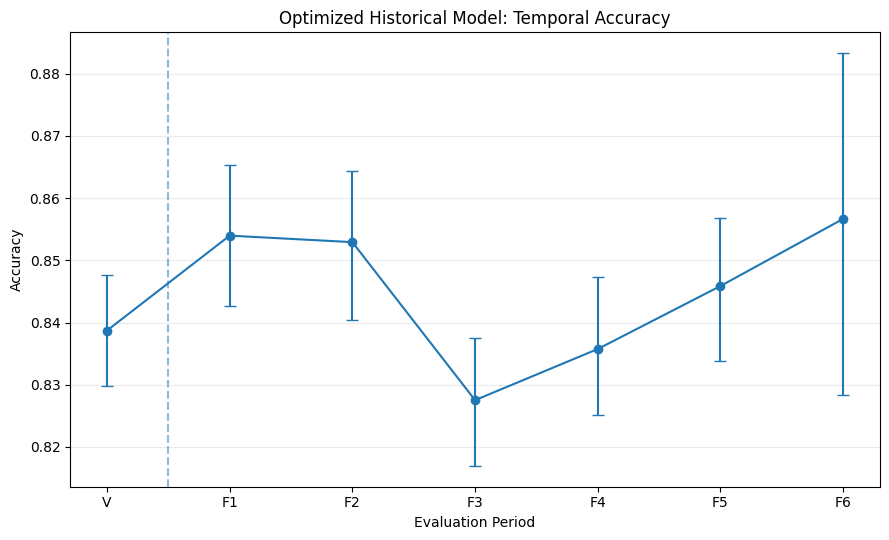

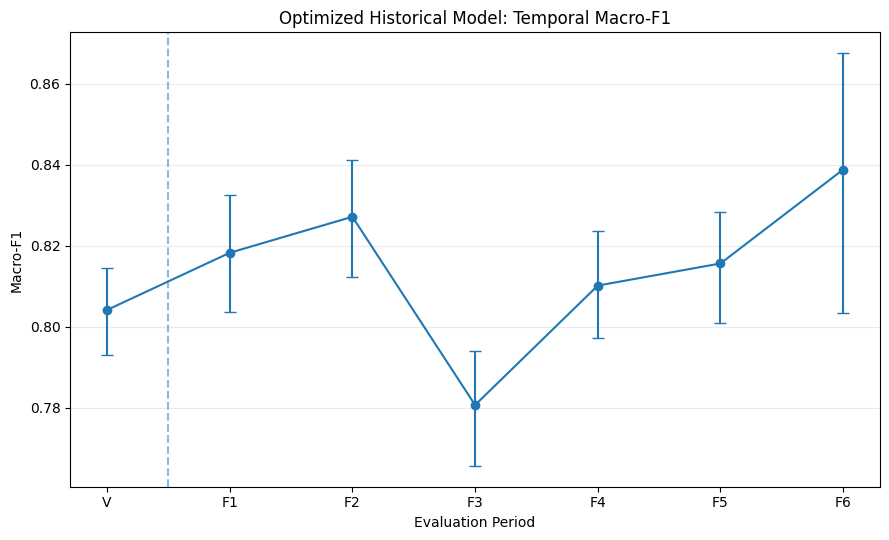

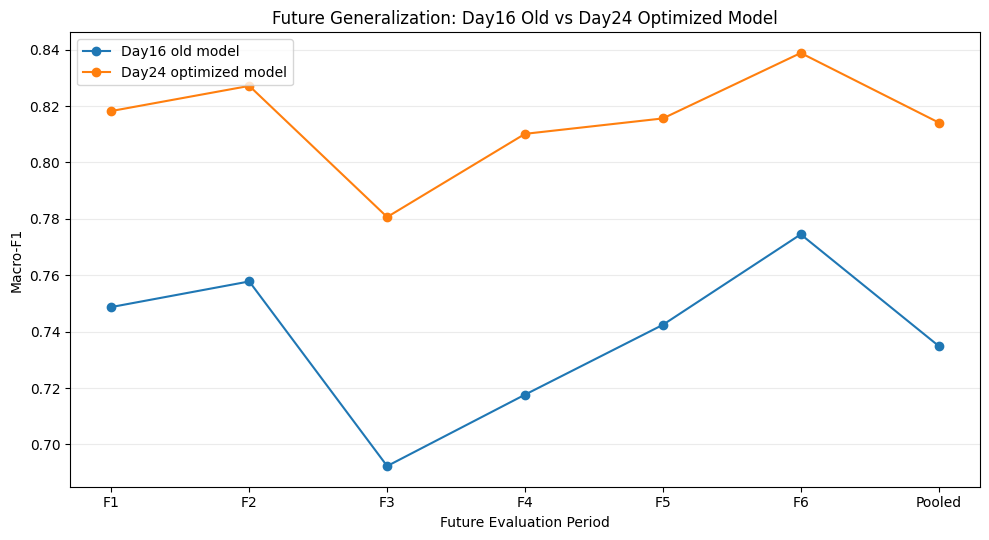

------------------------------------------------------------------------------------------------------------------------
SAVED DAY24 CORE FIGURES
------------------------------------------------------------------------------------------------------------------------
Temporal accuracy      : /content/drive/MyDrive/FinGPT_Project/results/day24/figures/optimized_temporal_accuracy_ci.png
Temporal Macro-F1      : /content/drive/MyDrive/FinGPT_Project/results/day24/figures/optimized_temporal_macro_f1_ci.png
Old vs optimized       : /content/drive/MyDrive/FinGPT_Project/results/day24/figures/old_vs_optimized_future_macro_f1.png
Figure manifest        : /content/drive/MyDrive/FinGPT_Project/results/day24/figures/day24_figure_manifest.csv
DAY24 CORE RESULT FIGURES: PASS
NO MODEL INFERENCE PERFORMED
NO NEW STATISTICAL TESTS PERFORMED
READY — CLASS-SPECIFIC TEMPORAL DIAGNOSIS FIGURES


In [9]:
# ==================================================================================================
# DAY 24 — CELL 12
# CORE RESULT FIGURES
# TEMPORAL GENERALIZATION + OLD VS OPTIMIZED MODEL
# NO MODEL INFERENCE / NO NEW STATISTICAL TESTS
# ==================================================================================================

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------------------------------
# Canonical artifact paths
# --------------------------------------------------------------------------------------------------

DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH = (
    DAY24_RESULTS_ROOT
    / "bootstrap_absolute_metric_ci.csv"
)

DAY24_PAIRED_COMPARISON_PATH = (
    DAY24_RESULTS_ROOT
    / "paired_old_vs_new_metric_comparison.csv"
)

DAY24_FUTURE_WINDOW_METRICS_PATH = (
    DAY24_RESULTS_ROOT
    / "future_window_metrics.csv"
)

DAY24_FIGURE_ROOT = (
    DAY24_RESULTS_ROOT
    / "figures"
)

DAY24_FIGURE_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

# --------------------------------------------------------------------------------------------------
# Load frozen result artifacts
# --------------------------------------------------------------------------------------------------

absolute_ci = pd.read_csv(
    DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH
)

paired_comparison = pd.read_csv(
    DAY24_PAIRED_COMPARISON_PATH
)

future_metrics = pd.read_csv(
    DAY24_FUTURE_WINDOW_METRICS_PATH
)

# --------------------------------------------------------------------------------------------------
# Expected period ordering
# --------------------------------------------------------------------------------------------------

TEMPORAL_ORDER = [
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

FUTURE_ORDER = [
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

PAIR_ORDER = [
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
    "Future_Pooled",
]

# --------------------------------------------------------------------------------------------------
# Integrity checks
# --------------------------------------------------------------------------------------------------

figure_checks = {
    "absolute_ci_exists":
        DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH.exists(),

    "paired_comparison_exists":
        DAY24_PAIRED_COMPARISON_PATH.exists(),

    "future_metrics_exists":
        DAY24_FUTURE_WINDOW_METRICS_PATH.exists(),

    "temporal_periods_complete":
        set(TEMPORAL_ORDER).issubset(
            set(
                absolute_ci["period"]
                .astype(str)
                .unique()
            )
        ),

    "paired_periods_complete":
        set(PAIR_ORDER).issubset(
            set(
                paired_comparison["period"]
                .astype(str)
                .unique()
            )
        ),
}

print("=" * 120)
print("DAY 24 — CORE RESULT FIGURES")
print("=" * 120)

print("FIGURE INPUT CHECKS")
print("-" * 120)

for name, passed in figure_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    figure_checks.values()
):

    failed = [
        name
        for name, passed
        in figure_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Figure input audit failed:\n"
        + "\n".join(failed)
    )

# ==================================================================================================
# FIGURE 1
# OPTIMIZED MODEL — ACCURACY V → F1–F6
# ==================================================================================================

accuracy_ci = (
    absolute_ci[
        absolute_ci["metric"]
        == "accuracy"
    ]
    .copy()
)

accuracy_ci["period"] = pd.Categorical(
    accuracy_ci["period"],
    categories=TEMPORAL_ORDER,
    ordered=True,
)

accuracy_ci = (
    accuracy_ci
    .sort_values("period")
    .reset_index(drop=True)
)

x = np.arange(
    len(accuracy_ci)
)

y = (
    accuracy_ci["estimate"]
    .to_numpy()
)

lower_error = (
    y
    - accuracy_ci["ci_lower"]
    .to_numpy()
)

upper_error = (
    accuracy_ci["ci_upper"]
    .to_numpy()
    - y
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.errorbar(
    x,
    y,
    yerr=[
        lower_error,
        upper_error,
    ],
    marker="o",
    capsize=4,
)

ax.axvline(
    x=0.5,
    linestyle="--",
    alpha=0.5,
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    accuracy_ci["period"]
)

ax.set_xlabel(
    "Evaluation Period"
)

ax.set_ylabel(
    "Accuracy"
)

ax.set_title(
    "Optimized Historical Model: Temporal Accuracy"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

DAY24_ACCURACY_CURVE_PATH = (
    DAY24_FIGURE_ROOT
    / "optimized_temporal_accuracy_ci.png"
)

fig.savefig(
    DAY24_ACCURACY_CURVE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ==================================================================================================
# FIGURE 2
# OPTIMIZED MODEL — MACRO-F1 V → F1–F6
# ==================================================================================================

macro_ci = (
    absolute_ci[
        absolute_ci["metric"]
        == "macro_f1"
    ]
    .copy()
)

macro_ci["period"] = pd.Categorical(
    macro_ci["period"],
    categories=TEMPORAL_ORDER,
    ordered=True,
)

macro_ci = (
    macro_ci
    .sort_values("period")
    .reset_index(drop=True)
)

x = np.arange(
    len(macro_ci)
)

y = (
    macro_ci["estimate"]
    .to_numpy()
)

lower_error = (
    y
    - macro_ci["ci_lower"]
    .to_numpy()
)

upper_error = (
    macro_ci["ci_upper"]
    .to_numpy()
    - y
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.errorbar(
    x,
    y,
    yerr=[
        lower_error,
        upper_error,
    ],
    marker="o",
    capsize=4,
)

ax.axvline(
    x=0.5,
    linestyle="--",
    alpha=0.5,
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    macro_ci["period"]
)

ax.set_xlabel(
    "Evaluation Period"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Optimized Historical Model: Temporal Macro-F1"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

DAY24_MACRO_F1_CURVE_PATH = (
    DAY24_FIGURE_ROOT
    / "optimized_temporal_macro_f1_ci.png"
)

fig.savefig(
    DAY24_MACRO_F1_CURVE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ==================================================================================================
# FIGURE 3
# DAY16 OLD VS DAY24 OPTIMIZED — MACRO-F1
# ==================================================================================================

paired_macro = (
    paired_comparison[
        paired_comparison["metric"]
        == "macro_f1"
    ]
    .copy()
)

paired_macro["period"] = pd.Categorical(
    paired_macro["period"],
    categories=PAIR_ORDER,
    ordered=True,
)

paired_macro = (
    paired_macro
    .sort_values("period")
    .reset_index(drop=True)
)

x = np.arange(
    len(paired_macro)
)

fig, ax = plt.subplots(
    figsize=(10, 5.5)
)

ax.plot(
    x,
    paired_macro[
        "old_estimate"
    ],
    marker="o",
    label="Day16 old model",
)

ax.plot(
    x,
    paired_macro[
        "new_estimate"
    ],
    marker="o",
    label="Day24 optimized model",
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    [
        "F1",
        "F2",
        "F3",
        "F4",
        "F5",
        "F6",
        "Pooled",
    ]
)

ax.set_xlabel(
    "Future Evaluation Period"
)

ax.set_ylabel(
    "Macro-F1"
)

ax.set_title(
    "Future Generalization: Day16 Old vs Day24 Optimized Model"
)

ax.legend()

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

DAY24_OLD_NEW_MACRO_F1_PATH = (
    DAY24_FIGURE_ROOT
    / "old_vs_optimized_future_macro_f1.png"
)

fig.savefig(
    DAY24_OLD_NEW_MACRO_F1_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ==================================================================================================
# SAVE FIGURE MANIFEST
# ==================================================================================================

figure_manifest = pd.DataFrame([
    {
        "figure":
            "optimized_temporal_accuracy_ci",

        "path":
            str(
                DAY24_ACCURACY_CURVE_PATH
            ),
    },
    {
        "figure":
            "optimized_temporal_macro_f1_ci",

        "path":
            str(
                DAY24_MACRO_F1_CURVE_PATH
            ),
    },
    {
        "figure":
            "old_vs_optimized_future_macro_f1",

        "path":
            str(
                DAY24_OLD_NEW_MACRO_F1_PATH
            ),
    },
])

DAY24_FIGURE_MANIFEST_PATH = (
    DAY24_FIGURE_ROOT
    / "day24_figure_manifest.csv"
)

figure_manifest.to_csv(
    DAY24_FIGURE_MANIFEST_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("SAVED DAY24 CORE FIGURES")
print("-" * 120)

print(
    f"Temporal accuracy      : "
    f"{DAY24_ACCURACY_CURVE_PATH}"
)

print(
    f"Temporal Macro-F1      : "
    f"{DAY24_MACRO_F1_CURVE_PATH}"
)

print(
    f"Old vs optimized       : "
    f"{DAY24_OLD_NEW_MACRO_F1_PATH}"
)

print(
    f"Figure manifest        : "
    f"{DAY24_FIGURE_MANIFEST_PATH}"
)

print("=" * 120)
print("DAY24 CORE RESULT FIGURES: PASS")
print("NO MODEL INFERENCE PERFORMED")
print("NO NEW STATISTICAL TESTS PERFORMED")
print("READY — CLASS-SPECIFIC TEMPORAL DIAGNOSIS FIGURES")
print("=" * 120)

DAY 24 — CLASS-SPECIFIC TEMPORAL DIAGNOSIS
DIAGNOSIS INPUT CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — absolute_ci_exists
PASS   — delta_ci_exists
PASS   — confusion_exists
PASS   — all_recall_metrics_present
PASS   — all_temporal_periods_present
PASS   — all_future_periods_in_delta


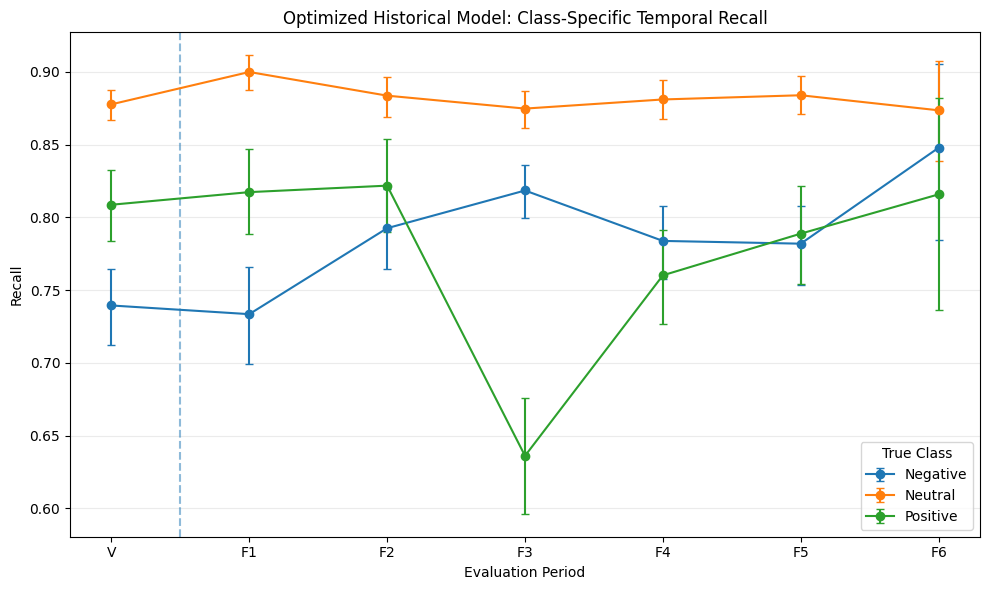

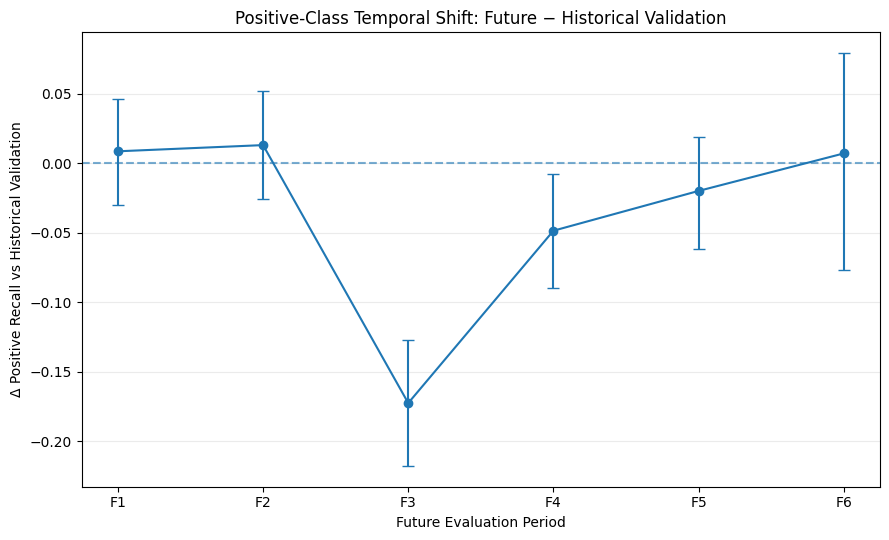

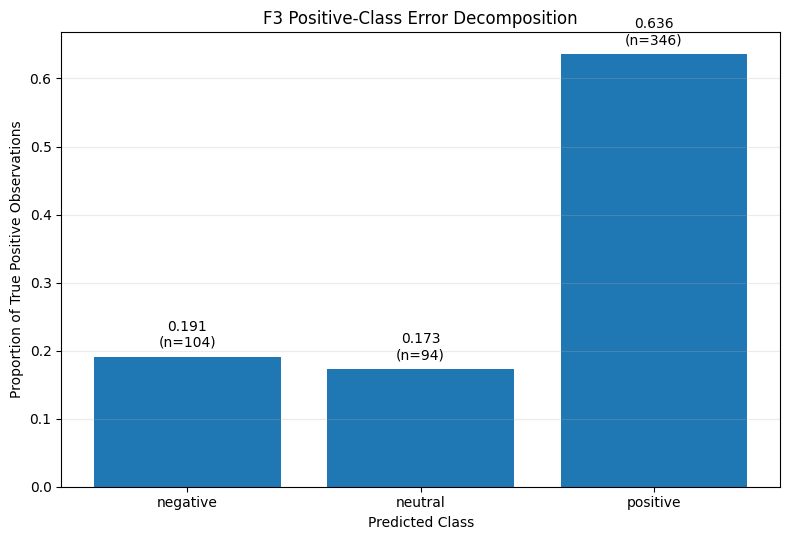

------------------------------------------------------------------------------------------------------------------------
POSITIVE RECALL: FUTURE − HISTORICAL VALIDATION
------------------------------------------------------------------------------------------------------------------------
period  delta_F_minus_V  ci_lower  ci_upper  ci_excludes_zero                interpretation
    F1         0.008669 -0.029760  0.046241             False not_distinguishable_from_zero
    F2         0.013128 -0.025641  0.052048             False not_distinguishable_from_zero
    F3        -0.172624 -0.217991 -0.127190              True       significant_degradation
    F4        -0.048524 -0.090106 -0.007388              True       significant_degradation
    F5        -0.019869 -0.061982  0.018670             False not_distinguishable_from_zero
    F6         0.007136 -0.076556  0.079462             False not_distinguishable_from_zero
------------------------------------------------------------------

In [10]:
# ==================================================================================================
# DAY 24 — CELL 13
# CLASS-SPECIFIC TEMPORAL DIAGNOSIS
# FOCUS: F3 POSITIVE-RECALL DEGRADATION
# NO MODEL INFERENCE / NO NEW STATISTICAL TESTS
# ==================================================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# --------------------------------------------------------------------------------------------------
# Canonical frozen artifact paths
# --------------------------------------------------------------------------------------------------

DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH = (
    DAY24_RESULTS_ROOT
    / "bootstrap_absolute_metric_ci.csv"
)

DAY24_BOOTSTRAP_DELTA_CI_PATH = (
    DAY24_RESULTS_ROOT
    / "bootstrap_delta_vs_validation_ci.csv"
)

DAY24_FUTURE_CONFUSION_PATH = (
    DAY24_RESULTS_ROOT
    / "future_confusion_matrices.csv"
)

DAY24_CLASS_DIAGNOSIS_ROOT = (
    DAY24_RESULTS_ROOT
    / "figures"
    / "class_specific_diagnosis"
)

DAY24_CLASS_DIAGNOSIS_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

# --------------------------------------------------------------------------------------------------
# Load already-computed frozen statistics
# --------------------------------------------------------------------------------------------------

absolute_ci = pd.read_csv(
    DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH
)

delta_ci = pd.read_csv(
    DAY24_BOOTSTRAP_DELTA_CI_PATH
)

future_confusion = pd.read_csv(
    DAY24_FUTURE_CONFUSION_PATH
)

TEMPORAL_ORDER = [
    "V",
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

FUTURE_ORDER = [
    "F1",
    "F2",
    "F3",
    "F4",
    "F5",
    "F6",
]

RECALL_METRICS = [
    "negative_recall",
    "neutral_recall",
    "positive_recall",
]

# --------------------------------------------------------------------------------------------------
# Input integrity checks
# --------------------------------------------------------------------------------------------------

diagnosis_checks = {
    "absolute_ci_exists":
        DAY24_BOOTSTRAP_ABSOLUTE_CI_PATH.exists(),

    "delta_ci_exists":
        DAY24_BOOTSTRAP_DELTA_CI_PATH.exists(),

    "confusion_exists":
        DAY24_FUTURE_CONFUSION_PATH.exists(),

    "all_recall_metrics_present":
        set(RECALL_METRICS).issubset(
            set(
                absolute_ci["metric"]
                .astype(str)
                .unique()
            )
        ),

    "all_temporal_periods_present":
        set(TEMPORAL_ORDER).issubset(
            set(
                absolute_ci["period"]
                .astype(str)
                .unique()
            )
        ),

    "all_future_periods_in_delta":
        set(FUTURE_ORDER).issubset(
            set(
                delta_ci["period"]
                .astype(str)
                .unique()
            )
        ),
}

print("=" * 120)
print("DAY 24 — CLASS-SPECIFIC TEMPORAL DIAGNOSIS")
print("=" * 120)

print("DIAGNOSIS INPUT CHECKS")
print("-" * 120)

for name, passed in diagnosis_checks.items():
    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(diagnosis_checks.values()):

    failed = [
        name
        for name, passed
        in diagnosis_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Class-diagnosis input audit failed:\n"
        + "\n".join(failed)
    )

# ==================================================================================================
# FIGURE 1
# V → F1–F6 PER-CLASS RECALL WITH 95% BOOTSTRAP CI
# ==================================================================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

x = np.arange(
    len(TEMPORAL_ORDER)
)

for metric in RECALL_METRICS:

    sub = (
        absolute_ci[
            absolute_ci["metric"]
            == metric
        ]
        .copy()
    )

    sub["period"] = pd.Categorical(
        sub["period"],
        categories=TEMPORAL_ORDER,
        ordered=True,
    )

    sub = (
        sub
        .sort_values("period")
        .reset_index(drop=True)
    )

    y = (
        sub["estimate"]
        .to_numpy()
    )

    lower_error = (
        y
        - sub["ci_lower"]
        .to_numpy()
    )

    upper_error = (
        sub["ci_upper"]
        .to_numpy()
        - y
    )

    label = (
        metric
        .replace("_recall", "")
        .capitalize()
    )

    ax.errorbar(
        x,
        y,
        yerr=[
            lower_error,
            upper_error,
        ],
        marker="o",
        capsize=3,
        label=label,
    )

ax.axvline(
    x=0.5,
    linestyle="--",
    alpha=0.5,
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    TEMPORAL_ORDER
)

ax.set_xlabel(
    "Evaluation Period"
)

ax.set_ylabel(
    "Recall"
)

ax.set_title(
    "Optimized Historical Model: Class-Specific Temporal Recall"
)

ax.legend(
    title="True Class"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

DAY24_CLASS_RECALL_CURVE_PATH = (
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "class_specific_temporal_recall_ci.png"
)

fig.savefig(
    DAY24_CLASS_RECALL_CURVE_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ==================================================================================================
# FIGURE 2
# POSITIVE RECALL DELTA: Ft − V
# ==================================================================================================

positive_delta = (
    delta_ci[
        delta_ci["metric"]
        == "positive_recall"
    ]
    .copy()
)

positive_delta["period"] = pd.Categorical(
    positive_delta["period"],
    categories=FUTURE_ORDER,
    ordered=True,
)

positive_delta = (
    positive_delta
    .sort_values("period")
    .reset_index(drop=True)
)

x = np.arange(
    len(positive_delta)
)

y = (
    positive_delta[
        "delta_F_minus_V"
    ]
    .to_numpy()
)

lower_error = (
    y
    - positive_delta[
        "ci_lower"
    ].to_numpy()
)

upper_error = (
    positive_delta[
        "ci_upper"
    ].to_numpy()
    - y
)

fig, ax = plt.subplots(
    figsize=(9, 5.5)
)

ax.errorbar(
    x,
    y,
    yerr=[
        lower_error,
        upper_error,
    ],
    marker="o",
    capsize=4,
)

ax.axhline(
    y=0,
    linestyle="--",
    alpha=0.6,
)

ax.set_xticks(
    x
)

ax.set_xticklabels(
    FUTURE_ORDER
)

ax.set_xlabel(
    "Future Evaluation Period"
)

ax.set_ylabel(
    "Δ Positive Recall vs Historical Validation"
)

ax.set_title(
    "Positive-Class Temporal Shift: Future − Historical Validation"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

fig.tight_layout()

DAY24_POSITIVE_RECALL_DELTA_PATH = (
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "positive_recall_delta_vs_validation_ci.png"
)

fig.savefig(
    DAY24_POSITIVE_RECALL_DELTA_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ==================================================================================================
# F3 POSITIVE-CLASS CONFUSION DECOMPOSITION
# ==================================================================================================

f3_positive = (
    future_confusion[
        (
            future_confusion["period"]
            .astype(str)
            == "F3"
        )
        &
        (
            future_confusion["true_label"]
            .astype(str)
            == "positive"
        )
    ]
    .copy()
)

prediction_order = [
    "negative",
    "neutral",
    "positive",
]

f3_positive["predicted_label"] = pd.Categorical(
    f3_positive["predicted_label"],
    categories=prediction_order,
    ordered=True,
)

f3_positive = (
    f3_positive
    .sort_values("predicted_label")
    .reset_index(drop=True)
)

f3_positive_total = int(
    f3_positive["count"].sum()
)

f3_positive[
    "proportion"
] = (
    f3_positive["count"]
    / f3_positive_total
)

# --------------------------------------------------------------------------------------------------
# FIGURE 3
# F3 TRUE POSITIVE → PREDICTED CLASS
# --------------------------------------------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(8, 5.5)
)

ax.bar(
    f3_positive[
        "predicted_label"
    ].astype(str),
    f3_positive[
        "proportion"
    ],
)

ax.set_xlabel(
    "Predicted Class"
)

ax.set_ylabel(
    "Proportion of True Positive Observations"
)

ax.set_title(
    "F3 Positive-Class Error Decomposition"
)

ax.grid(
    axis="y",
    alpha=0.25,
)

for i, row in f3_positive.iterrows():

    ax.text(
        i,
        row["proportion"] + 0.01,
        f"{row['proportion']:.3f}\n(n={int(row['count'])})",
        ha="center",
        va="bottom",
    )

fig.tight_layout()

DAY24_F3_POSITIVE_CONFUSION_PATH = (
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "f3_positive_error_decomposition.png"
)

fig.savefig(
    DAY24_F3_POSITIVE_CONFUSION_PATH,
    dpi=300,
    bbox_inches="tight",
)

plt.show()
plt.close(fig)

# ==================================================================================================
# CONSOLE DIAGNOSTIC TABLE
# ==================================================================================================

print("-" * 120)
print("POSITIVE RECALL: FUTURE − HISTORICAL VALIDATION")
print("-" * 120)

print(
    positive_delta[
        [
            "period",
            "delta_F_minus_V",
            "ci_lower",
            "ci_upper",
            "ci_excludes_zero",
            "interpretation",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

print("-" * 120)
print("F3 TRUE-POSITIVE PREDICTION DESTINATIONS")
print("-" * 120)

print(
    f3_positive[
        [
            "predicted_label",
            "count",
            "proportion",
        ]
    ].to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}",
    )
)

# --------------------------------------------------------------------------------------------------
# Mechanism summary based only on already-established statistics
# --------------------------------------------------------------------------------------------------

f3_positive_row = positive_delta[
    positive_delta["period"]
    .astype(str)
    == "F3"
].iloc[0]

f4_positive_row = positive_delta[
    positive_delta["period"]
    .astype(str)
    == "F4"
].iloc[0]

f3_main_error_destination = (
    f3_positive[
        f3_positive["predicted_label"]
        .astype(str)
        != "positive"
    ]
    .sort_values(
        "count",
        ascending=False,
    )
    .iloc[0][
        "predicted_label"
    ]
)

print("-" * 120)
print("CLASS-SPECIFIC DIAGNOSIS SUMMARY")
print("-" * 120)

print(
    f"F3 positive-recall delta : "
    f"{f3_positive_row['delta_F_minus_V']:.6f} "
    f"[{f3_positive_row['ci_lower']:.6f}, "
    f"{f3_positive_row['ci_upper']:.6f}]"
)

print(
    f"F4 positive-recall delta : "
    f"{f4_positive_row['delta_F_minus_V']:.6f} "
    f"[{f4_positive_row['ci_lower']:.6f}, "
    f"{f4_positive_row['ci_upper']:.6f}]"
)

print(
    f"F3 dominant error route  : "
    f"positive → {f3_main_error_destination}"
)

# --------------------------------------------------------------------------------------------------
# Save diagnosis tables
# --------------------------------------------------------------------------------------------------

DAY24_POSITIVE_DELTA_TABLE_PATH = (
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "positive_recall_delta_vs_validation.csv"
)

DAY24_F3_POSITIVE_CONFUSION_TABLE_PATH = (
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "f3_positive_error_decomposition.csv"
)

positive_delta.to_csv(
    DAY24_POSITIVE_DELTA_TABLE_PATH,
    index=False,
)

f3_positive.to_csv(
    DAY24_F3_POSITIVE_CONFUSION_TABLE_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Figure manifest
# --------------------------------------------------------------------------------------------------

class_diagnosis_manifest = pd.DataFrame([
    {
        "figure":
            "class_specific_temporal_recall_ci",

        "path":
            str(
                DAY24_CLASS_RECALL_CURVE_PATH
            ),
    },
    {
        "figure":
            "positive_recall_delta_vs_validation_ci",

        "path":
            str(
                DAY24_POSITIVE_RECALL_DELTA_PATH
            ),
    },
    {
        "figure":
            "f3_positive_error_decomposition",

        "path":
            str(
                DAY24_F3_POSITIVE_CONFUSION_PATH
            ),
    },
])

DAY24_CLASS_DIAGNOSIS_MANIFEST_PATH = (
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "class_specific_diagnosis_manifest.csv"
)

class_diagnosis_manifest.to_csv(
    DAY24_CLASS_DIAGNOSIS_MANIFEST_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Final output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("SAVED CLASS-SPECIFIC DIAGNOSIS ARTIFACTS")
print("-" * 120)

print(
    f"Class recall curve     : "
    f"{DAY24_CLASS_RECALL_CURVE_PATH}"
)

print(
    f"Positive-recall delta  : "
    f"{DAY24_POSITIVE_RECALL_DELTA_PATH}"
)

print(
    f"F3 positive errors     : "
    f"{DAY24_F3_POSITIVE_CONFUSION_PATH}"
)

print(
    f"Diagnosis manifest     : "
    f"{DAY24_CLASS_DIAGNOSIS_MANIFEST_PATH}"
)

print("=" * 120)
print("DAY24 CLASS-SPECIFIC TEMPORAL DIAGNOSIS: PASS")
print("NO MODEL INFERENCE PERFORMED")
print("NO NEW STATISTICAL TESTS PERFORMED")
print("READY — DAY24 SCIENTIFIC INTEGRATION")
print("=" * 120)

In [11]:
# ==================================================================================================
# DAY 24 — CELL 14
# SCIENTIFIC INTEGRATION
# FINAL EVIDENCE SYNTHESIS — NO NEW STATISTICAL TESTS / NO MODEL INFERENCE
# ==================================================================================================

import json
from datetime import datetime, timezone

import pandas as pd

# --------------------------------------------------------------------------------------------------
# Load canonical Day24 result artifacts
# --------------------------------------------------------------------------------------------------

temporal_performance = pd.read_csv(
    DAY24_RESULTS_ROOT
    / "temporal_performance_curve.csv"
)

delta_ci = pd.read_csv(
    DAY24_RESULTS_ROOT
    / "bootstrap_delta_vs_validation_ci.csv"
)

paired_comparison = pd.read_csv(
    DAY24_RESULTS_ROOT
    / "paired_old_vs_new_metric_comparison.csv"
)

correctness_transitions = pd.read_csv(
    DAY24_RESULTS_ROOT
    / "paired_old_vs_new_correctness_transitions.csv"
)

positive_delta = pd.read_csv(
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "positive_recall_delta_vs_validation.csv"
)

f3_positive_errors = pd.read_csv(
    DAY24_CLASS_DIAGNOSIS_ROOT
    / "f3_positive_error_decomposition.csv"
)

# --------------------------------------------------------------------------------------------------
# Helper
# --------------------------------------------------------------------------------------------------

def get_row(df, **conditions):

    mask = pd.Series(
        True,
        index=df.index,
    )

    for column, value in conditions.items():

        mask &= (
            df[column]
            .astype(str)
            == str(value)
        )

    result = df[
        mask
    ]

    if len(result) != 1:

        raise RuntimeError(
            f"DAY 24 HARD STOP — Expected exactly one row for {conditions}, "
            f"found {len(result)}."
        )

    return result.iloc[0]


# --------------------------------------------------------------------------------------------------
# Recover key frozen results
# --------------------------------------------------------------------------------------------------

V = get_row(
    temporal_performance,
    period="V",
)

F3 = get_row(
    temporal_performance,
    period="F3",
)

F6 = get_row(
    temporal_performance,
    period="F6",
)

f3_macro_delta = get_row(
    delta_ci,
    period="F3",
    metric="macro_f1",
)

f3_accuracy_delta = get_row(
    delta_ci,
    period="F3",
    metric="accuracy",
)

f3_positive_delta = get_row(
    delta_ci,
    period="F3",
    metric="positive_recall",
)

f4_positive_delta = get_row(
    delta_ci,
    period="F4",
    metric="positive_recall",
)

f3_negative_delta = get_row(
    delta_ci,
    period="F3",
    metric="negative_recall",
)

pooled_accuracy_improvement = get_row(
    paired_comparison,
    period="Future_Pooled",
    metric="accuracy",
)

pooled_macro_improvement = get_row(
    paired_comparison,
    period="Future_Pooled",
    metric="macro_f1",
)

pooled_negative_improvement = get_row(
    paired_comparison,
    period="Future_Pooled",
    metric="negative_recall",
)

pooled_positive_improvement = get_row(
    paired_comparison,
    period="Future_Pooled",
    metric="positive_recall",
)

pooled_transition = get_row(
    correctness_transitions,
    period="Future_Pooled",
)

# --------------------------------------------------------------------------------------------------
# Determine F3 positive error routing
# --------------------------------------------------------------------------------------------------

f3_positive_error_only = (
    f3_positive_errors[
        f3_positive_errors[
            "predicted_label"
        ].astype(str)
        != "positive"
    ]
    .copy()
)

dominant_error_row = (
    f3_positive_error_only
    .sort_values(
        "count",
        ascending=False,
    )
    .iloc[0]
)

dominant_error_route = (
    f"positive→{dominant_error_row['predicted_label']}"
)

# --------------------------------------------------------------------------------------------------
# Scientific integration checks
# --------------------------------------------------------------------------------------------------

integration_checks = {
    "validation_accuracy_expected":
        abs(
            float(V["accuracy"])
            - 0.8387096774
        ) < 1e-6,

    "validation_macro_f1_expected":
        abs(
            float(V["macro_f1"])
            - 0.8041298160
        ) < 1e-6,

    "f3_macro_f1_degradation_significant":
        (
            float(
                f3_macro_delta[
                    "ci_upper"
                ]
            )
            < 0
        ),

    "f3_accuracy_not_significantly_lower":
        (
            float(
                f3_accuracy_delta[
                    "ci_lower"
                ]
            )
            <= 0
            <=
            float(
                f3_accuracy_delta[
                    "ci_upper"
                ]
            )
        ),

    "f3_positive_recall_degradation_significant":
        (
            float(
                f3_positive_delta[
                    "ci_upper"
                ]
            )
            < 0
        ),

    "f4_positive_recall_degradation_significant":
        (
            float(
                f4_positive_delta[
                    "ci_upper"
                ]
            )
            < 0
        ),

    "f3_negative_recall_improvement_significant":
        (
            float(
                f3_negative_delta[
                    "ci_lower"
                ]
            )
            > 0
        ),

    "pooled_accuracy_old_to_new_improvement_significant":
        (
            float(
                pooled_accuracy_improvement[
                    "ci_lower"
                ]
            )
            > 0
        ),

    "pooled_macro_old_to_new_improvement_significant":
        (
            float(
                pooled_macro_improvement[
                    "ci_lower"
                ]
            )
            > 0
        ),

    "net_future_accuracy_gain_positive":
        int(
            pooled_transition[
                "net_accuracy_gain_count"
            ]
        ) > 0,
}

print("=" * 120)
print("DAY 24 — SCIENTIFIC INTEGRATION")
print("=" * 120)

print("INTEGRATION CHECKS")
print("-" * 120)

for name, passed in integration_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

if not all(
    integration_checks.values()
):

    failed = [
        name
        for name, passed
        in integration_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Scientific integration check failed:\n"
        + "\n".join(failed)
    )

# --------------------------------------------------------------------------------------------------
# Formal scientific conclusions
# --------------------------------------------------------------------------------------------------

conclusions = {
    "primary_question":
        (
            "After repairing historical training adequacy, "
            "does temporal degradation persist in Future F1-F6?"
        ),

    "conclusion_1_historical_training_repair":
        (
            "The optimized historical model substantially improves Future performance "
            "relative to the Day16 historical baseline across all six Future windows."
        ),

    "conclusion_2_aggregate_temporal_generalization":
        (
            "Broad aggregate temporal degradation largely disappears after optimization. "
            "Future pooled performance is approximately comparable to or slightly above "
            "Historical Validation at the point-estimate level."
        ),

    "conclusion_3_residual_f3_failure":
        (
            "A localized residual temporal degradation remains in F3: "
            "Macro-F1 is significantly lower than Historical Validation, "
            "although the corresponding accuracy contrast is not distinguishable from zero."
        ),

    "conclusion_4_class_specific_mechanism":
        (
            "The F3 degradation is class-specific rather than global. "
            "Positive recall falls sharply, while negative recall significantly improves "
            "and neutral recall remains comparatively stable."
        ),

    "conclusion_5_error_direction":
        (
            "Among F3 true-positive observations, the dominant misclassification route "
            "is positive-to-negative rather than positive-to-neutral."
        ),

    "conclusion_6_f4_residual":
        (
            "F4 retains a smaller but statistically supported positive-recall degradation, "
            "while F5 and F6 do not show statistically supported positive-recall degradation."
        ),

    "overall_interpretation":
        (
            "The Day16 temporal degradation signal was partly attributable to insufficient "
            "historical model optimization. After optimization, most aggregate degradation "
            "is repaired, but a localized class-specific distribution-shift vulnerability "
            "remains, concentrated most strongly in F3 positive sentiment."
        ),
}

# --------------------------------------------------------------------------------------------------
# Quantitative evidence table
# --------------------------------------------------------------------------------------------------

scientific_evidence_rows = [
    {
        "result":
            "Historical Validation accuracy",
        "estimate":
            float(V["accuracy"]),
        "ci_lower":
            None,
        "ci_upper":
            None,
    },
    {
        "result":
            "Historical Validation macro-F1",
        "estimate":
            float(V["macro_f1"]),
        "ci_lower":
            None,
        "ci_upper":
            None,
    },
    {
        "result":
            "F3 accuracy minus V",
        "estimate":
            float(
                f3_accuracy_delta[
                    "delta_F_minus_V"
                ]
            ),
        "ci_lower":
            float(
                f3_accuracy_delta[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                f3_accuracy_delta[
                    "ci_upper"
                ]
            ),
    },
    {
        "result":
            "F3 macro-F1 minus V",
        "estimate":
            float(
                f3_macro_delta[
                    "delta_F_minus_V"
                ]
            ),
        "ci_lower":
            float(
                f3_macro_delta[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                f3_macro_delta[
                    "ci_upper"
                ]
            ),
    },
    {
        "result":
            "F3 positive recall minus V",
        "estimate":
            float(
                f3_positive_delta[
                    "delta_F_minus_V"
                ]
            ),
        "ci_lower":
            float(
                f3_positive_delta[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                f3_positive_delta[
                    "ci_upper"
                ]
            ),
    },
    {
        "result":
            "F3 negative recall minus V",
        "estimate":
            float(
                f3_negative_delta[
                    "delta_F_minus_V"
                ]
            ),
        "ci_lower":
            float(
                f3_negative_delta[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                f3_negative_delta[
                    "ci_upper"
                ]
            ),
    },
    {
        "result":
            "F4 positive recall minus V",
        "estimate":
            float(
                f4_positive_delta[
                    "delta_F_minus_V"
                ]
            ),
        "ci_lower":
            float(
                f4_positive_delta[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                f4_positive_delta[
                    "ci_upper"
                ]
            ),
    },
    {
        "result":
            "Pooled Future accuracy improvement vs Day16",
        "estimate":
            float(
                pooled_accuracy_improvement[
                    "delta_new_minus_old"
                ]
            ),
        "ci_lower":
            float(
                pooled_accuracy_improvement[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                pooled_accuracy_improvement[
                    "ci_upper"
                ]
            ),
    },
    {
        "result":
            "Pooled Future macro-F1 improvement vs Day16",
        "estimate":
            float(
                pooled_macro_improvement[
                    "delta_new_minus_old"
                ]
            ),
        "ci_lower":
            float(
                pooled_macro_improvement[
                    "ci_lower"
                ]
            ),
        "ci_upper":
            float(
                pooled_macro_improvement[
                    "ci_upper"
                ]
            ),
    },
]

scientific_evidence_df = pd.DataFrame(
    scientific_evidence_rows
)

# --------------------------------------------------------------------------------------------------
# Formal Day24 scientific summary JSON
# --------------------------------------------------------------------------------------------------

DAY24_SCIENTIFIC_SUMMARY_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_final_scientific_summary.json"
)

DAY24_SCIENTIFIC_EVIDENCE_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_final_scientific_evidence.csv"
)

DAY24_SCIENTIFIC_NOTE_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_scientific_conclusion.txt"
)

scientific_summary = {
    "day":
        24,

    "artifact":
        "day24_final_scientific_summary",

    "status":
        "SCIENTIFIC_INTEGRATION_COMPLETE",

    "primary_question":
        conclusions[
            "primary_question"
        ],

    "historical_validation": {
        "n":
            int(V["n"]),

        "accuracy":
            float(V["accuracy"]),

        "macro_f1":
            float(V["macro_f1"]),
    },

    "optimized_future_pooled": {
        "n":
            20002,

        "accuracy":
            0.842516,

        "macro_f1":
            0.814179,
    },

    "residual_temporal_failure": {
        "primary_window":
            "F3",

        "f3_accuracy":
            float(F3["accuracy"]),

        "f3_macro_f1":
            float(F3["macro_f1"]),

        "f3_macro_f1_delta_vs_V":
            float(
                f3_macro_delta[
                    "delta_F_minus_V"
                ]
            ),

        "f3_macro_f1_delta_ci95": [
            float(
                f3_macro_delta[
                    "ci_lower"
                ]
            ),
            float(
                f3_macro_delta[
                    "ci_upper"
                ]
            ),
        ],

        "f3_positive_recall":
            float(
                F3[
                    "positive_recall"
                ]
            ),

        "f3_positive_recall_delta_vs_V":
            float(
                f3_positive_delta[
                    "delta_F_minus_V"
                ]
            ),

        "f3_positive_recall_delta_ci95": [
            float(
                f3_positive_delta[
                    "ci_lower"
                ]
            ),
            float(
                f3_positive_delta[
                    "ci_upper"
                ]
            ),
        ],

        "dominant_positive_error_route":
            dominant_error_route,

        "dominant_error_count":
            int(
                dominant_error_row[
                    "count"
                ]
            ),

        "dominant_error_proportion":
            float(
                dominant_error_row[
                    "proportion"
                ]
            ),
    },

    "old_vs_optimized_future": {
        "pooled_accuracy_delta":
            float(
                pooled_accuracy_improvement[
                    "delta_new_minus_old"
                ]
            ),

        "pooled_accuracy_delta_ci95": [
            float(
                pooled_accuracy_improvement[
                    "ci_lower"
                ]
            ),
            float(
                pooled_accuracy_improvement[
                    "ci_upper"
                ]
            ),
        ],

        "pooled_macro_f1_delta":
            float(
                pooled_macro_improvement[
                    "delta_new_minus_old"
                ]
            ),

        "pooled_macro_f1_delta_ci95": [
            float(
                pooled_macro_improvement[
                    "ci_lower"
                ]
            ),
            float(
                pooled_macro_improvement[
                    "ci_upper"
                ]
            ),
        ],

        "pooled_negative_recall_delta":
            float(
                pooled_negative_improvement[
                    "delta_new_minus_old"
                ]
            ),

        "pooled_positive_recall_delta":
            float(
                pooled_positive_improvement[
                    "delta_new_minus_old"
                ]
            ),

        "new_only_correct":
            int(
                pooled_transition[
                    "new_only_correct"
                ]
            ),

        "old_only_correct":
            int(
                pooled_transition[
                    "old_only_correct"
                ]
            ),

        "net_accuracy_gain_count":
            int(
                pooled_transition[
                    "net_accuracy_gain_count"
                ]
            ),
    },

    "scientific_conclusions":
        conclusions,

    "interpretation_boundary": {
        "supported":
            (
                "Historical optimization repairs most aggregate Future degradation, "
                "while statistically supported localized class-specific degradation remains."
            ),

        "not_yet_established":
            (
                "The causal source of the F3 positive-to-negative shift has not yet been identified. "
                "No claim is made here regarding whether the mechanism is lexical, topical, "
                "source-composition, event-driven, label-distribution, or semantic-regime shift."
            ),
    },

    "new_model_inference_performed":
        False,

    "new_statistical_tests_performed":
        False,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

with open(
    DAY24_SCIENTIFIC_SUMMARY_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        scientific_summary,
        f,
        indent=2,
        ensure_ascii=False,
    )

scientific_evidence_df.to_csv(
    DAY24_SCIENTIFIC_EVIDENCE_PATH,
    index=False,
)

# --------------------------------------------------------------------------------------------------
# Human-readable scientific conclusion
# --------------------------------------------------------------------------------------------------

scientific_note = f"""
DAY 24 — FINAL SCIENTIFIC INTERPRETATION

Primary question
----------------
After repairing historical training adequacy, does temporal degradation persist in Future F1–F6?

Main findings
-------------
1. Historical Validation:
   Accuracy = {float(V['accuracy']):.4f}
   Macro-F1 = {float(V['macro_f1']):.4f}

2. Optimized pooled Future:
   Accuracy = 0.8425
   Macro-F1 = 0.8142

3. Compared with the Day16 model, the optimized model improved pooled Future:
   Accuracy by {float(pooled_accuracy_improvement['delta_new_minus_old']):+.4f}
   Macro-F1 by {float(pooled_macro_improvement['delta_new_minus_old']):+.4f}

4. The original broad temporal degradation is therefore substantially reduced after adequate historical optimization.

5. A residual localized degradation remains in F3:
   Macro-F1 delta vs V =
   {float(f3_macro_delta['delta_F_minus_V']):+.4f}
   95% CI [
   {float(f3_macro_delta['ci_lower']):+.4f},
   {float(f3_macro_delta['ci_upper']):+.4f}
   ]

6. This F3 degradation is predominantly class-specific:
   Positive-recall delta vs V =
   {float(f3_positive_delta['delta_F_minus_V']):+.4f}
   95% CI [
   {float(f3_positive_delta['ci_lower']):+.4f},
   {float(f3_positive_delta['ci_upper']):+.4f}
   ]

7. Negative recall in F3 improves rather than deteriorates.

8. The dominant F3 positive-class error route is:
   {dominant_error_route}
   count = {int(dominant_error_row['count'])}
   proportion = {float(dominant_error_row['proportion']):.4f}

Scientific interpretation
-------------------------
The Day16 temporal degradation signal was partly attributable to insufficient
historical model optimization. Once historical training adequacy is repaired,
most aggregate Future degradation disappears. However, a localized,
class-specific temporal vulnerability remains, concentrated most strongly
in F3 positive sentiment.

Important limitation
--------------------
Day24 identifies the residual failure pattern, but does not establish its causal
mechanism. The F3 shift should therefore be treated as a diagnosis target for
subsequent source/topic/semantic/composition analysis rather than as evidence
for any specific cause.
""".strip()

with open(
    DAY24_SCIENTIFIC_NOTE_PATH,
    "w",
    encoding="utf-8",
) as f:

    f.write(
        scientific_note
    )

# --------------------------------------------------------------------------------------------------
# Console output
# --------------------------------------------------------------------------------------------------

print("-" * 120)
print("DAY24 FINAL SCIENTIFIC FINDINGS")
print("-" * 120)

print(
    f"Historical Validation Accuracy : "
    f"{float(V['accuracy']):.6f}"
)

print(
    f"Historical Validation Macro-F1 : "
    f"{float(V['macro_f1']):.6f}"
)

print(
    f"Optimized Future Accuracy      : "
    f"{0.842516:.6f}"
)

print(
    f"Optimized Future Macro-F1      : "
    f"{0.814179:.6f}"
)

print("-" * 120)

print(
    f"Old→New pooled Accuracy Δ      : "
    f"{float(pooled_accuracy_improvement['delta_new_minus_old']):+.6f} "
    f"[{float(pooled_accuracy_improvement['ci_lower']):+.6f}, "
    f"{float(pooled_accuracy_improvement['ci_upper']):+.6f}]"
)

print(
    f"Old→New pooled Macro-F1 Δ      : "
    f"{float(pooled_macro_improvement['delta_new_minus_old']):+.6f} "
    f"[{float(pooled_macro_improvement['ci_lower']):+.6f}, "
    f"{float(pooled_macro_improvement['ci_upper']):+.6f}]"
)

print("-" * 120)

print(
    f"F3 Macro-F1 Δ vs V             : "
    f"{float(f3_macro_delta['delta_F_minus_V']):+.6f} "
    f"[{float(f3_macro_delta['ci_lower']):+.6f}, "
    f"{float(f3_macro_delta['ci_upper']):+.6f}]"
)

print(
    f"F3 Positive Recall Δ vs V      : "
    f"{float(f3_positive_delta['delta_F_minus_V']):+.6f} "
    f"[{float(f3_positive_delta['ci_lower']):+.6f}, "
    f"{float(f3_positive_delta['ci_upper']):+.6f}]"
)

print(
    f"F3 Negative Recall Δ vs V      : "
    f"{float(f3_negative_delta['delta_F_minus_V']):+.6f} "
    f"[{float(f3_negative_delta['ci_lower']):+.6f}, "
    f"{float(f3_negative_delta['ci_upper']):+.6f}]"
)

print(
    f"Dominant F3 positive error     : "
    f"{dominant_error_route}"
)

print("-" * 120)
print("FINAL SCIENTIFIC INTERPRETATION")
print("-" * 120)

print(
    "Most aggregate temporal degradation observed with the Day16 model "
    "is repaired by adequate historical optimization."
)

print(
    "A residual localized class-specific temporal failure remains, "
    "concentrated in F3 positive sentiment."
)

print(
    "The causal mechanism of the F3 failure is NOT established by Day24."
)

print("-" * 120)
print("SAVED SCIENTIFIC INTEGRATION ARTIFACTS")
print("-" * 120)

print(
    f"Scientific summary     : "
    f"{DAY24_SCIENTIFIC_SUMMARY_PATH}"
)

print(
    f"Scientific evidence    : "
    f"{DAY24_SCIENTIFIC_EVIDENCE_PATH}"
)

print(
    f"Scientific conclusion  : "
    f"{DAY24_SCIENTIFIC_NOTE_PATH}"
)

print("=" * 120)
print("DAY24 SCIENTIFIC INTEGRATION: PASS")
print("NO MODEL INFERENCE PERFORMED")
print("NO NEW STATISTICAL TESTS PERFORMED")
print("READY — DAY24 FINAL INTEGRITY AUDIT + NOTEBOOK SAVE")
print("=" * 120)

DAY 24 — SCIENTIFIC INTEGRATION
INTEGRATION CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — validation_accuracy_expected
PASS   — validation_macro_f1_expected
PASS   — f3_macro_f1_degradation_significant
PASS   — f3_accuracy_not_significantly_lower
PASS   — f3_positive_recall_degradation_significant
PASS   — f4_positive_recall_degradation_significant
PASS   — f3_negative_recall_improvement_significant
PASS   — pooled_accuracy_old_to_new_improvement_significant
PASS   — pooled_macro_old_to_new_improvement_significant
PASS   — net_future_accuracy_gain_positive
------------------------------------------------------------------------------------------------------------------------
DAY24 FINAL SCIENTIFIC FINDINGS
------------------------------------------------------------------------------------------------------------------------
Historical Validation Accuracy : 0.838710
Historical Validation Macro-F1

In [12]:
# ==================================================================================================
# DAY 24 — CELL 15
# FINAL SCIENTIFIC PROVENANCE MANIFEST
# NO MODEL INFERENCE / NO NEW STATISTICAL TESTS
# ==================================================================================================

from pathlib import Path
from datetime import datetime, timezone

import json
import hashlib
import shutil
import pandas as pd

# --------------------------------------------------------------------------------------------------
# Canonical roots
# --------------------------------------------------------------------------------------------------


# PROJECT_ROOT is discovered in the project-path setup cell.
RESULTS_ROOT = PROJECT_ROOT / "results"
NOTEBOOK_ROOT = PROJECT_ROOT / "notebooks"

DAY24_RESULTS_ROOT = RESULTS_ROOT / "day24"

NOTEBOOK_ROOT.mkdir(
    parents=True,
    exist_ok=True,
)

# --------------------------------------------------------------------------------------------------
# Helpers
# --------------------------------------------------------------------------------------------------

def sha256_file(path, chunk_size=1024 * 1024):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


def load_json(path):

    with open(
        path,
        "r",
        encoding="utf-8",
    ) as f:

        return load_artifact_json(f)


# --------------------------------------------------------------------------------------------------
# Critical Day24 artifacts
# --------------------------------------------------------------------------------------------------

critical_artifacts = {
    # Protocol / inference
    "protocol_freeze":
        DAY24_RESULTS_ROOT
        / "day24_protocol_freeze.json",

    "pre_inference_manifest":
        DAY24_RESULTS_ROOT
        / "day24_pre_inference_manifest.json",

    "smoke_test":
        DAY24_RESULTS_ROOT
        / "day24_inference_engine_smoke_test.json",

    "future_predictions":
        DAY24_RESULTS_ROOT
        / "optimized_future_predictions.csv",

    "future_prediction_manifest":
        DAY24_RESULTS_ROOT
        / "optimized_future_prediction_manifest.json",

    # Metrics
    "future_window_metrics":
        DAY24_RESULTS_ROOT
        / "future_window_metrics.csv",

    "pooled_future_metrics":
        DAY24_RESULTS_ROOT
        / "pooled_future_metrics.csv",

    "temporal_performance_curve":
        DAY24_RESULTS_ROOT
        / "temporal_performance_curve.csv",

    "future_confusion_matrices":
        DAY24_RESULTS_ROOT
        / "future_confusion_matrices.csv",

    "future_prediction_distribution":
        DAY24_RESULTS_ROOT
        / "future_prediction_distribution.csv",

    "metrics_summary":
        DAY24_RESULTS_ROOT
        / "day24_future_metrics_summary.json",

    # Bootstrap
    "bootstrap_absolute_ci":
        DAY24_RESULTS_ROOT
        / "bootstrap_absolute_metric_ci.csv",

    "bootstrap_delta_ci":
        DAY24_RESULTS_ROOT
        / "bootstrap_delta_vs_validation_ci.csv",

    "bootstrap_replicates":
        DAY24_RESULTS_ROOT
        / "bootstrap_replicates.csv",

    "bootstrap_summary":
        DAY24_RESULTS_ROOT
        / "day24_bootstrap_summary.json",

    # Paired old vs new
    "paired_predictions":
        DAY24_RESULTS_ROOT
        / "paired_day16_day24_future_predictions.csv",

    "paired_metric_comparison":
        DAY24_RESULTS_ROOT
        / "paired_old_vs_new_metric_comparison.csv",

    "paired_bootstrap_replicates":
        DAY24_RESULTS_ROOT
        / "paired_old_vs_new_bootstrap_replicates.csv",

    "paired_correctness_transitions":
        DAY24_RESULTS_ROOT
        / "paired_old_vs_new_correctness_transitions.csv",

    "paired_summary":
        DAY24_RESULTS_ROOT
        / "day24_paired_old_vs_new_summary.json",

    # Scientific integration
    "scientific_summary":
        DAY24_RESULTS_ROOT
        / "day24_final_scientific_summary.json",

    "scientific_evidence":
        DAY24_RESULTS_ROOT
        / "day24_final_scientific_evidence.csv",

    "scientific_conclusion":
        DAY24_RESULTS_ROOT
        / "day24_scientific_conclusion.txt",
}

# --------------------------------------------------------------------------------------------------
# Figure artifacts
# --------------------------------------------------------------------------------------------------

figure_paths = {
    "optimized_temporal_accuracy":
        DAY24_RESULTS_ROOT
        / "figures"
        / "optimized_temporal_accuracy_ci.png",

    "optimized_temporal_macro_f1":
        DAY24_RESULTS_ROOT
        / "figures"
        / "optimized_temporal_macro_f1_ci.png",

    "old_vs_optimized_macro_f1":
        DAY24_RESULTS_ROOT
        / "figures"
        / "old_vs_optimized_future_macro_f1.png",

    "class_specific_recall":
        DAY24_RESULTS_ROOT
        / "figures"
        / "class_specific_diagnosis"
        / "class_specific_temporal_recall_ci.png",

    "positive_recall_delta":
        DAY24_RESULTS_ROOT
        / "figures"
        / "class_specific_diagnosis"
        / "positive_recall_delta_vs_validation_ci.png",

    "f3_positive_error_decomposition":
        DAY24_RESULTS_ROOT
        / "figures"
        / "class_specific_diagnosis"
        / "f3_positive_error_decomposition.png",
}

# --------------------------------------------------------------------------------------------------
# Core frozen expected identities
# --------------------------------------------------------------------------------------------------

EXPECTED_FUTURE_N = 20002

EXPECTED_FUTURE_PREDICTION_SHA256 = (
    "c685990ef091d583d7fdc73b240ec8dc5ee73c579d24ed9badcc16e2f1066f3b"
)

EXPECTED_WINDOW_COUNTS = {
    "F1": 3602,
    "F2": 3522,
    "F3": 4818,
    "F4": 3872,
    "F5": 3588,
    "F6": 600,
}

# --------------------------------------------------------------------------------------------------
# Artifact existence checks
# --------------------------------------------------------------------------------------------------

artifact_checks = {
    f"artifact_{name}_exists":
        path.exists() and path.stat().st_size > 0

    for name, path
    in critical_artifacts.items()
}

figure_checks = {
    f"figure_{name}_exists":
        path.exists() and path.stat().st_size > 0

    for name, path
    in figure_paths.items()
}

# --------------------------------------------------------------------------------------------------
# Load critical results
# --------------------------------------------------------------------------------------------------

future_predictions_path = (
    critical_artifacts[
        "future_predictions"
    ]
)

future_manifest_path = (
    critical_artifacts[
        "future_prediction_manifest"
    ]
)

scientific_summary_path = (
    critical_artifacts[
        "scientific_summary"
    ]
)

paired_summary_path = (
    critical_artifacts[
        "paired_summary"
    ]
)

bootstrap_summary_path = (
    critical_artifacts[
        "bootstrap_summary"
    ]
)

if not all(
    artifact_checks.values()
):

    missing = [
        name
        for name, passed
        in artifact_checks.items()
        if not passed
    ]

    raise RuntimeError(
        "DAY 24 HARD STOP — Missing critical artifacts:\n"
        + "\n".join(missing)
    )

future_predictions = pd.read_csv(
    future_predictions_path
)

future_manifest = load_json(
    future_manifest_path
)

scientific_summary = load_json(
    scientific_summary_path
)

paired_summary = load_json(
    paired_summary_path
)

bootstrap_summary = load_json(
    bootstrap_summary_path
)

# --------------------------------------------------------------------------------------------------
# Final scientific integrity checks
# --------------------------------------------------------------------------------------------------

window_counts = (
    future_predictions[
        "period"
    ]
    .astype(str)
    .value_counts()
    .sort_index()
    .to_dict()
)

partial_path = (
    DAY24_RESULTS_ROOT
    / "optimized_future_predictions.partial.csv"
)

final_checks = {
    # Future canonical prediction integrity
    "future_n_20002":
        len(
            future_predictions
        )
        == EXPECTED_FUTURE_N,

    "future_ids_unique":
        future_predictions[
            "observation_id"
        ].nunique()
        == EXPECTED_FUTURE_N,

    "future_zero_invalid":
        future_predictions[
            "prediction_valid_day24"
        ]
        .astype(bool)
        .all(),

    "future_prediction_sha256_frozen":
        sha256_file(
            future_predictions_path
        )
        == EXPECTED_FUTURE_PREDICTION_SHA256,

    "future_window_counts_exact":
        window_counts
        == EXPECTED_WINDOW_COUNTS,

    "partial_inference_file_absent":
        not partial_path.exists(),

    # Manifest state
    "future_manifest_complete":
        future_manifest.get(
            "status"
        )
        == "COMPLETE_AND_FROZEN",

    "future_manifest_n_20002":
        future_manifest.get(
            "future_population",
            {}
        ).get(
            "n"
        )
        == EXPECTED_FUTURE_N,

    "future_manifest_zero_invalid":
        future_manifest.get(
            "prediction_integrity",
            {}
        ).get(
            "invalid_predictions"
        )
        == 0,

    "future_predictions_immutable":
        future_manifest.get(
            "future_predictions_immutable"
        )
        is True,

    "no_model_rerun_required":
        future_manifest.get(
            "model_rerun_required_for_downstream_analysis"
        )
        is False,

    # Bootstrap state
    "bootstrap_complete":
        bootstrap_summary.get(
            "status"
        )
        == "PASS",

    "bootstrap_reps_1000":
        bootstrap_summary.get(
            "bootstrap_design",
            {}
        ).get(
            "replicates"
        )
        == 1000,

    "bootstrap_seed_42":
        bootstrap_summary.get(
            "bootstrap_design",
            {}
        ).get(
            "seed"
        )
        == 42,

    # Paired comparison state
    "paired_comparison_complete":
        paired_summary.get(
            "status"
        )
        == "PASS",

    "paired_bootstrap_1000":
        paired_summary.get(
            "bootstrap",
            {}
        ).get(
            "replicates"
        )
        == 1000,

    # Scientific integration
    "scientific_integration_complete":
        scientific_summary.get(
            "status"
        )
        == "SCIENTIFIC_INTEGRATION_COMPLETE",

    "scientific_primary_window_f3":
        scientific_summary.get(
            "residual_temporal_failure",
            {}
        ).get(
            "primary_window"
        )
        == "F3",

    "scientific_error_route_positive_to_negative":
        scientific_summary.get(
            "residual_temporal_failure",
            {}
        ).get(
            "dominant_positive_error_route"
        )
        == "positive→negative",

    "scientific_no_new_model_inference":
        scientific_summary.get(
            "new_model_inference_performed"
        )
        is False,

    "scientific_no_new_statistical_tests":
        scientific_summary.get(
            "new_statistical_tests_performed"
        )
        is False,
}

# --------------------------------------------------------------------------------------------------
# Print final integrity audit
# --------------------------------------------------------------------------------------------------

print("=" * 120)
print("DAY 24 — FINAL INTEGRITY AUDIT")
print("=" * 120)

print("CRITICAL ARTIFACT CHECKS")
print("-" * 120)

for name, passed in artifact_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

print("-" * 120)
print("FIGURE ARTIFACT CHECKS")
print("-" * 120)

for name, passed in figure_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

print("-" * 120)
print("SCIENTIFIC / PROVENANCE INTEGRITY CHECKS")
print("-" * 120)

for name, passed in final_checks.items():

    print(
        f"{'PASS' if passed else 'FAIL':<6} — {name}"
    )

all_integrity_pass = (
    all(
        artifact_checks.values()
    )
    and
    all(
        figure_checks.values()
    )
    and
    all(
        final_checks.values()
    )
)

if not all_integrity_pass:

    raise RuntimeError(
        "DAY 24 HARD STOP — Final integrity audit failed."
    )
DAY24_COMPLETION_CHECKPOINT_PATH = (
    DAY24_RESULTS_ROOT
    / "day24_completion_checkpoint.json"
)

completion_checkpoint = {
    "day":
        24,

    "status":
        "PASS",

    "scientific_status":
        "COMPLETE",

    "future_prediction_artifact": {
        "path":
            str(
                future_predictions_path
            ),

        "sha256":
            sha256_file(
                future_predictions_path
            ),

        "n":
            int(
                len(
                    future_predictions
                )
            ),

        "invalid_predictions":
            0,

        "immutable":
            True,
    },

    "scientific_summary": {
        "path":
            str(
                scientific_summary_path
            ),

        "sha256":
            sha256_file(
                scientific_summary_path
            ),
    },


    "scientific_conclusion":
        (
            "Adequate historical optimization repairs most aggregate temporal degradation "
            "seen with the Day16 model, while a localized class-specific temporal failure "
            "remains, concentrated in F3 positive sentiment."
        ),

    "future_model_rerun_required":
        False,

    "day24_complete":
        True,

    "created_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),
}

with open(
    DAY24_COMPLETION_CHECKPOINT_PATH,
    "w",
    encoding="utf-8",
) as f:

    json.dump(
        completion_checkpoint,
        f,
        indent=2,
        ensure_ascii=False,
    )


DAY 24 — FINAL INTEGRITY AUDIT
CRITICAL ARTIFACT CHECKS
------------------------------------------------------------------------------------------------------------------------
PASS   — artifact_protocol_freeze_exists
PASS   — artifact_pre_inference_manifest_exists
PASS   — artifact_smoke_test_exists
PASS   — artifact_future_predictions_exists
PASS   — artifact_future_prediction_manifest_exists
PASS   — artifact_future_window_metrics_exists
PASS   — artifact_pooled_future_metrics_exists
PASS   — artifact_temporal_performance_curve_exists
PASS   — artifact_future_confusion_matrices_exists
PASS   — artifact_future_prediction_distribution_exists
PASS   — artifact_metrics_summary_exists
PASS   — artifact_bootstrap_absolute_ci_exists
PASS   — artifact_bootstrap_delta_ci_exists
PASS   — artifact_bootstrap_replicates_exists
PASS   — artifact_bootstrap_summary_exists
PASS   — artifact_paired_predictions_exists
PASS   — artifact_paired_metric_comparison_exists
PASS   — artifact_paired_bootstrap

# Day 24 — Final Scientific Closure

## Optimized Historical Model Future Temporal Generalization Re-evaluation

### Scientific Question

Day 24 asked:

> **After repairing historical training adequacy, does temporal degradation persist in Future F1–F6?**

The Day23 optimized historical model was frozen and evaluated once on the exact Day16 Future population:

- Historical Validation: **n = 5,859**
- Future F1–F6: **n = 20,002**
- Future observations, labels, periods, and ordering were identical to Day16.
- No Future data were used for training, tuning, checkpoint selection, prompt modification, or parser modification.

---

## 1. Historical Validation Anchor

The optimized historical model achieved:

\[
\text{Accuracy}_V = 0.8387
\]

\[
\text{Macro-F1}_V = 0.8041
\]

This substantially improved historical model adequacy relative to the earlier Day15/16 model.

---

## 2. Optimized Future Performance

Across the pooled Future population:

\[
\text{Accuracy}_{Future}=0.8425
\]

\[
\text{Macro-F1}_{Future}=0.8142
\]

Thus, after adequate historical optimization, there is **no broad pooled Future degradation relative to Historical Validation at the point-estimate level**.

The temporal trajectory is also non-monotonic rather than a steady deterioration:

| Period | Accuracy | Macro-F1 |
|---|---:|---:|
| V | 0.8387 | 0.8041 |
| F1 | 0.8540 | 0.8183 |
| F2 | 0.8529 | 0.8272 |
| F3 | 0.8275 | 0.7807 |
| F4 | 0.8357 | 0.8102 |
| F5 | 0.8459 | 0.8156 |
| F6 | 0.8567 | 0.8388 |

---

## 3. Old Day16 Model vs Optimized Day24 Model

Because the two models were evaluated on the **exact same 20,002 Future observations**, paired bootstrap comparison was used.

For pooled Future performance:

\[
\Delta \text{Accuracy}_{new-old}
=
+0.0666
\]

with

\[
95\%\,CI=[0.0615,\ 0.0716]
\]

and

\[
\Delta \text{Macro-F1}_{new-old}
=
+0.0792
\]

with

\[
95\%\,CI=[0.0730,\ 0.0852].
\]

The optimized model significantly improved both Accuracy and Macro-F1 in **every Future window F1–F6**.

Therefore:

\[
\boxed{
\text{A substantial portion of the Day16 apparent temporal degradation was caused by insufficient historical optimization.}
}
\]

---

## 4. Residual Temporal Failure

Optimization did **not** remove all temporal instability.

The main residual failure occurs in **F3**.

For F3:

\[
\Delta \text{Macro-F1}_{F3-V}
=
-0.0235
\]

with

\[
95\%\,CI=[-0.0418,\ -0.0054].
\]

Therefore F3 retains a statistically supported Macro-F1 degradation relative to Historical Validation.

By contrast, the F3 Accuracy difference:

\[
\Delta \text{Accuracy}_{F3-V}
=
-0.0112
\]

has a confidence interval containing zero.

This indicates that the remaining F3 degradation is not well described as a uniform loss of overall classification accuracy.

---

## 5. Class-Specific Mechanism of the F3 Failure

The F3 degradation is strongly class-specific.

### Positive Recall

Historical Validation:

\[
R_{positive,V}=0.8087
\]

F3:

\[
R_{positive,F3}=0.6360
\]

Difference:

\[
\Delta R_{positive,F3-V}
=
-0.1726
\]

with

\[
95\%\,CI=[-0.2180,\ -0.1272].
\]

This is a large and statistically supported degradation.

### Negative Recall

In contrast:

\[
\Delta R_{negative,F3-V}
=
+0.0790
\]

with

\[
95\%\,CI=[0.0492,\ 0.1113].
\]

Neutral recall remained comparatively stable.

Therefore:

\[
\boxed{
\text{F3 is not a global model failure.}
}
\]

Instead:

\[
\boxed{
\text{F3 contains a localized positive-class temporal generalization failure.}
}
\]

---

## 6. F3 Positive-Class Error Direction

Among the **544 true-positive observations in F3**:

- predicted positive: **346 / 544 = 63.6%**
- predicted negative: **104 / 544 = 19.1%**
- predicted neutral: **94 / 544 = 17.3%**

The dominant error route is therefore:

\[
\boxed{
\text{positive}\rightarrow\text{negative}
}
\]

rather than:

\[
\text{positive}\rightarrow\text{neutral}.
\]

This indicates a directional sentiment-classification failure rather than simple neutral overprediction.

---

## 7. Scientific Interpretation

The Day24 evidence supports the following conclusion:

\[
\boxed{
\text{Adequate historical optimization removes most aggregate temporal degradation observed in Day16.}
}
\]

However:

\[
\boxed{
\text{a localized class-specific temporal failure remains, concentrated most strongly in F3 positive sentiment.}
}
\]

Therefore the revised temporal-generalization interpretation is:

> **The original Future degradation was partly confounded by historical under-optimization. After repairing training adequacy, broad degradation largely disappears, but a narrower and more scientifically interpretable temporal vulnerability remains.**

---

## 8. Interpretation Boundary

Day24 identifies the **failure pattern**, but does not establish its causal mechanism.

The current evidence does **not yet demonstrate** whether the F3 positive-to-negative shift is caused by:

- source-composition shift,
- class-prior or label-composition shift,
- topic shift,
- lexical drift,
- market-regime or event-specific language,
- semantic change,
- or another distributional mechanism.

No such causal claim should be made from Day24 alone.

---

## 9. Frozen Day24 Status

Day24 completed:

- exact Future population recovery,
- frozen model/protocol verification,
- one-shot inference on **20,002** Future observations,
- **0 invalid predictions**,
- immutable prediction artifact freeze,
- F1–F6 and pooled metric evaluation,
- 1,000-replicate bootstrap uncertainty analysis,
- independent V→Future temporal contrasts,
- paired Day16-vs-Day24 bootstrap comparison,
- class-specific temporal diagnosis,
- F3 positive-error decomposition,
- final scientific integration,
- final provenance and integrity audit.

No additional Future model inference is required.

---

## Day 24 Final Conclusion

\[
\boxed{
\begin{aligned}
&\text{Historical optimization substantially repairs the apparent broad temporal degradation,}\\
&\text{but a residual, statistically supported, class-specific F3 failure remains,}\\
&\text{driven primarily by a sharp loss of positive recall and positive}\rightarrow\text{negative errors.}
\end{aligned}
}
\]

**Day 24 status: COMPLETE.**

**Next scientific target:** diagnose the mechanism underlying the residual F3 positive-class temporal shift.